# MODNet portrait matting — DIMER E2E matting fine-tuning tutorial (standalone)

[![GitHub](https://img.shields.io/badge/GitHub-181717?style=flat&logo=github&logoColor=white)](https://github.com/kurtvalcorza/modnet-matting-pipeline) [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kurtvalcorza/modnet-matting-pipeline/blob/main/tutorials/modnet_matting_colab.ipynb) [![Hugging Face](https://img.shields.io/badge/%F0%9F%A4%97%20Hugging%20Face-XM5354%2FModnet__models-ffcc4d?style=flat)](https://huggingface.co/XM5354/Modnet_models) [![Upstream](https://img.shields.io/badge/Upstream-ZHKKKe%2FMODNet-181717?style=flat&logo=github&logoColor=white)](https://github.com/ZHKKKe/MODNet) [![Paper](https://img.shields.io/badge/arXiv-2011.11961-b31b1b.svg)](https://arxiv.org/abs/2011.11961)

**Profile:** `E2E`  
**Mode:** `GUIDED`  
**Notebook specification:** DIMER Notebook Specification 2.2 — **standalone** (§4)  
**Capability:** trimap-free portrait alpha matting with MODNet (MobileNetV2 semantic branch, detail branch, fusion branch), held-out MAD / MSE / SAD against constant baselines, and bounded fine-tuning of the matting branches to labelled portrait/alpha pairs

**This notebook is standalone.** It carries the repository's package (4 modules under `src/modnet_matting_pipeline/`, at revision `6d0ab40dd416`) verbatim in Section 2, the pinned model identity and the per-file SHA-256 manifest in Section 3, and the exact runtime pins in Section 1, so it keeps working after export even if the repository changes or disappears. Its only external dependencies are the pinned PyPI distributions and the Hugging Face Hub at the immutable revision `71aca6d04ed0267b4b12bde776868f2b9fb1d06f` (~26 MB, digest-verified before loading). It was generated by `tools/build_notebook.py` (build_notebook.py/2.2); edit the repository and regenerate rather than editing cells.

**Run all:** Selecting **Run all** in a fresh runtime (CPU or GPU) builds an isolated environment from the hash-locked pinned dependencies (torch, numpy, Pillow, safetensors, huggingface-hub) without touching the notebook's own Python, stages and digest-verifies the pinned MODNet checkpoint (25 MB) from the Hub, statically audits the legacy torch pickle against an allow-list, converts it once into safetensors with a pinned digest, builds the vendored architecture and loads it strictly, renders 80 synthetic portraits with exact alpha mattes in the kernel (48 training, 12 validation, 20 test), scores the frozen model against the all-background and all-foreground baselines and writes its mattes and cut-outs of two held-out portraits, runs a bounded fine-tuning of the matting branches, scores the same held-out portraits again, writes the adapted mattes and cut-outs, exports the adapter as safetensors with a manifest, and reloads that artifact into a fresh pipeline to verify prediction parity. The default path needs no repository clone, no DIMER worker or service, no credential, no upload dialog and no configuration edit (NOTEBOOK_SPEC 2.2 §5), and downloads nothing but the checkpoint. On a T4 the model time is under a minute; on a CPU the adaptation takes a few minutes.

**Bring Your Own Data:** Two gates, both off by default. After the tutorial workflow completes, set `USE_BYOD = True` and `BYOD_PATH` (a zip already in the runtime; on Colab an empty path opens an upload dialog) in Section 4 and re-run from that cell to supply your own labelled portraits as a zip holding `pairs.csv` (columns `id`, `image`, `alpha`) beside RGB images and 8-bit greyscale alpha PNGs (0 = background, 255 = subject); at least six pairs, because the seeded 70 / 15 / 15 split must leave four for training (Section 4 refuses fewer, naming the minimum, before any model runs, and warns when the test split holds fewer than five portraits). Re-running from Section 4 is safe: Section 5 restores the pinned frozen weights before it scores, so the frozen baseline is always the frozen model. Pairs are resized to 512 × 512, split by seed into training, validation and test sets and flow through the same contract — validation, frozen baseline, adaptation, held-out evaluation, inference, artifact export and reload parity. Set `USE_BYOD_PHOTO = True` and `BYOD_PHOTO_PATH` (or leave it empty on Colab to upload) in Section 8 to matte one photograph of your own and matte it with the frozen and the adapted model (no label needed). The expected schemas, the ceilings and the privacy guidance are stated in the Prerequisites and in Sections 4 and 8, and uploaded files stay inside this runtime. BYOD is optional and never part of the default path.

MODNet (Ke et al., AAAI 2022) predicts a portrait's alpha matte from an RGB image alone — no trimap — with three branches trained together: a MobileNetV2 low-resolution branch for the coarse semantics, a high-resolution branch for the boundary detail, and a fusion branch that produces the matte. The photographic checkpoint packaged here is the authors' release, published on Google Drive; the byte-identical file is mirrored on the Hugging Face Hub, which is what Section 3 pins at an immutable revision, with the Drive digest recorded beside it.

Two things about this row are handled in the open. **The upstream asset is a pickle** — a legacy `torch.save` file made of five pickle streams followed by raw tensor bytes. Section 3 downloads and digest-verifies it, statically lists every global those streams would import (a state dict of tensors and nothing else), refuses anything outside that allow-list, unpickles it exactly once through torch's weights-only loader, and writes a safetensors file whose digest is pinned in the carried module; the model you run is the architecture vendored in the carried `modeling.py` and loads that file strictly. **The portraits are drawn, not photographed**: no portrait-matting dataset with per-pixel alpha mattes is both permissively licensed and free of personal-data concerns, and public-domain photographs cannot be fetched reliably from shared cloud runtimes, so Section 4 renders figures — head, shoulders, a hair cap and dozens of hair strands with fractional coverage — over generated backgrounds with an exact alpha, and the default path downloads no image at all. They are out of the photographic training domain on purpose: the frozen model's error on them and the adapted model's error are the tutorial's evidence; a real portrait enters only through the photograph gate in Section 8, and the point of the contract is the same recipe on *your* labelled portraits.

**Learning objectives:** install the pinned runtime; inspect the carried pipeline, dataset, metrics and model modules; stage and digest-verify a legacy pickled checkpoint, read its static audit and see it converted into safetensors; render labelled portraits with exact mattes and validate them with refusal probes; read MAD, MSE, SAD and the unknown-band MAD against constant baselines; run a bounded fine-tuning with the upstream semantic / detail / matte losses, explicit hyperparameters and frozen BatchNorm statistics; compare the adapted and frozen models on the same held-out portraits; write mattes and cut-outs; and export a safetensors adapter that reloads against the pinned base with verified parity.

**This notebook does not demonstrate:** video matting, the self-supervised SOC adaptation of the paper, trimap-based matting, background replacement quality beyond a simple composite, the published PPM-100 benchmark scores, face detection or recognition, any evaluation on photographs, and any claim that 20 drawn portraits stand in for one. The repository exposes none of these.

**Who this notebook is for.** A learner who knows basic Python, has used Colab or Jupyter and has met image segmentation, and wants to see what an alpha matte is, how a trimap-free matting model is scored honestly against constant baselines, and how to fine-tune part of it on labelled portrait/alpha pairs without fooling themselves. The audience is students and practitioners preparing their own matting data; no prior experience with MODNet, matting losses or fine-tuning is assumed — each term is explained where it first matters and again in the **Glossary**. CPU is enough; a T4 makes the fine-tuning take seconds instead of minutes.

**Input → Model → Output.**

| | Matting (inference) | Bounded fine-tuning |
|---|---|---|
| Input | one RGB image, both sides 64–4096 px (resized internally to a short side of 512, multiples of 32) | labelled records `{id, image, alpha}` at 512 × 512: 80 drawn portraits rendered in the kernel (48 train, 12 validation, 20 test) or your own zip |
| Model | MODNet: MobileNetV2 low-resolution branch, high-resolution detail branch, fusion branch (6.5 M parameters), loaded from the audited safetensors conversion | the same model with the three matting branches trainable (4.26 M parameters) and the backbone and BatchNorm statistics frozen |
| Output | a per-pixel alpha matte in [0, 1] at the input size, plus a cut-out on white | an `adapter.safetensors` (about 17 MB) with a manifest, and held-out MAD / MSE / SAD / unknown-band MAD beside the frozen model and two constant baselines |

**How to use this notebook.** Choose a runtime (**Runtime → Change runtime type → T4 GPU** is faster; CPU works), then **Runtime → Run all**. Run all completes in one pass: Section 1 installs nothing into the notebook's own Python, so no restart is needed. Sections 1–3 are **infrastructure** — the isolated environment, the carried modules and the audited checkpoint — and their cells are collapsed; you may run them without studying them. The learning path starts in Section 4. Form fields (`# @param`) are the only values meant to be edited, and the defaults reproduce the build record. Before each principal result the notebook asks you to **Predict**; after it comes a collapsible **Check your reasoning** with a worked answer from the repository's build record (a local run; your numbers can differ in the last digits, and no hosted per-cell outputs are recorded yet). **Troubleshooting**, a **Glossary** and a **Conclusion** template are at the end. Writing your predictions down is optional.

**Roadmap:** 1–3 infrastructure → 4 labelled portraits, validation and refusal probes *(evaluation practice: the data contract)* → 5 the frozen model against constant baselines *(core concept: MAD and the unknown band)* → 6 bounded fine-tuning of the matting branches *(core concept: what is trained)* → 7 the paired held-out comparison *(evaluation practice)* → 8 adapted mattes, an optional photograph of your own, export and fresh reload *(engineering)* → conclude.

## Prerequisites

- **Learner:** basic Python and Colab or Jupyter familiarity; no prior experience with MODNet, matting or fine-tuning. Alpha mattes, trimaps and the unknown band, MAD / MSE / SAD, constant baselines, epochs and validation selection are explained where they are first used and again in the Glossary.
- **Runtime:** a fresh supported **Linux x86_64** runtime — Google Colab (CPU or T4), Kaggle, or Linux Jupyter. Section 1 builds its own Python 3.12.12 environment from a hash-locked list of manylinux wheels, so the kernel's own Python version does not matter and nothing is installed into it; a Windows or macOS kernel is not supported. The model has 6.5 M parameters: a 512 × 512 matte takes well under a second on a CPU, the default adaptation about 2 s per epoch on a T4 and about half a minute per epoch on a laptop CPU. About 100 MB of disk is needed for the checkpoint and its conversion.
- **Knowledge:** what an alpha matte is (per-pixel opacity of the subject, fractional along hair and soft edges), what a trimap's unknown band is, and how MAD / MSE / SAD are read against a constant baseline.
- **Executable serialization handled explicitly:** the pinned checkpoint is a legacy torch pickle. It is digest-verified, statically audited against an allow-list (audit digest pinned) and unpickled **once** through torch's weights-only loader to produce the safetensors the model is actually loaded from. No Hub-hosted Python module is imported; the architecture is carried verbatim from the repository (`modeling.py`, vendored from the upstream repository at a pinned commit).
- **Data contract:** a record is `{id, image, alpha}` — an RGB uint8 image (any size with both sides in [64, 4096] for inference; exactly 512 × 512 for labelled records) and an alpha in [0, 1] of the same size. Validation is structural: nothing checks that the image shows a person, that the alpha belongs to the image, or that the alpha marks the subject rather than something else.
- **Privacy:** Do not upload confidential or restricted data to a hosted runtime unless you are authorized to process it there — photographs of identifiable people you have no consent to process are exactly that. The default path uploads nothing and fetches no photograph.
- **External access (data):** none. The labelled portraits are rendered in the kernel; the only download on the default path is the model snapshot below.
- **External access:** the Hugging Face Hub only, to fetch the pinned `XM5354/Modnet_models` snapshot (~26 MB in total) at revision `71aca6d04ed0…`. No GitHub access and no credentials are required; nothing is installed from this repository. The isolated environment also needs PyPI (`pypi.org`, `files.pythonhosted.org`) for the pinned `uv` wheel and the 44 hash-locked packages, and the managed CPython 3.12.12 build (python-build-standalone) that `uv` downloads.

## 1. Install the pinned runtime (isolated environment)

> **Infrastructure.** You may run this section without studying its implementation; the learning activities start after Section 3.

Hosted runtimes such as Colab and Kaggle import some packages, NumPy and often PyTorch among them, before the first cell runs, and Python cannot swap a module that is already loaded. Installing the pins into the notebook's own Python would therefore leave mixed versions or require a manual restart. Instead, the next cell builds a separate environment (`dimer_isolated_env_<lock digest>/`) and leaves the kernel's packages untouched: it downloads the pinned `uv` 0.12.15 wheel and refuses it unless its size and SHA-256 match, has `uv` install the managed CPython **3.12.12** (whatever Python the kernel itself runs), and installs the 44 packages of the carried hash-locked requirements (`tutorials/requirements-colab.lock.txt`, compiled from the pins in the cell) with `--require-hashes --only-binary :all:`, so every package, direct or transitive, is the exact file that was locked. No repository code is installed. The lock holds manylinux x86_64 wheels, so the notebook supports **Linux x86_64 runtimes only** (Google Colab, Kaggle or Linux Jupyter); on any other platform the cell stops with that message.

The same cell then starts one Python process in that environment and routes **every later code cell** to it. Printed output comes back to the notebook as usual, variables persist from cell to cell, and an error stops **Run all** as it would in the kernel. It is the only cell that runs in the kernel (it is marked `# dimer: kernel cell`), and it is safe to re-run: a complete environment built from this exact lock is reused rather than rebuilt, and a live worker is kept with every variable created so far, so the cells after it keep working. To start over, restart the session and choose **Run all**. `DIMER_NOTEBOOK_CI_PREINSTALLED=1` lets an executor that has already installed exactly these pins run every cell in its own kernel instead.

In [ ]:
# @title Infrastructure: build (or reuse) the isolated environment and route later cells to it
# dimer: kernel cell (runs in the notebook kernel, not in the isolated environment)
import hashlib
import io
import os
import platform
import signal
import subprocess
import sys
import time
import urllib.error
import urllib.request
import zipfile
from multiprocessing.connection import Connection
from pathlib import Path

PINS = [
    'torch==2.14.0',
    'numpy==2.5.3',
    'pillow==11.3.0',
    'safetensors==0.8.0',
    'huggingface-hub==1.32.0',
]
MANAGED_PYTHON = '3.12.12'
UV_URL = 'https://files.pythonhosted.org/packages/1e/fd/432451d732917c49152a291de3ef171aa6b0f1a22d39780fb2c1f085ca4c/uv-0.12.15-py3-none-manylinux_2_17_x86_64.manylinux2014_x86_64.whl'
UV_BYTES = 20081404
UV_SHA256 = 'aee9802f46bae436bd91751bb33ddeb379ef1596b5c19df193219d545d244b60'
LOCK_NAME = 'requirements-colab.lock.txt'
LOCK_SHA256 = '69e206099225305d0e018cb1b2b079b61cc3a2f44ac1dc5f79b1cabf4b8c71f6'
LOCKED_PACKAGES = 44
# The hash-locked requirements, compiled from the PINS above with `uv pip compile --generate-hashes` for manylinux x86_64.
LOCK_TEXT = r'''# This file was autogenerated by uv via the following command:
#    uv pip compile pyproject.toml --python-version 3.12 --python-platform x86_64-manylinux_2_28 --generate-hashes --only-binary :all: -o tutorials/requirements-colab.lock.txt
anyio==4.15.1 \
    --hash=sha256:6152fdbbf9a77fdec97731721bebf7c4c44f7c29b424b0065826173efc7ed101 \
    --hash=sha256:9f28306018cbd6d329e64a36d58256edff76dd996fe423bc957326e578b82a94
    # via httpx
certifi==2026.7.22 \
    --hash=sha256:62f22742b58a1a33014a2b6b706588a8d7e2a88ae7bd1a6ebe8c992928483775 \
    --hash=sha256:741e2c3b351ddf169a738da9f2c048608ff7f2c5cc02f1ebc6b118bb090d5d55
    # via
    #   httpcore
    #   httpx
click==8.5.0 \
    --hash=sha256:255bc9599cf7748b4b1a446ccc735421bd08a2ae529a8b88597d3de5664ee360 \
    --hash=sha256:ba0d2089de75ea0310e2dde03160e6ca10009947fb95a182f9b54021bb272e34
    # via huggingface-hub
cuda-bindings==13.4.3 \
    --hash=sha256:044c03b056dcc5cecfad426a071187dd9e1e6817fbb363bc2f3a7520170b3e67 \
    --hash=sha256:0deff5b22462bb410859684299b1fc6a621780c43a4729342aa6ec28783485b4 \
    --hash=sha256:130ff1daae550db2cef559ba477f3a63d040756bd135f5deba4b5bdc4e110252 \
    --hash=sha256:145cc9b02dfb7bcc3288701b6f19c69c590e4451c62916ba0a8a3db9a64a91a8 \
    --hash=sha256:1fd7d8459b364aedc11f3e59703453ced823135f78a9111ca70feef8d56d4d21 \
    --hash=sha256:3d7a6506e625be59cdc119ef4423afa0fc3a4830b129dc010cbd51324b93d66d \
    --hash=sha256:4796864ce829bd95ef2ef0d23c6ba21bb64e08f7fab0a377302ed1affb6605c7 \
    --hash=sha256:52d7f3f5f7f014dddddc66cd802ed0ddf65ae99ad42b5619fae7b82e5ddd6771 \
    --hash=sha256:6c6bb1a4c4f7520e062669c6f3605a7016b2e65ba51b8922f92edd91d5fadf8d \
    --hash=sha256:7e11cfe8fec4c85ce79feda18124971c52596f0cbd642a94f5dafc257124a4b3 \
    --hash=sha256:81eef62bbb95cb4a705fb423b2ad1c63d716edb352ee2af0c28bf8a29cc8258c \
    --hash=sha256:a9ea13b9cfe711515ae83b5efc99101af4d3f8ad882f99724a839c8b5417fb7e \
    --hash=sha256:b89d6e738494b7b95c38e3413f86d32c24682c8e714870531a5a2b193a2fc50a \
    --hash=sha256:bbacde6f75665b197016b986164cfdaa33b17515e5e635a63ddb75926aaa71c3 \
    --hash=sha256:bc51990309b416e0780a11a921ac597ef9c0e52e1bdf5ae0b8e8c4766b66442b \
    --hash=sha256:bfbd3f7d4ac04dd41dc49121b9e408c8283992f47124c2290ecb79bbbadcca8e \
    --hash=sha256:c2af7e69d2557fdb4e5fc1169159fd08da7e861aa84fb83307a1a0396b6b0973 \
    --hash=sha256:d5f72bcfcdf3be23e1da3c792f68f508586f48d037bca8b10f552c4cca5971f2 \
    --hash=sha256:d6eb969920e28f66f8fc3b0b3afcb6e09381cc96bf8e8158d774e9488ae89980 \
    --hash=sha256:d7c6c9f46fca7f3fc61959ef9a2398ac656172145b43f408e0a6492360cf1c0c \
    --hash=sha256:df8b3767facca8acde216460df684dfc3826d519096c13adfd3030a55870dc79 \
    --hash=sha256:e52f66340785a51b8b77f4487329de188f3cabbf37c62e68f410a8299e8677ae \
    --hash=sha256:f8519603001c92bf83e7095df3b8211e3999a9c4ded096b57de0f3ff52b66368
    # via torch
cuda-pathfinder==1.8.3 \
    --hash=sha256:e29e59829c297a7a5233bd9cc71094fc5bddbd076951482670178f9eade39b1f
    # via cuda-bindings
cuda-toolkit==13.0.3.0 \
    --hash=sha256:d693caaa261214ddd7dbb60d68e71cbed884e68c2be7509778f3051da0b91c3f
    # via torch
filelock==4.0.12 \
    --hash=sha256:5f17ee83ecee8a6f3e389c75822fb70a1c2f0506b99438a6dffa1d56793588c8 \
    --hash=sha256:cf42711a7ac791818b299fab0332a088c65aeeefa36290de98db92c434303b0c
    # via
    #   huggingface-hub
    #   torch
fsspec==2026.9.0 \
    --hash=sha256:0f08147951c8cb31d844c3547d631053b127863b60be04cf06e121333ee0e2fe \
    --hash=sha256:8dd6e646e99ea382bd85f97a45e6b526a442d79423a7dc673f1e2756d05fcb5f
    # via
    #   huggingface-hub
    #   torch
h11==0.16.0 \
    --hash=sha256:4e35b956cf45792e4caa5885e69fba00bdbc6ffafbfa020300e549b208ee5ff1 \
    --hash=sha256:63cf8bbe7522de3bf65932fda1d9c2772064ffb3dae62d55932da54b31cb6c86
    # via httpcore
hf-xet==1.6.0 \
    --hash=sha256:0e6e21fa3cdfcdcd76748564bf593870a5e013f47d97cf10aed63aa222cff5b7 \
    --hash=sha256:23379c2f9ec8696d952b16414a2bae72cad86a52df869b050698ba60f538c675 \
    --hash=sha256:2e58454a340b3556dfa4972d5451aff4fba8dd42a236600ba1a1d2b1514f0fef \
    --hash=sha256:35cec30d75c6f9eb9c16a77cef68e85a103b72e24d4b473714ec9ff06428bab9 \
    --hash=sha256:3dc3e35441ba395006af5aaacc40ef2e603c51ef46c3530b9156185f00935ea3 \
    --hash=sha256:4fc74352a17015bd0ee90038bc9efe38db894cde45f268b6712b04fce8cd0acb \
    --hash=sha256:5153e6bb103ad49d6ea9f1b2e230db5a2ea32551ad09a706d2f61d7c7c80d80e \
    --hash=sha256:5789835d7c6bc9436962853192082374297fb72d7eff7e7762ec25ceb7e25338 \
    --hash=sha256:633dc0cd71d32da58ab8c03ad38e2fac452c15c2b0a2866ebf6ededfe0a5061d \
    --hash=sha256:70cbb9c896901600128cb9b6f06e132954fbede1db30f31f7c6c63f84cb7c31d \
    --hash=sha256:75765820ce4700db3750c94acc8fe27c5fae4c9ec000a0dbac3ca082acf97765 \
    --hash=sha256:8fb4f71cba6129110c3374a33f919001ff130488fc23553698e34cc1c2a1198c \
    --hash=sha256:948f15d3a9545cfe5932f6bd8b440f6ae630aee108f14b7bd6c561f7c2dcc522 \
    --hash=sha256:d62671bb130879cef0ee4c9ebe47a14af6c66ec53e6d84dc15936e5ffdfac82f \
    --hash=sha256:f0906082d9932ae0c0057fa194041c22b4e2cdb46b2592ef3b91f020d62a081a \
    --hash=sha256:f2f7278c05c22fd60cb436cda1269649b3e81db65ecdc8496e5e164aa4143e7b \
    --hash=sha256:fb4fadde1b2b70bf4c0c14a6dccbe7194b1c28947fefd5bbe3fed9d940676c3b
    # via huggingface-hub
httpcore==1.0.9 \
    --hash=sha256:2d400746a40668fc9dec9810239072b40b4484b640a8c38fd654a024c7a1bf55 \
    --hash=sha256:6e34463af53fd2ab5d807f399a9b45ea31c3dfa2276f15a2c3f00afff6e176e8
    # via httpx
httpx==0.28.1 \
    --hash=sha256:75e98c5f16b0f35b567856f597f06ff2270a374470a5c2392242528e3e3e42fc \
    --hash=sha256:d909fcccc110f8c7faf814ca82a9a4d816bc5a6dbfea25d6591d6985b8ba59ad
    # via huggingface-hub
huggingface-hub==1.32.0 \
    --hash=sha256:b0c7c80561969d9cdacdd55fce67ba9584cca0b9d4ea80957a3a5c1445fac5c8 \
    --hash=sha256:ed70a45498abe86039df7c2f4e5f7575de524be908d3840e8f828d5525eafd6a
    # via modnet-matting-pipeline (pyproject.toml)
idna==3.20 \
    --hash=sha256:a7db850025b95ded1eae8a46181a1a6c56c92c96f0e2b005d9ff8dc0210cab44 \
    --hash=sha256:ab7ae7122974553370f0bdb919e1a960b2cd1bc1ef0276416d896db81c14582c
    # via
    #   anyio
    #   httpx
jinja2==3.1.6 \
    --hash=sha256:0137fb05990d35f1275a587e9aee6d56da821fc83491a0fb838183be43f66d6d \
    --hash=sha256:85ece4451f492d0c13c5dd7c13a64681a86afae63a5f347908daf103ce6d2f67
    # via torch
markupsafe==3.0.4 \
    --hash=sha256:007e1ffd9bf65bb6ee96df7b258fc632a4868dd5566037986c64781f35a36e98 \
    --hash=sha256:02fa4acbc6a3fc5c693c34d4dd8c1130b7fe99cc915181b0ddd6f72aeb296002 \
    --hash=sha256:03470d1a8268e692ecf79ecd565593e59d44219377a7ead61f1f1b94c1f7ff6b \
    --hash=sha256:04e7902ba80ee4bac1d50a549606527a1dcf0476cd81403db41099d3b60ec653 \
    --hash=sha256:051417f74bcaaefa316276e0ff723f541616ca51043d070da00249d9bddd3e3c \
    --hash=sha256:05295589e619b9bed252a86b532b8e27350abc372d18ba89b59375325e91ec1e \
    --hash=sha256:06de8ef6331f6e822c28d577dc8bf43fe398800477c49498f38fc38b67ff33fc \
    --hash=sha256:0764a13d34cae40db7bbf3a09b7e9b491bf4603e20b263a7a9d6b8e324975d0a \
    --hash=sha256:077293e425f28ec737dbcad442a71752e28f8ae27cde3d68acd1fb212091cd92 \
    --hash=sha256:0930db9bdc62d22944e10b066448bb65dc9abe9112880c7cab8da54db4284d5f \
    --hash=sha256:0cee7cb0f9a1b6892ea482237d9403b3d1b4603aee057d0ff01f0fac2d019a97 \
    --hash=sha256:0d9c47709875fdb321452056622e930c52afbc07a7d780762fbb8b4d91ce6fa4 \
    --hash=sha256:11935df9bf455ed0c04eb87bcd720f02b1fe5e02128a9430f23aed6f93336fc7 \
    --hash=sha256:12a606a492de952afcb43b59a14aaaaad120e708d3663dd0fdf2d738d427a691 \
    --hash=sha256:14bd2d845d62ab678eaf81da89d7b621b51756c72346745c1a594c09d49207a2 \
    --hash=sha256:15ba9e28640feef770374b116a6f019c21f52404aeabe516aa7f800587b98cfc \
    --hash=sha256:18a801868a884f216e784d7d14db2a4077143ce7610440aee2ce8f734e7cfcde \
    --hash=sha256:1c0df495a977d10460a94941799c72d5b5ab03d3858d949b55b5a66c8f371c99 \
    --hash=sha256:1caa2fa5a6184fb233153b35f654e6687bd555476f6170f29d8ee9be1a8b0af9 \
    --hash=sha256:1e1451fab512d1bcc3dc26988ec1edb0b82c2db909132872cd9356070a6b63df \
    --hash=sha256:1f1f9477e174582b0a1b583d60b66e1f2cf5d3fe12cee985e4aedf44766600e5 \
    --hash=sha256:2628d3a8cb648ecebb3c5d6b0a1052d400e4d8b7ac0fb786be8d285b50040d17 \
    --hash=sha256:26e9867520db70d37f7fb421a7f0d8adb40171011fb84ce869afa1a83370dfa8 \
    --hash=sha256:2a6ef68ae94aed8721934072b27a3b654ea2100b97e4ab864cf1489c90926fbc \
    --hash=sha256:2b2b1e18af909b448bb3cf9e3433366f7a8726271fc214e8b10e0f62a78c724b \
    --hash=sha256:2cb3dd71fc6be918ad4264346a8ed69485f9b7ed7bf35495d8e22807cd6b8bea \
    --hash=sha256:2d1b7d9308288661f56672b1b157d75fc536714d3638487bbea17b6318a78248 \
    --hash=sha256:2dad610540cb2e6272855c178f08ae9a1c7ac258a7fb71660553a5f104b42741 \
    --hash=sha256:2e5a7cd7fdd14fcb1ae5d7d8bf23d24fbd1daefd1fbca2580132e1ea75f098b5 \
    --hash=sha256:2e9ad7dd851bf45fab9f75cbff4cb493fee9979e8d8c7c9c3ee119022518edd6 \
    --hash=sha256:340cbb1957ba99929cbf19a75626d36ba1ae21d1730b287d1cf7f824a20c4fc7 \
    --hash=sha256:34bdde374c5932765d7dc685c4a1d191a3207852d67e8e0a9eb6ea85156181f1 \
    --hash=sha256:353bd63081912ab8cfa6a0c7d185934cdf8426f04c618bba6bc4b394f2069b67 \
    --hash=sha256:387d8cd30e69b3f0a72877b9ae717033396404e19095b17fe89753a981fda44f \
    --hash=sha256:3882fb412298575bae3b9c46868251f15cc69307359f87bb1b382e53d6e5a2c9 \
    --hash=sha256:38fc55594dab834470b6733dead2ee9e3f657fb0608c769dcafa0ba5ab52f45c \
    --hash=sha256:396ec4e65cc889f69786b3b89478b471cee5a3bcf468b9d9bb03e1a30fb291fc \
    --hash=sha256:39dbacefc411633db5b4378b066a9aca70a3d7e2922c9e578d825f844026eeba \
    --hash=sha256:3a93d9616ddecfb393727a0041a562cf0b15a244e20f2bd25efc7949be4c4f17 \
    --hash=sha256:3d23795802fc8bd72534836d64489bbf0f67c088959091bdb22e10735a5107bf \
    --hash=sha256:434139499bb20b502ed3baa1f169e618f924a97e7a777fea1a49446d80106cf6 \
    --hash=sha256:436e3ffc6310d3c41878c601db29098102fe5d8a467c49da4a4125254e0980f2 \
    --hash=sha256:489505b03f692c3f376394e49194fa7a7f9e8558d6e293a7056a0032b0c38163 \
    --hash=sha256:4a540e2d3192792fc84eced57bef37851ccb2b41f73291bb17408eea77bcd278 \
    --hash=sha256:4a7cdc2a420ca01058182da4253329764d4bfa055564d1eced90e6ba1e8b1d3d \
    --hash=sha256:4bced6e2a6dba6a28f7dd3c6ce14df1b2dd495923f16ea484cad03decd463b2b \
    --hash=sha256:4cf3468d5ec187ffffcaca8e61929a37448f215dafc1386a12c750a72fe53634 \
    --hash=sha256:4e2c4809c14559aa7ef426f27fb35afbb38104c349a903bf8f3600456764bb38 \
    --hash=sha256:4ed644d75aa94a2baf7ec3a96eaa160ea58c742eb9d27c6506053c5c40fc84ed \
    --hash=sha256:4f6e0852a0283b1b1fd776eeb7b766a5f440b3e2bd31ab51af3b400585f3965c \
    --hash=sha256:5066b244f576f91afc8ee3ba029a89f99d39c79b1853fe9d39bea9f0afbec148 \
    --hash=sha256:5086f9975abb1ab531ee6afca1761e4b59a19b446f3f6522ed776963228cfe5a \
    --hash=sha256:50b5bedc9ed8a94fc8857a42ef4f84a81ea88f8d4f05dc8705fb23ee6d8dcca7 \
    --hash=sha256:52704c5d36eb6dda8866493decd61111fff86244c9b1ad225ca01b9e91e5970f \
    --hash=sha256:55ffd6ce583d97dc71dc92e930324c8c0d25aea7e3ade6ae54ef77cedb096811 \
    --hash=sha256:569d65055d367e3dcdf30c3f41119467b73d9ee9faf332bdf40402644f5ac08e \
    --hash=sha256:57f9947a7e57a081c1e3e0a2dd0d2dcf290a4531450e6f611e30084c222a7295 \
    --hash=sha256:5989cb26b2e1efc6a42216a9f6b5ee495ce5ace2e5b352a9af489976b32d1ee2 \
    --hash=sha256:5c22873ad1f0532ba40fa1727f3c0fc1bbbaab6d373d4cbe3f0dc74b2e2521c7 \
    --hash=sha256:5e8b3d0b18fd623afa12ecb2ce8d8becef69f9b5440c6330c7972200e0bb84b0 \
    --hash=sha256:61631e08084be9e21a8967ec3139c7616ed7c5e9368e05c86d1b39562c8a57b6 \
    --hash=sha256:64511c54db4e4987aef4c41923235927428729e8174c5dba488429be70a998ed \
    --hash=sha256:6669c1bf34080161ce49c589cc512ef24d4c704ac9d2b2d3667f519c60418378 \
    --hash=sha256:672d207103e6b16ca098611b0f9efad6bc00afd47c03d6ef62186495ca677dc0 \
    --hash=sha256:6768d67d1bce64270e0fdc2e69309d68b9b18ae56ddf6c711d168e9d051c2cac \
    --hash=sha256:6a45c3d514f2436064db00d7fc8778d888f0236ebfed649b53d13a59e69ad51b \
    --hash=sha256:6bd9e1788e15bfcf6a9082de42e30387e7b85d211ab21e57a939bb8cfaaf8d96 \
    --hash=sha256:6d2a9efe686f9de00d0d1ea32a4a5a86d558a2277501bd78d964214eab625e59 \
    --hash=sha256:6da83a088f8ef93b2d483a8232a4dbf4d69d3d8496b568a03c56becac43e1808 \
    --hash=sha256:7018d4af1cd272e847aa5917983ab5e83e4f6579f9dbfecd4a79c0ca80b144c2 \
    --hash=sha256:71f88e749ea29f67f21f3b36433c1dc54c7729ed2a6d9e2da2e0d9e0d7b224eb \
    --hash=sha256:737c9c3981998eba27f11786f84fddcbabc74068b72a4a1f454ea02094b57b65 \
    --hash=sha256:73e77980c7207854f00fc4e71fb1626868d5740ab4012623d55c7a99ad122a72 \
    --hash=sha256:799c39bdf5e2f1292fedd3009f7b3c9e760f10b2420cb9638d56920840ff6db8 \
    --hash=sha256:7a83aa6e4805df46fed18e989d3d16f86ef60cb50bbc8d9ce3a6be89165fbf6e \
    --hash=sha256:7d3391b2188d18737cb2fa147028b1096236eaa7e156446c650a489fa2cadc91 \
    --hash=sha256:7e1636da3d8dfc220b6dd10264db5f2b165e4888c4518594898fbe381049af8a \
    --hash=sha256:805c8b84534fa10891890f0e4be39f3a99e94615d93e8836bf9fa1fdca2feeb2 \
    --hash=sha256:811d02d5122171c1941357efd8f9bf4ffe907b7f0a1a4e729a880e4be3f46e3e \
    --hash=sha256:8138eb83940ec7299024d92d4dee45f601b9e6c5ffde9d25f4e35e326203c707 \
    --hash=sha256:83b3944fea42a8400edf92fd1770fb8d0d4f7de651353bd2d8525a92dba69a21 \
    --hash=sha256:849dd2bb0e5e4ab2b71c7191726a4a8d5aa8a610daa584728cbee0b710ddc4ef \
    --hash=sha256:8698d70a8081ee8c090dbb394768b5789a1da8b131b5499f89d071dd3cfaf6be \
    --hash=sha256:8781a792a070cf2bd1b86d3aa943894115faaba6e88122a7bf32d62072742453 \
    --hash=sha256:88d59b473bfb03259722600839af9bbd7fa13a2eb514beefeedb95997882f69a \
    --hash=sha256:8909c2f1c6dd65e054ac4b573a91c8384d1492281e55d82d159d653f7a13adf6 \
    --hash=sha256:8965520ac587c94a4ac48b729be3d8b8de00af39699b17585dfb599babe77977 \
    --hash=sha256:8b5d563170ff8ba3181caa967c99a3c804d1dedb702c7cb93a6a7c32247da978 \
    --hash=sha256:8e124f974786f831d6043728e38296969d3579db8896fe004682f5758e613581 \
    --hash=sha256:8f0fac8b13d14bb06c68195f849371924ae53dd7b1c00fed24650f704383b692 \
    --hash=sha256:9240187afb63d2f9ddc3e032c670356fe941f6e20662ea168a5dc3f1f317e1b3 \
    --hash=sha256:925f929d6b59a8b3f8b8c6ac363cd0af7eecc81efb3071770b3c6717c450a369 \
    --hash=sha256:9348cbb300d224fe3b89793262cb093504d4ae927004468463f745188a193e4a \
    --hash=sha256:9388003072b95f2f1e3fd908604194d653ba21330d811961a78b7da1a77e9e36 \
    --hash=sha256:9438a2648b2195980cb2dd8e53ed7b8df91319e2d0b70ae61a9e1d1bc8d3bec9 \
    --hash=sha256:94e4c421742086aeee4c32a506eec8859d7634aad943f7e6aacf70f813478768 \
    --hash=sha256:94f5407f7bc64fa6463906b896f9904beeeb7dd8dc116ee8e9056c8714ff9916 \
    --hash=sha256:971a3bbb75d97ae4e2e8f7d4834236f86f85f0c85e04ab2e191db1123b04f80b \
    --hash=sha256:9e227f3dbe6bde7491cf0a9965d00b88c6b1a4a95d11480ddf88bb96d397c19f \
    --hash=sha256:9e25feb9e330b63edb0278a0acdf85e50d0cb0fbf49c3084abbe4e24ae195346 \
    --hash=sha256:9f098115c247e11d138ab83a28fa0323c77015007ea2df73ba5fd714dfefd67c \
    --hash=sha256:a18f38cafc329bac5e3c2b96c765b4c96d3d103421ed22ab7988c1e3fce27464 \
    --hash=sha256:a4bbd2d87dd233b9fc5812160c3d0ffbe42edc22a26ce0469f58479ede633fe9 \
    --hash=sha256:a5fcffb37e602b0b3c1638a97746b9b96125caa9bcf6fa41d337a9261de231ee \
    --hash=sha256:a8e9f292fcda89b324f2f5c91d13f1424a153e40fc2756f38ee23b15835ff300 \
    --hash=sha256:a9f54054101545a9a9cccefddf54316aa6e4491611fcbef9e91b3b6bebec04f6 \
    --hash=sha256:aa2c838cc024642cc04c6854232f32b43e5e22833dd11119c1766c7873b8370d \
    --hash=sha256:ac0c7c9f1609b0c4c114feb1d7a3409564c7fb77e360bed9e97e5d25dfeaf868 \
    --hash=sha256:add96447a86d205ab616665d53b2950ee81083757f56e6ea833c8b2917646b46 \
    --hash=sha256:ae9dcb8fbe244cb82f8a6458b455b927a03685e383d9bacf1ea5ce180b96dc97 \
    --hash=sha256:b4a635a0487774f841cb1fb62e907e7195cc95bc761e053184b8acc3ceb20733 \
    --hash=sha256:b4d12837e0203bbace818ff4a7461afdcd78bcd782351cea148139180d7bcffe \
    --hash=sha256:b61687d0828e72bf5cda24a2690188f37170bd31c9359ac97e4e66569f120a16 \
    --hash=sha256:b807e598953730f82e4eae3bd30f6a122cf6b31c398c6b504c0e04c13c170429 \
    --hash=sha256:b8cd1f918b26fd7b1832ece557cc18f2d8747309ff8b3f0ef9d4250c5ad67a39 \
    --hash=sha256:b91cc9d336957239ff200f30097e6fea2dc6d6fb3c81e853eaa09eac904fd894 \
    --hash=sha256:bd3ce56ae2cbae3ba82b683bc425cd7e48d2ed8b10f3e818186b6f5646d9271c \
    --hash=sha256:be6cb0c799abb0e2ba3e618e6d28ddddf7e485f6c2ce938dfa237daf3905072c \
    --hash=sha256:befb4158af32106b9a93db8d6d1d1cbbd418c0d5aca0cabb7b1780abf0c89169 \
    --hash=sha256:bf053da3c97a4bc5ecfbb218cdd2983febd91c617be8367d139882aa11e490aa \
    --hash=sha256:c02e8f18bdedba082cef725942ac823b9b60656db07f7e265cb31618dfd00d77 \
    --hash=sha256:c1bc67752d5f21013cfe430df4062441714eab79f65a6a05e01505957e9c35fe \
    --hash=sha256:c61750fadcd119d0825bcb7d7d675dd264dcc89cc05292aab5be68ebdbb374ad \
    --hash=sha256:c90d5b3d4e944e065a301d741b3c1d784f6bd1f503aa68b4967e32b2ba313d85 \
    --hash=sha256:c9a7f43c0b202b334cc9184af09bb8f21d3a209e038efaf106936fb69e6b026e \
    --hash=sha256:cb96e6e088d6cf71c1ea977510948320234824cf226e32f6f6e044f7a9c82b34 \
    --hash=sha256:cf63c214fe879a65e69a386f915e36104fc84254ab141240f8854602d8e0be2a \
    --hash=sha256:d1aca03ede943eb80ab3d63bb082c84b7aab85ea83bd0fd0c200260945fb49d9 \
    --hash=sha256:d2e56fd3b00222722abfb3f5f0759ddbae4b90811b5ad4343c64030ad1bde70c \
    --hash=sha256:d5f93ebbeb8032d47e349328ec8662d973d9b05a70b3c35df1f91fe419b84749 \
    --hash=sha256:d882a373d8093c2941e01291b7ced96e9cbe4781da9a7751ca7e6c70385e5214 \
    --hash=sha256:d920abdfa61279ba1a2ef9484aab07bf03331f8c08a10120fa332353d06e6932 \
    --hash=sha256:da2af0d7aebfc2074080d72efa6ab8317c62481ef1f896f65d9999c1c01f4494 \
    --hash=sha256:dd8ea6ebee7aedbf7c749fa80521d9ccf1ba473e0d1e14805caafbaad281c889 \
    --hash=sha256:de8b364c423ef0a4bad9069657d617f9a5d2b2062457a89b1fa16ee199c399c1 \
    --hash=sha256:df1ae86ff54725a01fa1a0510b914ca53a161b7050be74f6204e24aded5971d0 \
    --hash=sha256:dff05cb7016dff1e9fd68f4122c127b65dfc59de5306cfb7ad92f956f230bee2 \
    --hash=sha256:e1a622f13970d81f95d0c72f9dc090dce9085fccfa4c9f2174377ee32bd15786 \
    --hash=sha256:e49fb0d1ce92cfa0cb198cc5b1b11cdf9d0638658e2a2db2687e39db7c87fc78 \
    --hash=sha256:e5c802729725bd07e2bc3ab7b76dc7e0bbfc53129d8f1eb1c002c24cf774717e \
    --hash=sha256:e841068dc0be4cb6dfb5c890eb88cbdcff2f4a332393c7ec94e8e618bd32c1a8 \
    --hash=sha256:e916035e3e9930cbdfdd10abf48861340221857f45509565898e012263f7b289 \
    --hash=sha256:eba154571c16e032112afac0dc2dfe9e63c2ceb7aedd07bb7eecf2ce26d4dd4c \
    --hash=sha256:f03460ff076f70ab595bb45a0205ccea1971443575b6920c52e755dec2b3fbfe \
    --hash=sha256:f0ec3b750b59375eab5b0fb2b9254810c00a3375be6d789899f1055a1d556237 \
    --hash=sha256:f291bcf42ae98eb5107edb162c3c998b4a89648fd8e99ed4cbd12705292788cd \
    --hash=sha256:f61efe1d2fe0de16158a5fe1d1cf3c14bdb6aecd54d8938fd26512c525c1f624 \
    --hash=sha256:f68edfc67aabac33708941f26f22a7b8e9f81429bc0cf249fcf7d66b23af8d19 \
    --hash=sha256:fa95848c929b6a75f6848d3c9793e59db365ee436776e57db835cdbfa79ba977 \
    --hash=sha256:fd9f8797427910198f95bced71ddfed61130d7e349213bfb8466c9c99e2c46a8 \
    --hash=sha256:fdb4ca07ab75ffadab4a8b135ad59cdbb3156b99310f3d565370da74a15d6bd3
    # via jinja2
mpmath==1.3.0 \
    --hash=sha256:7a28eb2a9774d00c7bc92411c19a89209d5da7c4c9a9e227be8330a23a25b91f \
    --hash=sha256:a0b2b9fe80bbcd81a6647ff13108738cfb482d481d826cc0e02f5b35e5c88d2c
    # via sympy
networkx==3.7 \
    --hash=sha256:e3fd2c13a7814cee3746340d8d7f8598a67f16a58bf47fb7f8793fab6efca1b0 \
    --hash=sha256:fd77a511bd90f39f3d016351345b52cf5319b813bdca01de3f755d3cca62e96a
    # via torch
numpy==2.5.3 \
    --hash=sha256:012e66aca395d795496446e52aeeb5866312a5d4d3f27da270e5a0b43f70dc5c \
    --hash=sha256:09d5a423c71ad5feb5625844ad58050e35df43871004b52ac9c0ad44a56775be \
    --hash=sha256:09ffa5d903faeaa5c4dd05009cf81c8bab9f2cb37c548b8d39b65b4cfa7c97f7 \
    --hash=sha256:0a59a421a32580a009e8a1751345bf829631b990dc1794b80514ab722b435def \
    --hash=sha256:116f96cadd935c6122e9228d676fe7ede19e741f5c8bb1c3cddbe0c51ccebea2 \
    --hash=sha256:1302b90c0e52281681b2975adfe8a860cb7b12216a27b4b0b4207c44bf7bccf0 \
    --hash=sha256:15aa985ac73a8db02db7663381aa109510449d3819d37206caed27b33a65a8a6 \
    --hash=sha256:1aad64d99730d013cfc6debafed22783b4fc5a7f4b8bc744d2d8cf7dcc880551 \
    --hash=sha256:1c80eabb4035ecf4ca9cd49cde8a9fdd69a729e63e6474887d1523ade7aa277f \
    --hash=sha256:1f3ed25271581281f2fccb1adcedfcde4c07362eec69189b50baf6f90e3ae159 \
    --hash=sha256:1fb6f8fb9ff0b3a69f52c66ce397b0246583e9f28616231b0e32ca49259a5fa6 \
    --hash=sha256:214045a5bf00113a146ab9ee9730c44501af6723cdf1f6830932f7b5ef2e7af0 \
    --hash=sha256:26e15e4aecd8617dfbaecb37d223e365d7b39411fba20454be2670a96aa74cb5 \
    --hash=sha256:2c25dfa72943e4336ddb6b0ee4277b47a0c85bede0807530ec68103bf58e2c10 \
    --hash=sha256:2d8240cb4c16fd831074aa2b2cf9fc54664d826341d61c372245b96a74a49a9a \
    --hash=sha256:350ba9783ce969cf9f7ce6e6a9a58e1a6e2a19ca025b7ee448c4db727706212a \
    --hash=sha256:4c8a6d2ebce6305fd82fbefca827775437147052a976ee7c94b36a0c1b52ac6c \
    --hash=sha256:4f8929ee6c96bfbd7b4ed2032e0c03af86fe1826740ab61ddabf9072d06e57ff \
    --hash=sha256:536f963710a4e63934d80ac0dc4f478804a83e9a84b6828018f25d09953ada33 \
    --hash=sha256:54a115e5a73b8fc44f0cebef486365a1894b5c9760685d4558b72b7c3eb846e0 \
    --hash=sha256:595d020938c84e320bcf40ad71089e108eac0d377cd018e14a8c094f39e98d85 \
    --hash=sha256:66a78fe4556c60aceda5916f9eacd638b18e9e681016ec302dcb4682d6d4d034 \
    --hash=sha256:6b05c171afb3aa07adbd20abc00aea86fe375beb0fdb9ef780ec5b7f63bab1c0 \
    --hash=sha256:6cef4bb1706dfec49243c05d921eefb4e190d41e2528b30d8035ea1f36b4c24a \
    --hash=sha256:6f24021b9f22bc6301c37b196974a92c1c18dccedb6fef3dd252e95f2d6adbe4 \
    --hash=sha256:71b39d9f935b6ec0f8753e3e2afb51e3efba6f2e05b68b32a40754d24bcd4a3c \
    --hash=sha256:71cad2b2a7451ab79d8f5e71b453485b6775963d5cf794179144a7463fe6e8ec \
    --hash=sha256:76c2c1e6bfa5c84adc6434dfbf013aa92096a7985221762c8f11fedfd20fff58 \
    --hash=sha256:8617bbfae4486cf99c9f899966699428d19da931d06ca94ad3da986c76e15997 \
    --hash=sha256:86bff898a431c0fb71f7610b75726e75a54d47b37edc9d537f48de63bb3c0b90 \
    --hash=sha256:8e4dd766076855b5ff7ea52fa5f07ce26286726e0f8bff446b7739d02e6ea204 \
    --hash=sha256:92f30e89b8ee0ecf363033576c422b2f58fed6a80bed0aa48dff6d14c654663e \
    --hash=sha256:93e1f5447e2b1e479d7bd74701e84746b86450cff1fc368b132d195e2b8f8211 \
    --hash=sha256:9a37475425b431b4d060f23b4f52cd2f3aef6bc7c654bd760adf0040eec9d435 \
    --hash=sha256:9deb49575e5b0b94ed72c8a64ec4d033381adc27e9060ae842971f697ba96104 \
    --hash=sha256:a5fa86b80fd24bcd1aff83ad23be44ea323de3f787be8f8b15d4a65621e25321 \
    --hash=sha256:a6391fafaba97500887132cd582abc6e19452b1ac775a47caa7b24490e152058 \
    --hash=sha256:a72f874bc9e10e4b8f80426fb49716d5141f64442a0c8418065093ec8017fbb0 \
    --hash=sha256:ac7bb1c52d445bd4f8f7f97fefe6abc3a084dc4d63df50d79b17fa2b78e89297 \
    --hash=sha256:adc1ada2662f8a5f960b8a10d9986897e7499ef07e06d4cfe7197f8cce923c07 \
    --hash=sha256:b00eefbcf0f292945c4b4dec2ae845389ef5bcdcd596e6e4328051db5b5ba694 \
    --hash=sha256:b0521d0f4aebb6e06189451025fa17a913287b13c03d5fe05c017333b654ea5b \
    --hash=sha256:b5d93cf48f687479941d12b69c873ad2cc76bbd487f0091c2200636497f34034 \
    --hash=sha256:b7e18c623bb5c95acb3b3328861272816ba199fb531921c5d6d0b675f1fde9e3 \
    --hash=sha256:bd4cb9ad3c7889b9b3fe0a9a9fb5d2ed26f9879bff2608d9f01aed147a20d231 \
    --hash=sha256:be5a8381859b6da607c84f4f7d6847725f1cf1853ef8a2c9e115b7d58bef47dc \
    --hash=sha256:befa1ae5bd6030b3f512b43ff3fa5290bbed6b84411a44244b14adf835f5b89d \
    --hash=sha256:bf63afbe037eb5d2fe87fbcc7778e61da53ebaf21d938a4515aa73b62532a5d4 \
    --hash=sha256:c00abe94c1a69d75d827dcf1c025b25c8a45d230b3bcd77a9020883a1b047653 \
    --hash=sha256:c2381f82999704f818e2c987a865050e285ec3621262c66d40f5a96c8f899f8e \
    --hash=sha256:c76d5dde9f445058f83d0c02af00557a4db91de9a9a57c0df87d1535001d654b \
    --hash=sha256:cb189f09db39283b26bfd061ec16189e14f71c6755207f72a0f7540867afe5b9 \
    --hash=sha256:ccb32e0525d29e8b0572eb84c9a57af0e7a4e615726927506f55063c62414034 \
    --hash=sha256:ccbc4665079665c3cf3bab4db9f6b095370cd6437d66be549b6c2a1fd19e1958 \
    --hash=sha256:d1c89973648c85069c5046ad460f7b8a00218b29a2e42359ac8cc63e9ab94832 \
    --hash=sha256:df2d5874ff183595a4ba404edd04f6bd9b5505c1d7708573f6a6c17489a67563 \
    --hash=sha256:e01c918ac3d48e18a927cf7b14a26a3e29ff2bdf2eacb976da0aecd6a43ed034 \
    --hash=sha256:e6ab667ba76450084eb64013762c438ea76d9d29cc676dcd6c2e9892ba37f841 \
    --hash=sha256:e931e4f499e0dc7ef29d269a8e5b35dd722e5d14be07df6240166ea7c6532fae \
    --hash=sha256:f54660b0eb6b0b9f36e7fe1cdfdff472028dd0d14acd9b9b65098efbad059469 \
    --hash=sha256:f59a878c33d6b88122d80d239bb3b845d58708750b0cb06a09aebb9b18ec696c \
    --hash=sha256:f7fabeb6cea87d65f3b926de33d03fb016cfdc29314c90974383b5582ae72891 \
    --hash=sha256:f9579f383d1bf9df80081e72760e84960a7fd4f88cf0c9e535a8597c9bb646f5 \
    --hash=sha256:f9a2353b37a1a9e78fd82b27ad7e2a32a2d036604d18f02b05e3136c62ca3b09 \
    --hash=sha256:fc36dc566135b5eceec4cf89758fcb719266a019ef07dae1754ae7c9f617ef3e \
    --hash=sha256:ffdc76bfcae6b255dff75202c5e7feaf95b40246bc0a17944facc1fecf9f79ab
    # via modnet-matting-pipeline (pyproject.toml)
nvidia-cublas==13.1.1.3 \
    --hash=sha256:37936a16db8fe4ac1f065c2139360608a543a09275cb1a1af612e08cfa065436 \
    --hash=sha256:b6cdce694e47ff6aadf0a69df1cab6628d696f5ff56e8d16af50309d855fa20f \
    --hash=sha256:b7a210458267ac818974c53038fbec2e969d5c99f305ab15c72522fa9f001dd5
    # via
    #   cuda-toolkit
    #   nvidia-cudnn-cu13
    #   nvidia-cusolver
nvidia-cuda-cupti==13.0.85 \
    --hash=sha256:4eb01c08e859bf924d222250d2e8f8b8ff6d3db4721288cf35d14252a4d933c8 \
    --hash=sha256:683f58d301548deeefcb8f6fac1b8d907691b9d8b18eccab417f51e362102f00 \
    --hash=sha256:796bd679890ee55fb14a94629b698b6db54bcfd833d391d5e94017dd9d7d3151
    # via cuda-toolkit
nvidia-cuda-nvrtc==13.0.88 \
    --hash=sha256:6bcd4e7f8e205cbe644f5a98f2f799bef9556fefc89dd786e79a16312ce49872 \
    --hash=sha256:ad9b6d2ead2435f11cbb6868809d2adeeee302e9bb94bcf0539c7a40d80e8575 \
    --hash=sha256:d27f20a0ca67a4bb34268a5e951033496c5b74870b868bacd046b1b8e0c3267b
    # via
    #   cuda-toolkit
    #   nvidia-cublas
nvidia-cuda-runtime==13.0.96 \
    --hash=sha256:7f82250d7782aa23b6cfe765ecc7db554bd3c2870c43f3d1821f1d18aebf0548 \
    --hash=sha256:ef9bcbe90493a2b9d810e43d249adb3d02e98dd30200d86607d8d02687c43f55 \
    --hash=sha256:f79298c8a098cec150a597c8eba58ecdab96e3bdc4b9bc4f9983635031740492
    # via cuda-toolkit
nvidia-cudnn-cu13==9.24.0.43 \
    --hash=sha256:67a7273b5cf062f9446fd76cf464351a1c0f66501e6cd78f6675c0d604d8ac87 \
    --hash=sha256:71f181cd810e90f9b6023b01186fe82d13d65f0ec098581ee201d39fad769e4b \
    --hash=sha256:a6812a554a1ff0413e9c52b84c26c050380649ab9615f9c16bded368ce9f421f
    # via torch
nvidia-cufft==12.0.0.61 \
    --hash=sha256:2708c852ef8cd89d1d2068bdbece0aa188813a0c934db3779b9b1faa8442e5f5 \
    --hash=sha256:2abce5b39d2f5ae12730fb7e5db6696533e36c26e2d3e8fd1750bdd2853364eb \
    --hash=sha256:6c44f692dce8fd5ffd3e3df134b6cdb9c2f72d99cf40b62c32dde45eea9ddad3
    # via cuda-toolkit
nvidia-cufile==1.15.1.6 \
    --hash=sha256:08a3ecefae5a01c7f5117351c64f17c7c62efa5fffdbe24fc7d298da19cd0b44 \
    --hash=sha256:bdc0deedc61f548bddf7733bdc216456c2fdb101d020e1ab4b88d232d5e2f6d1
    # via cuda-toolkit
nvidia-curand==10.4.0.35 \
    --hash=sha256:133df5a7509c3e292aaa2b477afd0194f06ce4ea24d714d616ff36439cee349a \
    --hash=sha256:1aee33a5da6e1db083fe2b90082def8915f30f3248d5896bcec36a579d941bfc \
    --hash=sha256:65b1710aa6961d326b411e314b374290904c5ddf41dc3f766ebc3f1d7d4ca69f
    # via cuda-toolkit
nvidia-cusolver==12.0.4.66 \
    --hash=sha256:02c2457eaa9e39de20f880f4bd8820e6a1cfb9f9a34f820eb12a155aa5bc92d2 \
    --hash=sha256:0a759da5dea5c0ea10fd307de75cdeb59e7ea4fcb8add0924859b944babf1112 \
    --hash=sha256:16515bd33a8e76bb54d024cfa068fa68d30e80fc34b9e1090813ea9362e0cb65
    # via cuda-toolkit
nvidia-cusparse==12.6.3.3 \
    --hash=sha256:2b3c89c88d01ee0e477cb7f82ef60a11a4bcd57b6b87c33f789350b59759360b \
    --hash=sha256:80bcc4662f23f1054ee334a15c72b8940402975e0eab63178fc7e670aa59472c \
    --hash=sha256:cbcf42feb737bd7ec15b4c0a63e62351886bd3f975027b8815d7f720a2b5ea79
    # via
    #   cuda-toolkit
    #   nvidia-cusolver
nvidia-cusparselt-cu13==0.8.1 \
    --hash=sha256:4dca476c50bf4780d46cd0bfbd82e2bc10a08e4fef7950917ce8d7578d22a23f \
    --hash=sha256:786ce87568c303fadb5afcc7102d454cd3040d75f6f8626f5db460d1871f4dd0 \
    --hash=sha256:dccbd362f91a7b9024d1f55ee9f548ac065027ff15d8c8b0db889ab3a8f31215
    # via torch
nvidia-nccl-cu13==2.30.7 \
    --hash=sha256:ca786ffa5a647c75d4d1f5cc72a6c4f537947e2ba8823d7c8aaf768e7a7b9f77 \
    --hash=sha256:cefa7fdb9710efd0f39c5f1be1d61ff6fc9a996c451265bd7fbdcf9455ed4b50
    # via torch
nvidia-nvjitlink==13.4.92 \
    --hash=sha256:25f74fad0d654271c921ac4dca614bd6258bc21791242fc7b2289dad7ae9c099 \
    --hash=sha256:9e4a7ff4f0cafa8c624917055b863dc11f5c2912ead23c462889e166f3b0e57d \
    --hash=sha256:b286f3a4f227a9363efdec263c7b91788cef1478d2b8a5fa8bab7f3e82ff82fd \
    --hash=sha256:e0391f24ed94ec879b84e3da4d4ec320c879aff681f2c7a638462f7199284323
    # via
    #   cuda-toolkit
    #   nvidia-cufft
    #   nvidia-cusolver
    #   nvidia-cusparse
nvidia-nvshmem-cu13==3.4.5 \
    --hash=sha256:290f0a2ee94c9f3687a02502f3b9299a9f9fe826e6d0287ee18482e78d495b80 \
    --hash=sha256:6dc2a197f38e5d0376ad52cd1a2a3617d3cdc150fd5966f4aee9bcebb1d68fe9
    # via torch
nvidia-nvtx==13.0.85 \
    --hash=sha256:4936d1d6780fbe68db454f5e72a42ff64d1fd6397df9f363ae786930fd5c1cd4 \
    --hash=sha256:cb7780edb6b14107373c835bf8b72e7a178bac7367e23da7acb108f973f157a6 \
    --hash=sha256:d66ea44254dd3c6eacc300047af6e1288d2269dd072b417e0adffbf479e18519
    # via cuda-toolkit
packaging==26.3 \
    --hash=sha256:94edc256424af38762eb31306eed28beb9f0efc50a8837492c9d6fd6004aed79 \
    --hash=sha256:d7193f7c8e4e93f444fde0262bf90af30e16fa0ad0ad44cb553c87339b23cd1c
    # via huggingface-hub
pillow==11.3.0 \
    --hash=sha256:023f6d2d11784a465f09fd09a34b150ea4672e85fb3d05931d89f373ab14abb2 \
    --hash=sha256:02a723e6bf909e7cea0dac1b0e0310be9d7650cd66222a5f1c571455c0a45214 \
    --hash=sha256:040a5b691b0713e1f6cbe222e0f4f74cd233421e105850ae3b3c0ceda520f42e \
    --hash=sha256:05f6ecbeff5005399bb48d198f098a9b4b6bdf27b8487c7f38ca16eeb070cd59 \
    --hash=sha256:068d9c39a2d1b358eb9f245ce7ab1b5c3246c7c8c7d9ba58cfa5b43146c06e50 \
    --hash=sha256:0743841cabd3dba6a83f38a92672cccbd69af56e3e91777b0ee7f4dba4385632 \
    --hash=sha256:092c80c76635f5ecb10f3f83d76716165c96f5229addbd1ec2bdbbda7d496e06 \
    --hash=sha256:0b275ff9b04df7b640c59ec5a3cb113eefd3795a8df80bac69646ef699c6981a \
    --hash=sha256:0bce5c4fd0921f99d2e858dc4d4d64193407e1b99478bc5cacecba2311abde51 \
    --hash=sha256:1019b04af07fc0163e2810167918cb5add8d74674b6267616021ab558dc98ced \
    --hash=sha256:106064daa23a745510dabce1d84f29137a37224831d88eb4ce94bb187b1d7e5f \
    --hash=sha256:118ca10c0d60b06d006be10a501fd6bbdfef559251ed31b794668ed569c87e12 \
    --hash=sha256:13f87d581e71d9189ab21fe0efb5a23e9f28552d5be6979e84001d3b8505abe8 \
    --hash=sha256:155658efb5e044669c08896c0c44231c5e9abcaadbc5cd3648df2f7c0b96b9a6 \
    --hash=sha256:1904e1264881f682f02b7f8167935cce37bc97db457f8e7849dc3a6a52b99580 \
    --hash=sha256:19d2ff547c75b8e3ff46f4d9ef969a06c30ab2d4263a9e287733aa8b2429ce8f \
    --hash=sha256:1a992e86b0dd7aeb1f053cd506508c0999d710a8f07b4c791c63843fc6a807ac \
    --hash=sha256:1b9c17fd4ace828b3003dfd1e30bff24863e0eb59b535e8f80194d9cc7ecf860 \
    --hash=sha256:1c627742b539bba4309df89171356fcb3cc5a9178355b2727d1b74a6cf155fbd \
    --hash=sha256:1cd110edf822773368b396281a2293aeb91c90a2db00d78ea43e7e861631b722 \
    --hash=sha256:1f85acb69adf2aaee8b7da124efebbdb959a104db34d3a2cb0f3793dbae422a8 \
    --hash=sha256:23cff760a9049c502721bdb743a7cb3e03365fafcdfc2ef9784610714166e5a4 \
    --hash=sha256:2465a69cf967b8b49ee1b96d76718cd98c4e925414ead59fdf75cf0fd07df673 \
    --hash=sha256:2a3117c06b8fb646639dce83694f2f9eac405472713fcb1ae887469c0d4f6788 \
    --hash=sha256:2aceea54f957dd4448264f9bf40875da0415c83eb85f55069d89c0ed436e3542 \
    --hash=sha256:2d6fcc902a24ac74495df63faad1884282239265c6839a0a6416d33faedfae7e \
    --hash=sha256:30807c931ff7c095620fe04448e2c2fc673fcbb1ffe2a7da3fb39613489b1ddd \
    --hash=sha256:30b7c02f3899d10f13d7a48163c8969e4e653f8b43416d23d13d1bbfdc93b9f8 \
    --hash=sha256:3828ee7586cd0b2091b6209e5ad53e20d0649bbe87164a459d0676e035e8f523 \
    --hash=sha256:3cee80663f29e3843b68199b9d6f4f54bd1d4a6b59bdd91bceefc51238bcb967 \
    --hash=sha256:3e184b2f26ff146363dd07bde8b711833d7b0202e27d13540bfe2e35a323a809 \
    --hash=sha256:41342b64afeba938edb034d122b2dda5db2139b9a4af999729ba8818e0056477 \
    --hash=sha256:41742638139424703b4d01665b807c6468e23e699e8e90cffefe291c5832b027 \
    --hash=sha256:4445fa62e15936a028672fd48c4c11a66d641d2c05726c7ec1f8ba6a572036ae \
    --hash=sha256:45dfc51ac5975b938e9809451c51734124e73b04d0f0ac621649821a63852e7b \
    --hash=sha256:465b9e8844e3c3519a983d58b80be3f668e2a7a5db97f2784e7079fbc9f9822c \
    --hash=sha256:48d254f8a4c776de343051023eb61ffe818299eeac478da55227d96e241de53f \
    --hash=sha256:4c834a3921375c48ee6b9624061076bc0a32a60b5532b322cc0ea64e639dd50e \
    --hash=sha256:4c96f993ab8c98460cd0c001447bff6194403e8b1d7e149ade5f00594918128b \
    --hash=sha256:504b6f59505f08ae014f724b6207ff6222662aab5cc9542577fb084ed0676ac7 \
    --hash=sha256:527b37216b6ac3a12d7838dc3bd75208ec57c1c6d11ef01902266a5a0c14fc27 \
    --hash=sha256:5418b53c0d59b3824d05e029669efa023bbef0f3e92e75ec8428f3799487f361 \
    --hash=sha256:59a03cdf019efbfeeed910bf79c7c93255c3d54bc45898ac2a4140071b02b4ae \
    --hash=sha256:5e05688ccef30ea69b9317a9ead994b93975104a677a36a8ed8106be9260aa6d \
    --hash=sha256:6359a3bc43f57d5b375d1ad54a0074318a0844d11b76abccf478c37c986d3cfc \
    --hash=sha256:643f189248837533073c405ec2f0bb250ba54598cf80e8c1e043381a60632f58 \
    --hash=sha256:65dc69160114cdd0ca0f35cb434633c75e8e7fad4cf855177a05bf38678f73ad \
    --hash=sha256:67172f2944ebba3d4a7b54f2e95c786a3a50c21b88456329314caaa28cda70f6 \
    --hash=sha256:676b2815362456b5b3216b4fd5bd89d362100dc6f4945154ff172e206a22c024 \
    --hash=sha256:6a418691000f2a418c9135a7cf0d797c1bb7d9a485e61fe8e7722845b95ef978 \
    --hash=sha256:6abdbfd3aea42be05702a8dd98832329c167ee84400a1d1f61ab11437f1717eb \
    --hash=sha256:6be31e3fc9a621e071bc17bb7de63b85cbe0bfae91bb0363c893cbe67247780d \
    --hash=sha256:7107195ddc914f656c7fc8e4a5e1c25f32e9236ea3ea860f257b0436011fddd0 \
    --hash=sha256:71f511f6b3b91dd543282477be45a033e4845a40278fa8dcdbfdb07109bf18f9 \
    --hash=sha256:7859a4cc7c9295f5838015d8cc0a9c215b77e43d07a25e460f35cf516df8626f \
    --hash=sha256:7966e38dcd0fa11ca390aed7c6f20454443581d758242023cf36fcb319b1a874 \
    --hash=sha256:79ea0d14d3ebad43ec77ad5272e6ff9bba5b679ef73375ea760261207fa8e0aa \
    --hash=sha256:7aee118e30a4cf54fdd873bd3a29de51e29105ab11f9aad8c32123f58c8f8081 \
    --hash=sha256:7b161756381f0918e05e7cb8a371fff367e807770f8fe92ecb20d905d0e1c149 \
    --hash=sha256:7c8ec7a017ad1bd562f93dbd8505763e688d388cde6e4a010ae1486916e713e6 \
    --hash=sha256:7d1aa4de119a0ecac0a34a9c8bde33f34022e2e8f99104e47a3ca392fd60e37d \
    --hash=sha256:7db51d222548ccfd274e4572fdbf3e810a5e66b00608862f947b163e613b67dd \
    --hash=sha256:819931d25e57b513242859ce1876c58c59dc31587847bf74cfe06b2e0cb22d2f \
    --hash=sha256:83e1b0161c9d148125083a35c1c5a89db5b7054834fd4387499e06552035236c \
    --hash=sha256:857844335c95bea93fb39e0fa2726b4d9d758850b34075a7e3ff4f4fa3aa3b31 \
    --hash=sha256:8797edc41f3e8536ae4b10897ee2f637235c94f27404cac7297f7b607dd0716e \
    --hash=sha256:8924748b688aa210d79883357d102cd64690e56b923a186f35a82cbc10f997db \
    --hash=sha256:89bd777bc6624fe4115e9fac3352c79ed60f3bb18651420635f26e643e3dd1f6 \
    --hash=sha256:8dc70ca24c110503e16918a658b869019126ecfe03109b754c402daff12b3d9f \
    --hash=sha256:91da1d88226663594e3f6b4b8c3c8d85bd504117d043740a8e0ec449087cc494 \
    --hash=sha256:921bd305b10e82b4d1f5e802b6850677f965d8394203d182f078873851dada69 \
    --hash=sha256:932c754c2d51ad2b2271fd01c3d121daaa35e27efae2a616f77bf164bc0b3e94 \
    --hash=sha256:93efb0b4de7e340d99057415c749175e24c8864302369e05914682ba642e5d77 \
    --hash=sha256:97afb3a00b65cc0804d1c7abddbf090a81eaac02768af58cbdcaaa0a931e0b6d \
    --hash=sha256:97f07ed9f56a3b9b5f49d3661dc9607484e85c67e27f3e8be2c7d28ca032fec7 \
    --hash=sha256:98a9afa7b9007c67ed84c57c9e0ad86a6000da96eaa638e4f8abe5b65ff83f0a \
    --hash=sha256:9ab6ae226de48019caa8074894544af5b53a117ccb9d3b3dcb2871464c829438 \
    --hash=sha256:9c412fddd1b77a75aa904615ebaa6001f169b26fd467b4be93aded278266b288 \
    --hash=sha256:a1bc6ba083b145187f648b667e05a2534ecc4b9f2784c2cbe3089e44868f2b9b \
    --hash=sha256:a418486160228f64dd9e9efcd132679b7a02a5f22c982c78b6fc7dab3fefb635 \
    --hash=sha256:a4d336baed65d50d37b88ca5b60c0fa9d81e3a87d4a7930d3880d1624d5b31f3 \
    --hash=sha256:a6444696fce635783440b7f7a9fc24b3ad10a9ea3f0ab66c5905be1c19ccf17d \
    --hash=sha256:a7bc6e6fd0395bc052f16b1a8670859964dbd7003bd0af2ff08342eb6e442cfe \
    --hash=sha256:b4b8f3efc8d530a1544e5962bd6b403d5f7fe8b9e08227c6b255f98ad82b4ba0 \
    --hash=sha256:b5f56c3f344f2ccaf0dd875d3e180f631dc60a51b314295a3e681fe8cf851fbe \
    --hash=sha256:be5463ac478b623b9dd3937afd7fb7ab3d79dd290a28e2b6df292dc75063eb8a \
    --hash=sha256:c37d8ba9411d6003bba9e518db0db0c58a680ab9fe5179f040b0463644bc9805 \
    --hash=sha256:c84d689db21a1c397d001aa08241044aa2069e7587b398c8cc63020390b1c1b8 \
    --hash=sha256:c96d333dcf42d01f47b37e0979b6bd73ec91eae18614864622d9b87bbd5bbf36 \
    --hash=sha256:cadc9e0ea0a2431124cde7e1697106471fc4c1da01530e679b2391c37d3fbb3a \
    --hash=sha256:cc3e831b563b3114baac7ec2ee86819eb03caa1a2cef0b481a5675b59c4fe23b \
    --hash=sha256:cd8ff254faf15591e724dc7c4ddb6bf4793efcbe13802a4ae3e863cd300b493e \
    --hash=sha256:d000f46e2917c705e9fb93a3606ee4a819d1e3aa7a9b442f6444f07e77cf5e25 \
    --hash=sha256:d9da3df5f9ea2a89b81bb6087177fb1f4d1c7146d583a3fe5c672c0d94e55e12 \
    --hash=sha256:e5c5858ad8ec655450a7c7df532e9842cf8df7cc349df7225c60d5d348c8aada \
    --hash=sha256:e67d793d180c9df62f1f40aee3accca4829d3794c95098887edc18af4b8b780c \
    --hash=sha256:ea944117a7974ae78059fcc1800e5d3295172bb97035c0c1d9345fca1419da71 \
    --hash=sha256:eb76541cba2f958032d79d143b98a3a6b3ea87f0959bbe256c0b5e416599fd5d \
    --hash=sha256:ec1ee50470b0d050984394423d96325b744d55c701a439d2bd66089bff963d3c \
    --hash=sha256:ee92f2fd10f4adc4b43d07ec5e779932b4eb3dbfbc34790ada5a6669bc095aa6 \
    --hash=sha256:f0f5d8f4a08090c6d6d578351a2b91acf519a54986c055af27e7a93feae6d3f1 \
    --hash=sha256:f1f182ebd2303acf8c380a54f615ec883322593320a9b00438eb842c1f37ae50 \
    --hash=sha256:f8a5827f84d973d8636e9dc5764af4f0cf2318d26744b3d902931701b0d46653 \
    --hash=sha256:f944255db153ebb2b19c51fe85dd99ef0ce494123f21b9db4877ffdfc5590c7c \
    --hash=sha256:fdae223722da47b024b867c1ea0be64e0df702c5e0a60e27daad39bf960dd1e4 \
    --hash=sha256:fe27fb049cdcca11f11a7bfda64043c37b30e6b91f10cb5bab275806c32f6ab3
    # via modnet-matting-pipeline (pyproject.toml)
pyyaml==6.0.3 \
    --hash=sha256:00c4bdeba853cc34e7dd471f16b4114f4162dc03e6b7afcc2128711f0eca823c \
    --hash=sha256:0150219816b6a1fa26fb4699fb7daa9caf09eb1999f3b70fb6e786805e80375a \
    --hash=sha256:02893d100e99e03eda1c8fd5c441d8c60103fd175728e23e431db1b589cf5ab3 \
    --hash=sha256:02ea2dfa234451bbb8772601d7b8e426c2bfa197136796224e50e35a78777956 \
    --hash=sha256:0f29edc409a6392443abf94b9cf89ce99889a1dd5376d94316ae5145dfedd5d6 \
    --hash=sha256:10892704fc220243f5305762e276552a0395f7beb4dbf9b14ec8fd43b57f126c \
    --hash=sha256:16249ee61e95f858e83976573de0f5b2893b3677ba71c9dd36b9cf8be9ac6d65 \
    --hash=sha256:1d37d57ad971609cf3c53ba6a7e365e40660e3be0e5175fa9f2365a379d6095a \
    --hash=sha256:1ebe39cb5fc479422b83de611d14e2c0d3bb2a18bbcb01f229ab3cfbd8fee7a0 \
    --hash=sha256:214ed4befebe12df36bcc8bc2b64b396ca31be9304b8f59e25c11cf94a4c033b \
    --hash=sha256:2283a07e2c21a2aa78d9c4442724ec1eb15f5e42a723b99cb3d822d48f5f7ad1 \
    --hash=sha256:22ba7cfcad58ef3ecddc7ed1db3409af68d023b7f940da23c6c2a1890976eda6 \
    --hash=sha256:27c0abcb4a5dac13684a37f76e701e054692a9b2d3064b70f5e4eb54810553d7 \
    --hash=sha256:28c8d926f98f432f88adc23edf2e6d4921ac26fb084b028c733d01868d19007e \
    --hash=sha256:2e71d11abed7344e42a8849600193d15b6def118602c4c176f748e4583246007 \
    --hash=sha256:34d5fcd24b8445fadc33f9cf348c1047101756fd760b4dacb5c3e99755703310 \
    --hash=sha256:37503bfbfc9d2c40b344d06b2199cf0e96e97957ab1c1b546fd4f87e53e5d3e4 \
    --hash=sha256:3c5677e12444c15717b902a5798264fa7909e41153cdf9ef7ad571b704a63dd9 \
    --hash=sha256:3ff07ec89bae51176c0549bc4c63aa6202991da2d9a6129d7aef7f1407d3f295 \
    --hash=sha256:41715c910c881bc081f1e8872880d3c650acf13dfa8214bad49ed4cede7c34ea \
    --hash=sha256:418cf3f2111bc80e0933b2cd8cd04f286338bb88bdc7bc8e6dd775ebde60b5e0 \
    --hash=sha256:44edc647873928551a01e7a563d7452ccdebee747728c1080d881d68af7b997e \
    --hash=sha256:4a2e8cebe2ff6ab7d1050ecd59c25d4c8bd7e6f400f5f82b96557ac0abafd0ac \
    --hash=sha256:4ad1906908f2f5ae4e5a8ddfce73c320c2a1429ec52eafd27138b7f1cbe341c9 \
    --hash=sha256:501a031947e3a9025ed4405a168e6ef5ae3126c59f90ce0cd6f2bfc477be31b7 \
    --hash=sha256:5190d403f121660ce8d1d2c1bb2ef1bd05b5f68533fc5c2ea899bd15f4399b35 \
    --hash=sha256:5498cd1645aa724a7c71c8f378eb29ebe23da2fc0d7a08071d89469bf1d2defb \
    --hash=sha256:5cf4e27da7e3fbed4d6c3d8e797387aaad68102272f8f9752883bc32d61cb87b \
    --hash=sha256:5e0b74767e5f8c593e8c9b5912019159ed0533c70051e9cce3e8b6aa699fcd69 \
    --hash=sha256:5ed875a24292240029e4483f9d4a4b8a1ae08843b9c54f43fcc11e404532a8a5 \
    --hash=sha256:5fcd34e47f6e0b794d17de1b4ff496c00986e1c83f7ab2fb8fcfe9616ff7477b \
    --hash=sha256:5fdec68f91a0c6739b380c83b951e2c72ac0197ace422360e6d5a959d8d97b2c \
    --hash=sha256:6344df0d5755a2c9a276d4473ae6b90647e216ab4757f8426893b5dd2ac3f369 \
    --hash=sha256:64386e5e707d03a7e172c0701abfb7e10f0fb753ee1d773128192742712a98fd \
    --hash=sha256:652cb6edd41e718550aad172851962662ff2681490a8a711af6a4d288dd96824 \
    --hash=sha256:66291b10affd76d76f54fad28e22e51719ef9ba22b29e1d7d03d6777a9174198 \
    --hash=sha256:66e1674c3ef6f541c35191caae2d429b967b99e02040f5ba928632d9a7f0f065 \
    --hash=sha256:6adc77889b628398debc7b65c073bcb99c4a0237b248cacaf3fe8a557563ef6c \
    --hash=sha256:79005a0d97d5ddabfeeea4cf676af11e647e41d81c9a7722a193022accdb6b7c \
    --hash=sha256:7c6610def4f163542a622a73fb39f534f8c101d690126992300bf3207eab9764 \
    --hash=sha256:7f047e29dcae44602496db43be01ad42fc6f1cc0d8cd6c83d342306c32270196 \
    --hash=sha256:8098f252adfa6c80ab48096053f512f2321f0b998f98150cea9bd23d83e1467b \
    --hash=sha256:850774a7879607d3a6f50d36d04f00ee69e7fc816450e5f7e58d7f17f1ae5c00 \
    --hash=sha256:8d1fab6bb153a416f9aeb4b8763bc0f22a5586065f86f7664fc23339fc1c1fac \
    --hash=sha256:8da9669d359f02c0b91ccc01cac4a67f16afec0dac22c2ad09f46bee0697eba8 \
    --hash=sha256:8dc52c23056b9ddd46818a57b78404882310fb473d63f17b07d5c40421e47f8e \
    --hash=sha256:9149cad251584d5fb4981be1ecde53a1ca46c891a79788c0df828d2f166bda28 \
    --hash=sha256:93dda82c9c22deb0a405ea4dc5f2d0cda384168e466364dec6255b293923b2f3 \
    --hash=sha256:96b533f0e99f6579b3d4d4995707cf36df9100d67e0c8303a0c55b27b5f99bc5 \
    --hash=sha256:9c57bb8c96f6d1808c030b1687b9b5fb476abaa47f0db9c0101f5e9f394e97f4 \
    --hash=sha256:9c7708761fccb9397fe64bbc0395abcae8c4bf7b0eac081e12b809bf47700d0b \
    --hash=sha256:9f3bfb4965eb874431221a3ff3fdcddc7e74e3b07799e0e84ca4a0f867d449bf \
    --hash=sha256:a33284e20b78bd4a18c8c2282d549d10bc8408a2a7ff57653c0cf0b9be0afce5 \
    --hash=sha256:a80cb027f6b349846a3bf6d73b5e95e782175e52f22108cfa17876aaeff93702 \
    --hash=sha256:b30236e45cf30d2b8e7b3e85881719e98507abed1011bf463a8fa23e9c3e98a8 \
    --hash=sha256:b3bc83488de33889877a0f2543ade9f70c67d66d9ebb4ac959502e12de895788 \
    --hash=sha256:b865addae83924361678b652338317d1bd7e79b1f4596f96b96c77a5a34b34da \
    --hash=sha256:b8bb0864c5a28024fac8a632c443c87c5aa6f215c0b126c449ae1a150412f31d \
    --hash=sha256:ba1cc08a7ccde2d2ec775841541641e4548226580ab850948cbfda66a1befcdc \
    --hash=sha256:bdb2c67c6c1390b63c6ff89f210c8fd09d9a1217a465701eac7316313c915e4c \
    --hash=sha256:c1ff362665ae507275af2853520967820d9124984e0f7466736aea23d8611fba \
    --hash=sha256:c2514fceb77bc5e7a2f7adfaa1feb2fb311607c9cb518dbc378688ec73d8292f \
    --hash=sha256:c3355370a2c156cffb25e876646f149d5d68f5e0a3ce86a5084dd0b64a994917 \
    --hash=sha256:c458b6d084f9b935061bc36216e8a69a7e293a2f1e68bf956dcd9e6cbcd143f5 \
    --hash=sha256:d0eae10f8159e8fdad514efdc92d74fd8d682c933a6dd088030f3834bc8e6b26 \
    --hash=sha256:d76623373421df22fb4cf8817020cbb7ef15c725b9d5e45f17e189bfc384190f \
    --hash=sha256:ebc55a14a21cb14062aa4162f906cd962b28e2e9ea38f9b4391244cd8de4ae0b \
    --hash=sha256:eda16858a3cab07b80edaf74336ece1f986ba330fdb8ee0d6c0d68fe82bc96be \
    --hash=sha256:ee2922902c45ae8ccada2c5b501ab86c36525b883eff4255313a253a3160861c \
    --hash=sha256:efd7b85f94a6f21e4932043973a7ba2613b059c4a000551892ac9f1d11f5baf3 \
    --hash=sha256:f7057c9a337546edc7973c0d3ba84ddcdf0daa14533c2065749c9075001090e6 \
    --hash=sha256:fa160448684b4e94d80416c0fa4aac48967a969efe22931448d853ada8baf926 \
    --hash=sha256:fc09d0aa354569bc501d4e787133afc08552722d3ab34836a80547331bb5d4a0
    # via huggingface-hub
safetensors==0.8.0 \
    --hash=sha256:040070828e36dc8e122178bbbd5830ff9e97920affb84cbe0f46442497bed358 \
    --hash=sha256:096ec1a98435df7beb08853bb5aa9081a84f23d0adc67ed1a0a10550f608373f \
    --hash=sha256:2ddf52eac562eda224f99acfa7889d02968c1fd59a5b011ae7d8137c37e9c02d \
    --hash=sha256:3ae091f16662658bdc019a4ff6cb4c085bb7d725eb5978b183ffd265863b6d2d \
    --hash=sha256:4124502b78f03534117c848f87a39b8f31e577b15eff423bf8bfb95f2a8c30d0 \
    --hash=sha256:4a95ae2b05d7726d751da4ebf626a2ca782b706e101bd894c95bc2450b1cffcc \
    --hash=sha256:7a46e5ff292c356d6991e60942ba7f79817682d3a2cef0702136448cb9c4d235 \
    --hash=sha256:7bc0a787ba8a35be368ee3574edfa2b1ad389eebd0a72e482ae275490e3f6c98 \
    --hash=sha256:87eec7ffed2b809f05a398a8becb7d013f19f7837cd15d9748580d6cf30dbaf4 \
    --hash=sha256:8e080062fcde23be189565e1c3305d16751a218ecf9412c8601e64204eb6f846 \
    --hash=sha256:8e9f537aa183a38ace122d27303dcd986b26bd2a7591f9181d7f0c396f4677ca \
    --hash=sha256:c554f85858e05226d3c2828e32395e677434685d6d94594a41643361c5e837f0 \
    --hash=sha256:c80201d22cbf405b80647a60ada77bba06c8fba2da2743ba1e89cdcc39a81f25 \
    --hash=sha256:f7838e5135a406ad3e02efdcb8cf2e5397d368b0154537c4fec682dbc544d452 \
    --hash=sha256:fabaf3e0f18a6618d9b36560682562157f77c2b71fcffc7b432be2baed9d753d \
    --hash=sha256:fcdd41ec4628fee5799f807c73c353629130fbd942aa23d83c623dd6c9d52d78 \
    --hash=sha256:fd6f3f93c9a0a7cc2788ee63fb763353d4bd2e89b0751bc78fcf7dda00bea774
    # via modnet-matting-pipeline (pyproject.toml)
setuptools==84.0.0 \
    --hash=sha256:51a52592b3b99e102b609654876bd65f19f999935166d1352678931132b0c670 \
    --hash=sha256:f4695c21257f0d9b537ec2692c941d02ee143b7cc1276941349a546573b2ef73
    # via torch
sympy==1.14.0 \
    --hash=sha256:d3d3fe8df1e5a0b42f0e7bdf50541697dbe7d23746e894990c030e2b05e72517 \
    --hash=sha256:e091cc3e99d2141a0ba2847328f5479b05d94a6635cb96148ccb3f34671bd8f5
    # via torch
torch==2.14.0 \
    --hash=sha256:0e7cf18cb0d8bd666b6120932e29c7aef3502b61a08b44da4839580c539a7cdb \
    --hash=sha256:2fb30099be1fec9d163a6dd05ace176305ce8cf914b4d7a5f4f6d7a326aa4b60 \
    --hash=sha256:44b044b9f6f633d982839422a57433d6a1da520037fd88e0c8a47efde589b3b8 \
    --hash=sha256:4dbea8a10d80b10dff2be1ed467d2617b704fe6bf76bbfad4194774c8f6d886b \
    --hash=sha256:553aec938d37d77b783bcf801e638cad068870e7643c47eadac21eb180f551ed \
    --hash=sha256:6981872df75eb5409c439050d36b67cb57d88b4e11080516e2aa7410f6730705 \
    --hash=sha256:731784e3914843c6bcc7aba3987ff7610ac57dbbc816a5d6b9b62e04c240a641 \
    --hash=sha256:731b9ebdea402b8b1996d4c2ae613b16660e559b19e47bdc45d970568bc91c53 \
    --hash=sha256:84bf384779a10c02fc3c6bdbab71a9cb66b0dd93c652d1ed5d6dfc0cb37e5962 \
    --hash=sha256:860423e970f2ce02c4476e8e2d1350131b1c5c5a5e4912180e78b50b53241efa \
    --hash=sha256:8d9e232b6376c62f3090237889fb1cb6887c0ece9f73e6c1052e80fc1481f999 \
    --hash=sha256:96383c62423c3f2767023c4a94774b6435e2c006691daf396e9ddb55d412fbc6 \
    --hash=sha256:9d4b1022a5d9b71282ec67ad0d9e7235870096b8a246dc1c32d6ea1fc83dc998 \
    --hash=sha256:ada340e62591d06a2bcc2d68170f20f45f0b0665d372dc510a8ed7eb3b1d609a \
    --hash=sha256:ae530ddd3f3b94248b77f1fd3313c4f3405bd0d17283d505b81574816767133a \
    --hash=sha256:b2cd92bce63d40bf6fc2e5d840fc2f0063bd180a242daa761cb6088cc2f46e27 \
    --hash=sha256:b985c7defeb8d28691b7513ebaecc64946c5f68ec770e9f4ddba39688864f46a \
    --hash=sha256:c1f844f1c750e87df4b68bc3afbc0e2b0c7ef19d7b8f666e48bdcf6a0c4f0056 \
    --hash=sha256:cad84f41bbdf3dcf333ce394aeeaf25237c4d94fd6b659ba5eb813c829978823 \
    --hash=sha256:cd8cd8f714d511ccdca907282d1da3d9be8322d4e1520b9c3bce39a5c1318a4b \
    --hash=sha256:d2526f71e6638133b97b3cd2881ece3df521460a4727030e8ae2a72a7d3ae31d \
    --hash=sha256:d30207cb89e713dfd6afb5d592b30d9ef252acf80407c5543157ea7b07c4d9a0 \
    --hash=sha256:d70c2b41bde81efde59fcefb147b9247fd062497e778677661b7de1bee5c8c99 \
    --hash=sha256:fecffb58f51fd643d213acd68da21cc3fc19bea05a3bc64b4ee55128f47a4963
    # via modnet-matting-pipeline (pyproject.toml)
tqdm==4.70.1 \
    --hash=sha256:c293e525e6fef9c20e8728fd4612df02a0aa31bb5fe91ecd93e123b1b7bffa73 \
    --hash=sha256:cefd0eca11b2a37a3aee776544d4f4ae913f02688135b5556b8788dfa474afc4
    # via huggingface-hub
triton==3.8.0 \
    --hash=sha256:1b84e7d512490ba529111260fa6f7cad8b254a6bb5fbdf41d5ef9a5e57f52d0a \
    --hash=sha256:1f0497218e26b7d79773ad9c2a3fa3b539ee69f587a13fac2e552b1d322a8015 \
    --hash=sha256:1f6b48d0591929a3867973acac3dccd4e058585f91bfb41022de496c9ffab304 \
    --hash=sha256:372285307d4c44ee74cee32de0b4f04bd157e071427e38c6f4ee3e3beb2194f4 \
    --hash=sha256:387dae4cb0089a7b6ba1a428ae0782b65c4c58f57d94617cb22ca8593d8ccbca \
    --hash=sha256:398f4b009c7ab08ed9aeb1d1282dee822945b53f399a5e12a4fecb643cf2007d \
    --hash=sha256:68988ac85d5e7086baeda0ddc175af9667db7529b3c5e11a5c0601b8bef2200a \
    --hash=sha256:6d914c52f89dc942b1819db959e7c07a5999f678ec760f677625c706b7e0d743 \
    --hash=sha256:74217bb56ed8692759227758e4c4b3bd2d608a209c1a7a081bf361fb4c2c1bf9 \
    --hash=sha256:a9c404c69ed4a39e8ec632eaf6b9fe058a060bf98979c177f6ef666f06bb8d50 \
    --hash=sha256:b7004666652f500ed854a86988e4b3d69d247188b5d2092b5df1e44f4a954099 \
    --hash=sha256:e91ffa46d095b252248297292dd22bcbacd53a125a0c2eefbbbf74925a320bc3
    # via torch
typing-extensions==4.16.0 \
    --hash=sha256:481caa481374e813c1b176ada14e97f1f67a4539ce9cfeb3f350d78d6370c2e8 \
    --hash=sha256:dc983d19a509c94dba722ee6abd33940f7c05a89e243c47e907eb4db6f1a43e5
    # via
    #   anyio
    #   huggingface-hub
    #   torch
'''

SKIP_INSTALL = os.environ.get('DIMER_NOTEBOOK_CI_PREINSTALLED') == '1'
# One environment per lock digest: a re-run of this cell, or a second Run all in the same runtime, reuses a complete
# environment built from this exact lock instead of rebuilding it; a different lock gets a different folder.
ISOLATED_ENV = Path(os.environ.get('DIMER_ISOLATED_ENV', 'dimer_isolated_env_' + LOCK_SHA256[:12])).resolve()
ISOLATED_PYTHON = ISOLATED_ENV / 'bin' / 'python'
ISOLATED_TOOLS = ISOLATED_ENV.with_name(ISOLATED_ENV.name + '_tools')
ISOLATED_READY = ISOLATED_ENV / '.dimer-lock-sha256'


def _isolated_environment_ready():
    return ISOLATED_PYTHON.is_file() and ISOLATED_READY.is_file() and ISOLATED_READY.read_text(encoding='utf-8').strip() == LOCK_SHA256


if SKIP_INSTALL:
    print('DIMER_NOTEBOOK_CI_PREINSTALLED=1: the pins are already installed; the notebook runs in this kernel.')
elif _isolated_environment_ready():
    print({'isolated_environment': str(ISOLATED_ENV), 'reused': True, 'lock_sha256': LOCK_SHA256[:16] + '...', 'locked_packages': LOCKED_PACKAGES, 'kernel_python': platform.python_version()})
else:
    if platform.system() != 'Linux' or platform.machine() != 'x86_64':
        raise RuntimeError('This notebook needs a Linux x86_64 runtime (Google Colab, Kaggle or Linux Jupyter): its locked environment is built for manylinux x86_64.')
    setup_started = time.perf_counter()
    if hashlib.sha256(LOCK_TEXT.encode('utf-8')).hexdigest() != LOCK_SHA256:
        raise RuntimeError('The carried lock does not match its digest: regenerate the notebook from the repository instead of editing this cell.')
    ISOLATED_TOOLS.mkdir(parents=True, exist_ok=True)
    lock_path = ISOLATED_TOOLS / LOCK_NAME
    lock_path.write_text(LOCK_TEXT, encoding='utf-8', newline='\n')
    for attempt in range(3):
        try:
            with urllib.request.urlopen(UV_URL, timeout=90) as response:
                wheel = response.read(UV_BYTES + 1)
            break
        except (urllib.error.URLError, TimeoutError, ConnectionError):
            if attempt == 2:
                raise
            time.sleep(2**attempt)
    if len(wheel) != UV_BYTES or hashlib.sha256(wheel).hexdigest() != UV_SHA256:
        raise RuntimeError('The pinned uv wheel failed its size/SHA-256 check: refusing to run it. Run this cell again; if it repeats, the download is being altered.')
    with zipfile.ZipFile(io.BytesIO(wheel)) as archive:
        member = next(name for name in archive.namelist() if name.endswith('.data/scripts/uv'))
        uv = ISOLATED_TOOLS / 'uv'
        uv.write_bytes(archive.read(member))
    uv.chmod(0o700)
    # uv gets no kernel Python path; the managed interpreter is downloaded once and reused on a re-run.
    uv_env = dict(os.environ, MPLBACKEND='Agg')
    for name in ('PYTHONPATH', 'PYTHONHOME', 'PYTHONSTARTUP'):
        uv_env.pop(name, None)
    if not ISOLATED_PYTHON.is_file():
        subprocess.run([str(uv), 'venv', '--quiet', '--managed-python', '--python', MANAGED_PYTHON, str(ISOLATED_ENV)], env=uv_env, check=True)
    isolated_version = subprocess.run([str(ISOLATED_PYTHON), '-c', 'import platform; print(platform.python_version())'], env=uv_env, check=True, capture_output=True, text=True).stdout.strip()
    if isolated_version != MANAGED_PYTHON:
        raise RuntimeError(f'{ISOLATED_ENV} holds Python {isolated_version}, not {MANAGED_PYTHON}: delete that folder (or start a fresh runtime) and run this cell again.')
    ISOLATED_READY.unlink(missing_ok=True)
    subprocess.run([str(uv), 'pip', 'install', '--quiet', '--python', str(ISOLATED_PYTHON), '--require-hashes', '--only-binary', ':all:', '--index-url', 'https://pypi.org/simple', '-r', str(lock_path)], env=uv_env, check=True)
    ISOLATED_READY.write_text(LOCK_SHA256 + '\n', encoding='utf-8')
    print({'isolated_environment': str(ISOLATED_ENV), 'reused': False, 'isolated_python': isolated_version, 'kernel_python': platform.python_version(), 'locked_packages': LOCKED_PACKAGES, 'setup_seconds': round(time.perf_counter() - setup_started)})

# The worker runs in the isolated environment. It executes each routed cell in one persistent namespace and sends
# back printed text, displayed objects and matplotlib figures, so every cell behaves as it would in the kernel.
_WORKER_SOURCE = r"""
import ast, base64, builtins, io, linecache, os, signal, sys, traceback, types
from multiprocessing.connection import Connection

_send = Connection(int(sys.argv[1]), readable=False)
_recv = Connection(int(sys.argv[2]), writable=False)


class _Stream(io.TextIOBase):
    def __init__(self, name):
        self._name = name

    @property
    def encoding(self):
        return "utf-8"

    def writable(self):
        return True

    def isatty(self):
        return False

    def write(self, text):
        if text:
            _send.send(("stream", self._name, str(text)))
        return len(text)


sys.stdout, sys.stderr = _Stream("stdout"), _Stream("stderr")


def _figure_bundle(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight")
    return {"image/png": base64.b64encode(buffer.getvalue()).decode("ascii"), "text/plain": repr(fig)}


def _flush_figures():
    plt = sys.modules.get("matplotlib.pyplot")
    if plt is None:
        return
    for number in plt.get_fignums():
        _send.send(("display", _figure_bundle(plt.figure(number))))
    plt.close("all")


def _mimebundle(obj):
    if hasattr(obj, "savefig"):
        return _figure_bundle(obj)
    data = {"text/plain": repr(obj)}
    for method, mime in (("_repr_html_", "text/html"), ("_repr_markdown_", "text/markdown"), ("_repr_png_", "image/png")):
        render = getattr(obj, method, None)
        if callable(render):
            try:
                value = render()
            except Exception:
                value = None
            if isinstance(value, bytes):
                value = base64.b64encode(value).decode("ascii")
            if value is not None:
                data[mime] = value
    return data


def display(*objects, **kwargs):
    for obj in objects:
        _send.send(("display", _mimebundle(obj)))


try:
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot

    matplotlib.pyplot.show = lambda *args, **kwargs: _flush_figures()
except ImportError:
    pass

if os.environ.get("DIMER_KERNEL_IS_COLAB") == "1":
    # google.colab only exists in the kernel; forward the BYOD upload dialog to it.
    def _upload():
        _send.send(("upload",))
        reply = _recv.recv()
        if reply[1] is None:
            raise RuntimeError("The notebook kernel could not open the upload dialog.")
        return reply[1]

    import importlib.machinery

    def _stub(name, package):
        # A spec on every stub: importlib.util.find_spec("google.colab") (accelerate does this) raises on a None __spec__.
        module = types.ModuleType(name)
        module.__spec__ = importlib.machinery.ModuleSpec(name, None, is_package=package)
        if package:
            module.__path__ = []
        return module

    try:
        import google
    except ImportError:
        google = _stub("google", True)
        sys.modules["google"] = google
    _colab = _stub("google.colab", True)
    _files = _stub("google.colab.files", False)
    _files.upload = _upload
    _colab.files = _files
    google.colab = _colab
    sys.modules["google.colab"] = _colab
    sys.modules["google.colab.files"] = _files

_main = types.ModuleType("__main__")
_main.__dict__.update(__builtins__=builtins, display=display)
sys.modules["__main__"] = _main
_count = 0
while True:
    # An interrupt only lands inside a running cell; between cells it is ignored.
    signal.signal(signal.SIGINT, signal.SIG_IGN)
    try:
        message = _recv.recv()
    except EOFError:
        break
    if message[0] != "run":
        continue
    _count += 1
    filename = f"<isolated cell {_count}>"
    source = message[1]
    linecache.cache[filename] = (len(source), None, source.splitlines(True), filename)
    try:
        signal.signal(signal.SIGINT, signal.default_int_handler)
        tree = ast.parse(source, filename)
        tail = ast.Expression(tree.body.pop().value) if tree.body and isinstance(tree.body[-1], ast.Expr) else None
        exec(compile(tree, filename, "exec"), _main.__dict__)
        if tail is not None:
            value = eval(compile(tail, filename, "eval"), _main.__dict__)
            if value is not None:
                display(value)
        _flush_figures()
        signal.signal(signal.SIGINT, signal.SIG_IGN)
        _send.send(("done",))
    except BaseException as exc:
        signal.signal(signal.SIGINT, signal.SIG_IGN)
        if getattr(exc, "dimer_refusal", False):
            # A refused user input (DAT20): one actionable line goes back, never the traceback.
            _send.send(("refusal", str(exc)))
            continue
        frames = exc.__traceback__.tb_next if exc.__traceback__ is not None else None
        _send.send(("error", "".join(traceback.format_exception(type(exc), exc, frames)), f"{type(exc).__name__}: {exc}"))
"""


class IsolatedCellError(RuntimeError):
    """A routed cell raised inside the isolated environment; its traceback is printed above."""


class IsolatedCellRefusal(Exception):
    """A routed cell refused a user input (DAT20). IPython renders it through _render_traceback_, so the
    cell shows the one line Refused: <file>: <reason> and no traceback; as an exception it still stops Run all.
    """

    def _render_traceback_(self):
        return [f"Refused: {self}"]


class IsolatedRuntime:
    """One persistent worker process in the isolated environment, fed one cell at a time."""

    def __init__(self, python, display=None):
        self.python = str(python)
        to_kernel_r, to_kernel_w = os.pipe()
        to_worker_r, to_worker_w = os.pipe()
        env = dict(os.environ, MPLBACKEND="Agg", PYTHONUNBUFFERED="1", DIMER_NOTEBOOK_CI_PREINSTALLED="1", HF_HUB_DISABLE_IMPLICIT_TOKEN="1")
        for name in ("PYTHONPATH", "PYTHONHOME", "PYTHONSTARTUP", "HF_TOKEN", "HUGGING_FACE_HUB_TOKEN"):
            env.pop(name, None)
        env["DIMER_KERNEL_IS_COLAB"] = "1" if "google.colab" in sys.modules else "0"
        self.proc = subprocess.Popen(
            [str(python), "-c", _WORKER_SOURCE, str(to_kernel_w), str(to_worker_r)],
            pass_fds=(to_kernel_w, to_worker_r),
            env=env,
            start_new_session=True,  # interrupts reach the worker only through run(), exactly once
        )
        os.close(to_kernel_w)
        os.close(to_worker_r)
        self._recv = Connection(to_kernel_r, writable=False)
        self._send = Connection(to_worker_w, readable=False)
        if display is None:
            from IPython.display import display
        self._display = display

    def alive(self):
        return self.proc.poll() is None

    def _exited(self):
        return RuntimeError(
            f"The isolated environment's Python process exited (code {self.proc.wait()}); a crash of this kind is "
            "usually running out of memory. Restart the session and choose Run all again."
        )

    def run(self, source):
        try:
            self._send.send(("run", source))
        except OSError:
            raise self._exited() from None
        while True:
            try:
                message = self._recv.recv()
            except EOFError:
                raise self._exited() from None
            except KeyboardInterrupt:
                self.proc.send_signal(signal.SIGINT)
                continue
            kind = message[0]
            if kind == "stream":
                (sys.stdout if message[1] == "stdout" else sys.stderr).write(message[2])
            elif kind == "display":
                self._display(message[1], raw=True)
            elif kind == "upload":
                self._send.send(("upload", self._colab_upload()))
            elif kind == "refusal":
                raise IsolatedCellRefusal(message[1]) from None
            elif kind == "error":
                sys.stderr.write(message[1])
                raise IsolatedCellError(message[2]) from None
            elif kind == "done":
                return

    @staticmethod
    def _colab_upload():
        try:
            from google.colab import files
        except ImportError:
            return None
        return files.upload()

    def close(self):
        self._send.close()
        self.proc.wait(timeout=30)


def _is_user_cell():
    # ipykernel transforms a cell before executing it; its caller knows whether this is a silent frontend request.
    frame = sys._getframe(2)
    while frame is not None:
        local = frame.f_locals
        if "silent" in local and "store_history" in local:
            return bool(local["store_history"]) and not bool(local["silent"])
        frame = frame.f_back
    return True


def _route_to_isolated_runtime(lines):
    source = "".join(lines)
    if not source.strip() or "# dimer: kernel cell" in source or not _is_user_cell():
        return lines
    return [f"_DIMER_ISOLATED_RUNTIME.run({source!r})\n"]

if SKIP_INSTALL:
    print('Routing disabled: the notebook runs in this kernel.')
else:
    from IPython import get_ipython as _kernel_shell

    _ip = _kernel_shell()
    _ip.input_transformers_cleanup[:] = [t for t in _ip.input_transformers_cleanup if getattr(t, '__name__', '') != '_route_to_isolated_runtime']
    # Idempotent: a live worker on this environment is kept, with every variable the later cells created, so
    # re-running this cell alone never strands the cells after it. A dead or different worker is replaced.
    _previous = globals().get('_DIMER_ISOLATED_RUNTIME')
    _reuse = _previous is not None and getattr(_previous, 'python', None) == str(ISOLATED_PYTHON) and _previous.proc.poll() is None
    if _reuse:
        _DIMER_ISOLATED_RUNTIME = _previous
    else:
        if _previous is not None and _previous.proc.poll() is None:
            _previous.close()
        _DIMER_ISOLATED_RUNTIME = IsolatedRuntime(ISOLATED_PYTHON)
    _ip.input_transformers_cleanup.append(_route_to_isolated_runtime)
    print({'routed_to': str(ISOLATED_PYTHON), 'worker_pid': _DIMER_ISOLATED_RUNTIME.proc.pid, 'worker_reused': _reuse})

{'isolated_environment': '/content/dimer_isolated_env_69e206099225', 'reused': False, 'isolated_python': '3.12.12', 'kernel_python': '3.13.16', 'locked_packages': 44, 'setup_seconds': 45}
{'routed_to': '/content/dimer_isolated_env_69e206099225/bin/python', 'worker_pid': 2113, 'worker_reused': False}


### Record the runtime

This is the first cell that runs in the isolated environment. Nothing is installed here. It records the notebook's source revision and the versions actually imported. Look for a dictionary reporting the notebook's source revision, the isolated Python (3.12.12), `torch`, `PIL` versions, and whether CUDA is available.

In [ ]:
# @title Infrastructure: record the runtime
import importlib
import os
import platform
import sys

NOTEBOOK_SOURCE = {
    'repository': 'modnet-matting-pipeline',
    'repository_revision': '6d0ab40dd4160bbd520473bc7f8f8d6de1d39cb2',
    'embedded_module': 'src/modnet_matting_pipeline/pipeline.py',
    'embedded_modules': ['src/modnet_matting_pipeline/metrics.py', 'src/modnet_matting_pipeline/modeling.py', 'src/modnet_matting_pipeline/pipeline.py', 'src/modnet_matting_pipeline/samples.py'],
    'module_sha256': '1b4798370cf71a97bdad8ecf41c0877760cbff25c869df14f2c80cd9bd2d8165',
    'generator': 'build_notebook.py/2.2',
    'notebook_spec': '2.2',
}
import torch, PIL
print({'notebook_source': NOTEBOOK_SOURCE, 'python': platform.python_version(), 'executable': sys.executable, 'torch': torch.__version__, 'PIL': PIL.__version__, 'cuda': torch.cuda.is_available()})

{'notebook_source': {'repository': 'modnet-matting-pipeline', 'repository_revision': '6d0ab40dd4160bbd520473bc7f8f8d6de1d39cb2', 'embedded_module': 'src/modnet_matting_pipeline/pipeline.py', 'embedded_modules': ['src/modnet_matting_pipeline/metrics.py', 'src/modnet_matting_pipeline/modeling.py', 'src/modnet_matting_pipeline/pipeline.py', 'src/modnet_matting_pipeline/samples.py'], 'module_sha256': '1b4798370cf71a97bdad8ecf41c0877760cbff25c869df14f2c80cd9bd2d8165', 'generator': 'build_notebook.py/2.2', 'notebook_spec': '2.2'}, 'python': '3.12.12', 'executable': '/content/dimer_isolated_env_69e206099225/bin/python', 'torch': '2.14.0+cu130', 'PIL': '11.3.0', 'cuda': True}


## 2. Pipeline code (carried verbatim from `src/modnet_matting_pipeline/` @ `6d0ab40dd416`)

> **Infrastructure.** You may run this section without studying its implementation; the learning activities start after Section 3.

The next 4 cell(s) **are** the repository's package, module by module in dependency order: the pinned identity constants, snapshot verification (`verify_snapshot`), staged download (`stage_missing_files`), the named operational ceilings, the public validation and evaluation helpers, and the pipeline class. The text is the modules', byte for byte, except for the rewrite rules listed in `tools/build_notebook.py` (1 rule(s), plus the removal of package-relative `from .x import` lines, whose names are already defined by the preceding cells). The repository's parity test (`tests/test_notebook_parity.py`) fails whenever these cells and the modules diverge, so what you run here is what the repository tests. Nothing in these cells runs a model yet.

**Module 1/4:** `src/modnet_matting_pipeline/metrics.py`

In [ ]:
"""Alpha-matte metrics (numpy only): MAD, MSE and SAD over whole mattes, MAD over the trimap's unknown band, and
the two constant baselines (all background, all foreground) scored on the same pixels."""

from __future__ import annotations

from collections.abc import Sequence
from typing import Any


def matte_errors(predicted: Any, reference: Any, *, unknown: Any | None = None) -> dict[str, float]:
    """Errors of one predicted alpha matte against its reference (both (H, W) float in [0, 1]).

    `mad` and `mse` are means over every pixel; `sad` is the summed absolute difference divided by 1,000 (the
    matting-literature convention); `mad_unknown` is the MAD over the pixels of the trimap's unknown band when
    `unknown` (a boolean (H, W) mask) is given and non-empty, else None.
    """
    import numpy as np

    p = np.asarray(predicted, dtype=np.float32)
    r = np.asarray(reference, dtype=np.float32)
    if p.shape != r.shape or p.ndim != 2:
        raise ValueError(f"predicted and reference mattes must share one (H, W) shape, got {p.shape} and {r.shape}")
    diff = np.abs(p - r)
    out = {
        "mad": float(diff.mean()),
        "mse": float(np.square(p - r).mean()),
        "sad": float(diff.sum() / 1000.0),
    }
    if unknown is not None:
        band = np.asarray(unknown, dtype=bool)
        if band.shape != p.shape:
            raise ValueError(f"unknown mask must have shape {p.shape}, got {band.shape}")
        out["mad_unknown"] = float(diff[band].mean()) if band.any() else None
    else:
        out["mad_unknown"] = None
    return out


def _mean_of(values: Sequence[float | None]) -> float | None:
    present = [v for v in values if v is not None]
    return float(sum(present) / len(present)) if present else None


def matting_metrics(
    predicted: Sequence[Any], reference: Sequence[Any], *, unknown: Sequence[Any] | None = None
) -> dict[str, Any]:
    """Per-image errors averaged over a set of mattes (each image weighs the same, whatever its size)."""
    if len(predicted) != len(reference) or not predicted:
        raise ValueError("predicted and reference must be non-empty sequences of equal length")
    if unknown is not None and len(unknown) != len(predicted):
        raise ValueError("unknown must have one mask per matte")
    rows = [
        matte_errors(p, r, unknown=None if unknown is None else unknown[i])
        for i, (p, r) in enumerate(zip(predicted, reference, strict=True))
    ]
    return {
        "n_images": len(rows),
        "mad": round(_mean_of([row["mad"] for row in rows]), 6),
        "mse": round(_mean_of([row["mse"] for row in rows]), 6),
        "sad": round(_mean_of([row["sad"] for row in rows]), 4),
        "mad_unknown": (lambda v: None if v is None else round(v, 6))(_mean_of([row["mad_unknown"] for row in rows])),
        "per_image": [{k: (None if v is None else round(v, 6)) for k, v in row.items()} for row in rows],
    }


def constant_baselines(reference: Sequence[Any], *, unknown: Sequence[Any] | None = None) -> dict[str, dict[str, Any]]:
    """The all-background (alpha 0) and all-foreground (alpha 1) mattes scored on the same references: what a
    model that never separates the subject from the scene would score."""
    import numpy as np

    out = {}
    for name, value in (("all_background", 0.0), ("all_foreground", 1.0)):
        constants = [np.full(np.asarray(r).shape, value, dtype=np.float32) for r in reference]
        metrics = matting_metrics(constants, reference, unknown=unknown)
        out[name] = {k: v for k, v in metrics.items() if k != "per_image"}
    return out

**Module 2/4:** `src/modnet_matting_pipeline/modeling.py` (carried verbatim; see the note above)

In [ ]:
"""MODNet architecture (Ke et al., 2022), vendored from `ZHKKKe/MODNet` at commit
`28165a451e4610c9d77cfdf925a94610bb2810fb` (Apache-2.0; `src/models/modnet.py` SHA-256 `2f26f5f0…`,
`src/models/backbones/mobilenetv2.py` `e3cc8ad6…`, `src/models/backbones/wrapper.py` `41197be7…`).

Parameter and buffer names are the upstream ones, so the pinned checkpoint loads strictly once its `module.`
(DataParallel) prefix is stripped. Differences from upstream, all deliberate: no `torch.load` of a backbone
checkpoint (`backbone_pretrained` is gone — the pinned matting checkpoint carries the backbone), no
`exit()` calls, no `nn.DataParallel`, `forward(img, inference)` unchanged in signature and semantics. Nothing
here imports outside `torch`, and the module is imported lazily by `pipeline.py` (fleet RTM-001).
"""

from __future__ import annotations

import torch
import torch.nn.functional as F
from torch import nn

# --------------------------------------------------------------------------------------------------
# MobileNetV2 backbone (upstream: adapted from thuyngch/Human-Segmentation-PyTorch)
# --------------------------------------------------------------------------------------------------


def _make_divisible(v: float, divisor: int, min_value: int | None = None) -> int:
    if min_value is None:
        min_value = divisor
    new_v = max(min_value, int(v + divisor / 2) // divisor * divisor)
    if new_v < 0.9 * v:  # make sure that rounding down does not go down by more than 10 %
        new_v += divisor
    return new_v


def _conv_bn(inp: int, oup: int, stride: int) -> nn.Sequential:
    return nn.Sequential(nn.Conv2d(inp, oup, 3, stride, 1, bias=False), nn.BatchNorm2d(oup), nn.ReLU6(inplace=True))


def _conv_1x1_bn(inp: int, oup: int) -> nn.Sequential:
    return nn.Sequential(nn.Conv2d(inp, oup, 1, 1, 0, bias=False), nn.BatchNorm2d(oup), nn.ReLU6(inplace=True))


class InvertedResidual(nn.Module):
    def __init__(self, inp: int, oup: int, stride: int, expansion: int, dilation: int = 1) -> None:
        super().__init__()
        if stride not in (1, 2):
            raise ValueError("stride must be 1 or 2")
        self.stride = stride
        hidden_dim = round(inp * expansion)
        self.use_res_connect = self.stride == 1 and inp == oup
        if expansion == 1:
            self.conv = nn.Sequential(
                nn.Conv2d(hidden_dim, hidden_dim, 3, stride, 1, groups=hidden_dim, dilation=dilation, bias=False),
                nn.BatchNorm2d(hidden_dim),
                nn.ReLU6(inplace=True),
                nn.Conv2d(hidden_dim, oup, 1, 1, 0, bias=False),
                nn.BatchNorm2d(oup),
            )
        else:
            self.conv = nn.Sequential(
                nn.Conv2d(inp, hidden_dim, 1, 1, 0, bias=False),
                nn.BatchNorm2d(hidden_dim),
                nn.ReLU6(inplace=True),
                nn.Conv2d(hidden_dim, hidden_dim, 3, stride, 1, groups=hidden_dim, dilation=dilation, bias=False),
                nn.BatchNorm2d(hidden_dim),
                nn.ReLU6(inplace=True),
                nn.Conv2d(hidden_dim, oup, 1, 1, 0, bias=False),
                nn.BatchNorm2d(oup),
            )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.conv(x) if self.use_res_connect else self.conv(x)


class MobileNetV2(nn.Module):
    """The feature extractor only (`num_classes=None` upstream): 19 stages under `features`."""

    def __init__(self, in_channels: int, alpha: float = 1.0, expansion: int = 6) -> None:
        super().__init__()
        self.in_channels = in_channels
        input_channel = _make_divisible(32 * alpha, 8)
        self.last_channel = _make_divisible(1280 * alpha, 8) if alpha > 1.0 else 1280
        settings = [  # t, c, n, s
            [1, 16, 1, 1],
            [expansion, 24, 2, 2],
            [expansion, 32, 3, 2],
            [expansion, 64, 4, 2],
            [expansion, 96, 3, 1],
            [expansion, 160, 3, 2],
            [expansion, 320, 1, 1],
        ]
        features: list[nn.Module] = [_conv_bn(self.in_channels, input_channel, 2)]
        for t, c, n, s in settings:
            output_channel = _make_divisible(int(c * alpha), 8)
            for i in range(n):
                features.append(InvertedResidual(input_channel, output_channel, s if i == 0 else 1, expansion=t))
                input_channel = output_channel
        features.append(_conv_1x1_bn(input_channel, self.last_channel))
        self.features = nn.Sequential(*features)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.features(x)


class MobileNetV2Backbone(nn.Module):
    """Upstream `MobileNetV2Backbone`: returns the five encoder scales (2×, 4×, 8×, 16×, 32×)."""

    def __init__(self, in_channels: int) -> None:
        super().__init__()
        self.in_channels = in_channels
        self.model = MobileNetV2(self.in_channels, alpha=1.0, expansion=6)
        self.enc_channels = [16, 24, 32, 96, 1280]

    def forward(self, x: torch.Tensor) -> list[torch.Tensor]:
        features = self.model.features
        out = []
        for start, stop in ((0, 2), (2, 4), (4, 7), (7, 14), (14, 19)):
            for index in range(start, stop):
                x = features[index](x)
            out.append(x)
        return out


# --------------------------------------------------------------------------------------------------
# MODNet basic modules
# --------------------------------------------------------------------------------------------------


class IBNorm(nn.Module):
    """Instance norm and batch norm side by side over two halves of the channels."""

    def __init__(self, in_channels: int) -> None:
        super().__init__()
        self.bnorm_channels = int(in_channels / 2)
        self.inorm_channels = in_channels - self.bnorm_channels
        self.bnorm = nn.BatchNorm2d(self.bnorm_channels, affine=True)
        self.inorm = nn.InstanceNorm2d(self.inorm_channels, affine=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        bn_x = self.bnorm(x[:, : self.bnorm_channels, ...].contiguous())
        in_x = self.inorm(x[:, self.bnorm_channels :, ...].contiguous())
        return torch.cat((bn_x, in_x), 1)


class Conv2dIBNormRelu(nn.Module):
    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        kernel_size: int,
        stride: int = 1,
        padding: int = 0,
        dilation: int = 1,
        groups: int = 1,
        bias: bool = True,
        with_ibn: bool = True,
        with_relu: bool = True,
    ) -> None:
        super().__init__()
        layers: list[nn.Module] = [
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size,
                stride=stride,
                padding=padding,
                dilation=dilation,
                groups=groups,
                bias=bias,
            )
        ]
        if with_ibn:
            layers.append(IBNorm(out_channels))
        if with_relu:
            layers.append(nn.ReLU(inplace=True))
        self.layers = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)


class SEBlock(nn.Module):
    """Squeeze-and-excitation (Hu et al., 2018)."""

    def __init__(self, in_channels: int, out_channels: int, reduction: int = 1) -> None:
        super().__init__()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(in_channels, int(in_channels // reduction), bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(int(in_channels // reduction), out_channels, bias=False),
            nn.Sigmoid(),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        b, c, _, _ = x.size()
        w = self.pool(x).view(b, c)
        w = self.fc(w).view(b, c, 1, 1)
        return x * w.expand_as(x)


# --------------------------------------------------------------------------------------------------
# MODNet branches
# --------------------------------------------------------------------------------------------------


class LRBranch(nn.Module):
    """Low-resolution (semantic) branch."""

    def __init__(self, backbone: MobileNetV2Backbone) -> None:
        super().__init__()
        enc_channels = backbone.enc_channels
        self.backbone = backbone
        self.se_block = SEBlock(enc_channels[4], enc_channels[4], reduction=4)
        self.conv_lr16x = Conv2dIBNormRelu(enc_channels[4], enc_channels[3], 5, stride=1, padding=2)
        self.conv_lr8x = Conv2dIBNormRelu(enc_channels[3], enc_channels[2], 5, stride=1, padding=2)
        self.conv_lr = Conv2dIBNormRelu(enc_channels[2], 1, kernel_size=3, stride=2, padding=1, with_ibn=False, with_relu=False)

    def forward(self, img: torch.Tensor, inference: bool):
        enc_features = self.backbone(img)
        enc2x, enc4x, enc32x = enc_features[0], enc_features[1], enc_features[4]
        enc32x = self.se_block(enc32x)
        lr16x = F.interpolate(enc32x, scale_factor=2, mode="bilinear", align_corners=False)
        lr16x = self.conv_lr16x(lr16x)
        lr8x = F.interpolate(lr16x, scale_factor=2, mode="bilinear", align_corners=False)
        lr8x = self.conv_lr8x(lr8x)
        pred_semantic = None
        if not inference:
            pred_semantic = torch.sigmoid(self.conv_lr(lr8x))
        return pred_semantic, lr8x, [enc2x, enc4x]


class HRBranch(nn.Module):
    """High-resolution (detail) branch."""

    def __init__(self, hr_channels: int, enc_channels: list[int]) -> None:
        super().__init__()
        self.tohr_enc2x = Conv2dIBNormRelu(enc_channels[0], hr_channels, 1, stride=1, padding=0)
        self.conv_enc2x = Conv2dIBNormRelu(hr_channels + 3, hr_channels, 3, stride=2, padding=1)
        self.tohr_enc4x = Conv2dIBNormRelu(enc_channels[1], hr_channels, 1, stride=1, padding=0)
        self.conv_enc4x = Conv2dIBNormRelu(2 * hr_channels, 2 * hr_channels, 3, stride=1, padding=1)
        self.conv_hr4x = nn.Sequential(
            Conv2dIBNormRelu(3 * hr_channels + 3, 2 * hr_channels, 3, stride=1, padding=1),
            Conv2dIBNormRelu(2 * hr_channels, 2 * hr_channels, 3, stride=1, padding=1),
            Conv2dIBNormRelu(2 * hr_channels, hr_channels, 3, stride=1, padding=1),
        )
        self.conv_hr2x = nn.Sequential(
            Conv2dIBNormRelu(2 * hr_channels, 2 * hr_channels, 3, stride=1, padding=1),
            Conv2dIBNormRelu(2 * hr_channels, hr_channels, 3, stride=1, padding=1),
            Conv2dIBNormRelu(hr_channels, hr_channels, 3, stride=1, padding=1),
            Conv2dIBNormRelu(hr_channels, hr_channels, 3, stride=1, padding=1),
        )
        self.conv_hr = nn.Sequential(
            Conv2dIBNormRelu(hr_channels + 3, hr_channels, 3, stride=1, padding=1),
            Conv2dIBNormRelu(hr_channels, 1, kernel_size=1, stride=1, padding=0, with_ibn=False, with_relu=False),
        )

    def forward(self, img: torch.Tensor, enc2x: torch.Tensor, enc4x: torch.Tensor, lr8x: torch.Tensor, inference: bool):
        img2x = F.interpolate(img, scale_factor=1 / 2, mode="bilinear", align_corners=False)
        img4x = F.interpolate(img, scale_factor=1 / 4, mode="bilinear", align_corners=False)
        enc2x = self.tohr_enc2x(enc2x)
        hr4x = self.conv_enc2x(torch.cat((img2x, enc2x), dim=1))
        enc4x = self.tohr_enc4x(enc4x)
        hr4x = self.conv_enc4x(torch.cat((hr4x, enc4x), dim=1))
        lr4x = F.interpolate(lr8x, scale_factor=2, mode="bilinear", align_corners=False)
        hr4x = self.conv_hr4x(torch.cat((hr4x, lr4x, img4x), dim=1))
        hr2x = F.interpolate(hr4x, scale_factor=2, mode="bilinear", align_corners=False)
        hr2x = self.conv_hr2x(torch.cat((hr2x, enc2x), dim=1))
        pred_detail = None
        if not inference:
            hr = F.interpolate(hr2x, scale_factor=2, mode="bilinear", align_corners=False)
            hr = self.conv_hr(torch.cat((hr, img), dim=1))
            pred_detail = torch.sigmoid(hr)
        return pred_detail, hr2x


class FusionBranch(nn.Module):
    """Semantic-detail fusion branch: the alpha matte."""

    def __init__(self, hr_channels: int, enc_channels: list[int]) -> None:
        super().__init__()
        self.conv_lr4x = Conv2dIBNormRelu(enc_channels[2], hr_channels, 5, stride=1, padding=2)
        self.conv_f2x = Conv2dIBNormRelu(2 * hr_channels, hr_channels, 3, stride=1, padding=1)
        self.conv_f = nn.Sequential(
            Conv2dIBNormRelu(hr_channels + 3, int(hr_channels / 2), 3, stride=1, padding=1),
            Conv2dIBNormRelu(int(hr_channels / 2), 1, 1, stride=1, padding=0, with_ibn=False, with_relu=False),
        )

    def forward(self, img: torch.Tensor, lr8x: torch.Tensor, hr2x: torch.Tensor) -> torch.Tensor:
        lr4x = F.interpolate(lr8x, scale_factor=2, mode="bilinear", align_corners=False)
        lr4x = self.conv_lr4x(lr4x)
        lr2x = F.interpolate(lr4x, scale_factor=2, mode="bilinear", align_corners=False)
        f2x = self.conv_f2x(torch.cat((lr2x, hr2x), dim=1))
        f = F.interpolate(f2x, scale_factor=2, mode="bilinear", align_corners=False)
        f = self.conv_f(torch.cat((f, img), dim=1))
        return torch.sigmoid(f)


class MODNet(nn.Module):
    """MODNet: a MobileNetV2 low-resolution branch, a high-resolution detail branch and a fusion branch.

    `forward(img, inference)` returns `(pred_semantic, pred_detail, pred_matte)`; with `inference=True` the first
    two are `None` (the heads that produce them are skipped, as upstream). `img` is (B, 3, H, W) normalised to
    [-1, 1] with H and W multiples of 32.
    """

    def __init__(self, in_channels: int = 3, hr_channels: int = 32) -> None:
        super().__init__()
        self.in_channels = in_channels
        self.hr_channels = hr_channels
        self.backbone = MobileNetV2Backbone(self.in_channels)
        self.lr_branch = LRBranch(self.backbone)
        self.hr_branch = HRBranch(self.hr_channels, self.backbone.enc_channels)
        self.f_branch = FusionBranch(self.hr_channels, self.backbone.enc_channels)

    def forward(self, img: torch.Tensor, inference: bool = True):
        pred_semantic, lr8x, (enc2x, enc4x) = self.lr_branch(img, inference)
        pred_detail, hr2x = self.hr_branch(img, enc2x, enc4x, lr8x, inference)
        pred_matte = self.f_branch(img, lr8x, hr2x)
        return pred_semantic, pred_detail, pred_matte

    def freeze_norm(self) -> None:
        """Put every BatchNorm / InstanceNorm layer in eval mode (upstream `freeze_norm`)."""
        for module in self.modules():
            if isinstance(module, nn.BatchNorm2d | nn.InstanceNorm2d):
                module.eval()

**Module 3/4:** `src/modnet_matting_pipeline/pipeline.py` (carried verbatim; see the note above)

In [ ]:
"""MODNet photographic portrait matting (`ZHKKKe/MODNet`, `modnet_photographic_portrait_matting.ckpt`) DIMER
pipeline: verified snapshot, static audit and one-time conversion of the legacy torch pickle into safetensors,
trimap-free alpha-matte prediction, held-out evaluation against constant baselines, and bounded fine-tuning of the
matting branches to labelled portrait/alpha pairs with a portable adapter.

MODNet (Ke et al., AAAI 2022) predicts a portrait's alpha matte from an RGB image alone — no trimap — with a
MobileNetV2 low-resolution semantic branch, a high-resolution detail branch and a fusion branch. The authors
publish the photographic checkpoint on Google Drive; the byte-identical file is mirrored on the Hugging Face Hub
(`XM5354/Modnet_models`), which is what this package pins at an immutable revision with the digest of the Drive
original recorded beside it (docs/WEIGHTS.md).

The asset is a **legacy torch.save file** (not a zip archive): five pickle streams — the magic number, the protocol
version, the system record, the `OrderedDict` state dict whose tensors are persistent-id references to
`torch.FloatStorage` / `torch.LongStorage`, and the storage keys — followed by raw storage bytes. Under the fleet
asset specification (§11) that is executable serialization, so this package converts it once — every header
stream statically audited against an allow-list, then `torch.load(weights_only=True)`, the DataParallel `module.`
prefix stripped, a strict load into the vendored architecture — into safetensors with a pinned digest, and serves
only the converted file. The architecture is vendored in `modeling.py` from the upstream repository at a pinned
commit; nothing is fetched from the Hub at load time except the manifest-listed file.

Everything model-related is imported lazily so that snapshot verification, the pickle audit and input validation
run (and can refuse) before `torch` is imported (fleet RTM-001). `numpy` and Pillow are used for images and are
imported freely.
"""

from __future__ import annotations

import hashlib
import io
import json
import math
import pickletools
import time
import zipfile
from collections.abc import Callable, Mapping, Sequence
from dataclasses import dataclass
from pathlib import Path
from typing import Any

MODEL_ID = "XM5354/Modnet_models"
MODEL_REVISION = "71aca6d04ed0267b4b12bde776868f2b9fb1d06f"
MODEL_LICENSE = "apache-2.0"
MODEL_KEY = "modnet-photographic-portrait-matting"
ARTIFACT_FORMAT = "org.valcorza.modnet-matting.adapter.v1"
ARTIFACT_FORMAT_VERSION = "1.0"
ARTIFACT_WEIGHTS_NAME = "adapter.safetensors"
ARTIFACT_MANIFEST_NAME = "manifest.json"
DEFAULT_WEIGHTS_DIR = Path.cwd() / "weights" / MODEL_KEY  # standalone rewrite (build_notebook.py): working-directory-relative
MANIFEST_NAME = "dimer-base-manifest.json"

# Immutable upstream source asset (the authors' Google Drive file; the Hub mirror is byte-identical, docs/WEIGHTS.md).
SOURCE_CKPT_NAME = "modnet_photographic_portrait_matting.ckpt"
SOURCE_CKPT_BYTES = 26_255_603
SOURCE_CKPT_SHA256 = "7c22235f0925deba15d4d63e53afcb654c47055bbcd98f56e393ab2584007ed8"
SOURCE_DRIVE_FILE_ID = "1mcr7ALciuAsHCpLnrtG_eop5-EYhbCmz"  # in the authors' folder 1umYmlCulvIFNaqPjwod1SayFmSRHziyR
UPSTREAM_CODE_COMMIT = "28165a451e4610c9d77cfdf925a94610bb2810fb"  # ZHKKKe/MODNet, the vendored architecture
# Code-free serving file produced deterministically by `convert_model` (asset spec §11.2).
CONVERTED_WEIGHTS_NAME = "modnet-photographic-portrait-matting.safetensors"
CONVERTED_SHA256 = "0ec6d832a873ea38974077b23920da806cc2e44e5553c7ee12e7cb7b921bcc6b"
CONVERTED_BYTES = 26_135_396
# Static-audit digest of the source pickle (sorted global names), see `audit_pickle`.
PICKLE_AUDIT_SHA256 = "5b9f0ba08490293d6c17b9cef219991e1a6edda31609429679f8dca1af5a7b10"
CKPT_ALLOWED_GLOBALS = frozenset(
    {"collections.OrderedDict", "torch._utils._rebuild_tensor_v2", "torch.FloatStorage", "torch.LongStorage"}
)
LEGACY_MAGIC_NUMBER = 0x1950A86A20F9469CFC6C  # torch's legacy serialization header
LEGACY_HEADER_STREAMS = 5  # magic, protocol version, sys_info, the object, the storage keys
STATE_DICT_PREFIX = "module."  # the checkpoint was saved from an nn.DataParallel wrapper
ALIAS_PREFIX = "lr_branch.backbone."  # the LR branch holds the same backbone module; these keys alias `backbone.`

# Architecture and data-contract facts.
HR_CHANNELS = 32
PARAMETER_COUNT = 6_487_075  # nn.Parameters of the vendored MODNet (shared backbone counted once)
STATE_TENSORS = 439  # tensors in the converted file (the state dict without the 312 aliased LR-branch backbone keys)
STATE_NUMEL = 6_521_976  # elements in the converted file (parameters + BatchNorm buffers)
CHECKPOINT_TENSORS = 751  # tensors in the source state dict (aliases included)
REF_SIZE = 512  # upstream inference resizes the short side to 512 (and both sides to multiples of 32)
TRAIN_SIZE = 512  # labelled records are exactly this square size
MIN_SIDE, MAX_SIDE = 64, 4_096  # inference images
MIN_RECORDS = 4
MAX_RECORDS = 2_000
ADAPTATION_MODES = ("branches", "full")  # the only scopes an adapter may declare
FROZEN_PREFIXES: dict[str, tuple[str, ...]] = {"branches": ("backbone.", ALIAS_PREFIX), "full": ()}
TRIMAP_RADIUS = 8  # pixels of unknown band grown around the alpha transition (at TRAIN_SIZE)
# Upstream's `GaussianBlurLayer(1, 3)` kernel: scipy.ndimage.gaussian_filter of a 3 × 3 delta with sigma 0.8
# (0.3 · ((3 − 1) · 0.5 − 1) + 0.8), reflect mode — hard-coded so scipy is not a dependency.
SEMANTIC_BLUR_KERNEL: tuple[tuple[float, ...], ...] = (
    (0.06261056416945447, 0.12499990229092141, 0.06261056416945447),
    (0.12499990229092141, 0.24955813415849687, 0.12499990229092141),
    (0.06261056416945447, 0.12499990229092141, 0.06261056416945447),
)
LOSS_SCALES = {"semantic": 10.0, "detail": 10.0, "matte": 1.0}  # upstream `supervised_training_iter` defaults


# --------------------------------------------------------------------------------------------------
# manifest, staging, static pickle audit and conversion
# --------------------------------------------------------------------------------------------------


def _sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _verify_manifest(root: Path, model_id: str, revision: str) -> dict[str, Any]:
    manifest_path = root / MANIFEST_NAME
    if not manifest_path.is_file():
        raise FileNotFoundError(f"no snapshot manifest at {manifest_path}")
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if manifest.get("modelId") != model_id:
        raise ValueError(f"manifest modelId {manifest.get('modelId')!r} != {model_id!r}")
    if manifest.get("revision") != revision:
        raise ValueError(f"manifest revision {manifest.get('revision')!r} != {revision!r}")
    listed = {entry["path"] for entry in manifest["files"]}
    if SOURCE_CKPT_NAME not in listed:
        raise ValueError(f"manifest does not list {SOURCE_CKPT_NAME}; refusing to proceed")
    for entry in manifest["files"]:
        file_path = root / entry["path"]
        if not file_path.is_file():
            raise FileNotFoundError(f"snapshot file missing: {file_path}")
        size = file_path.stat().st_size
        if size != entry["bytes"]:
            raise ValueError(f"{entry['path']}: size {size} != manifest {entry['bytes']}")
        digest = _sha256_file(file_path)
        if digest != entry["sha256"]:
            raise ValueError(f"{entry['path']}: sha256 {digest} != manifest {entry['sha256']}")
        if entry["path"] == SOURCE_CKPT_NAME and (size, digest) != (SOURCE_CKPT_BYTES, SOURCE_CKPT_SHA256):
            raise ValueError(f"{entry['path']}: manifest digest disagrees with the package constant")
    return manifest


def verify_converted(path: str | Path | None = None) -> dict[str, Any]:
    """Check the converted serving file (safetensors) against the pinned digest."""
    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR
    file_path = root / CONVERTED_WEIGHTS_NAME
    if not file_path.is_file():
        raise FileNotFoundError(f"converted file missing: {file_path}")
    size = file_path.stat().st_size
    if size != CONVERTED_BYTES:
        raise ValueError(f"{CONVERTED_WEIGHTS_NAME}: size {size} != pinned {CONVERTED_BYTES}")
    digest = _sha256_file(file_path)
    if digest != CONVERTED_SHA256:
        raise ValueError(f"{CONVERTED_WEIGHTS_NAME}: sha256 {digest} != pinned {CONVERTED_SHA256}")
    return {"files": [{"path": CONVERTED_WEIGHTS_NAME, "bytes": size, "sha256": digest}]}


def verify_snapshot(path: str | Path | None = None) -> dict[str, Any]:
    """Check the snapshot against its DIMER manifest (size + SHA-256 of every listed Hub file) and, when the
    converted serving file is present, that against the pinned digest."""
    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR
    manifest = _verify_manifest(root, MODEL_ID, MODEL_REVISION)
    converted = (root / CONVERTED_WEIGHTS_NAME).is_file()
    if converted:
        verify_converted(root)
    return {**manifest, "converted": converted}


def _hub_download(relative_path: str, root: Path) -> None:
    """Fetch one manifest-listed file at the pinned revision straight into the snapshot directory."""
    from huggingface_hub import hf_hub_download

    hf_hub_download(MODEL_ID, relative_path, revision=MODEL_REVISION, local_dir=str(root))


def stage_missing_files(
    path: str | Path | None = None,
    *,
    allow_download: bool = False,
    downloader: Callable[[str, Path], None] | None = None,
) -> list[str]:
    """Fetch manifest entries that are absent locally (a fresh clone commits the manifest and git-ignores the
    25 MB checkpoint and the safetensors it converts to)."""
    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR
    manifest_path = root / MANIFEST_NAME
    if not manifest_path.is_file():
        raise FileNotFoundError(f"manifest not found: {manifest_path}")
    with open(manifest_path, encoding="utf-8") as fh:
        manifest = json.load(fh)
    if manifest.get("modelId") != MODEL_ID or manifest.get("revision") != MODEL_REVISION:
        raise ValueError(
            f"manifest names {manifest.get('modelId')}@{manifest.get('revision')}, "
            f"package pins {MODEL_ID}@{MODEL_REVISION}; refusing to stage"
        )
    missing = [entry["path"] for entry in manifest["files"] if not (root / entry["path"]).is_file()]
    if not missing:
        return []
    if not allow_download:
        raise FileNotFoundError(
            f"snapshot at {root} is missing {missing}; pass allow_download=True to fetch them at {MODEL_REVISION}"
        )
    fetch = downloader or _hub_download
    for relative_path in missing:
        fetch(relative_path, root)
    return missing


def _pickle_stream_globals(stream: io.BytesIO) -> tuple[dict[str, int], Any]:
    """Globals of one pickle stream read from the current position (stops at STOP, leaving the stream after it),
    plus the value of a single LONG1/LONG/INT top-level constant (for the legacy magic number) when the stream is
    that simple. Collected with `pickletools.genops` — no execution."""
    found: dict[str, int] = {}
    stack: list[Any] = []
    constant = None
    n_ops = 0
    for op, arg, _pos in pickletools.genops(stream):
        n_ops += 1
        if op.name == "GLOBAL":  # pickletools renders the (module, name) pair space-separated
            key = arg.replace("\n", " ").replace(" ", ".", 1)
            found[key] = found.get(key, 0) + 1
        elif op.name == "STACK_GLOBAL":
            key = f"{stack[-2]}.{stack[-1]}"
            found[key] = found.get(key, 0) + 1
        if op.name in ("SHORT_BINUNICODE", "BINUNICODE", "UNICODE", "SHORT_BINSTRING", "BINSTRING"):
            stack.append(arg)
        elif op.name in ("LONG1", "LONG4", "LONG", "INT", "BININT", "BININT1", "BININT2"):
            constant = arg
            stack.append(None)
        elif op.name in ("MEMOIZE", "BINPUT", "LONG_BINPUT", "PUT"):
            pass
        else:
            stack.append(None)
        if op.name == "STOP":
            break
    return found, (constant if n_ops <= 3 else None)


def _pickle_globals(data: bytes) -> dict[str, int]:
    found, _ = _pickle_stream_globals(io.BytesIO(data))
    return found


def _legacy_globals(data: bytes) -> tuple[dict[str, int], int]:
    """Globals of the five header streams of a legacy torch.save file (the raw storage bytes after them are not
    pickles and are not read)."""
    stream = io.BytesIO(data)
    found: dict[str, int] = {}
    for index in range(LEGACY_HEADER_STREAMS):
        part, constant = _pickle_stream_globals(stream)
        if index == 0 and constant != LEGACY_MAGIC_NUMBER:
            raise ValueError("not a legacy torch.save file: the first pickle stream is not the magic number")
        for key, count in part.items():
            found[key] = found.get(key, 0) + count
    return found, stream.tell()


def audit_pickle(path: str | Path, *, allowed: frozenset[str] = CKPT_ALLOWED_GLOBALS) -> dict[str, Any]:
    """Statically list the globals a pickle (plain, inside a torch zip archive, or the header streams of a legacy
    torch.save file) would import and refuse any outside `allowed`. Executes nothing. Returns the sorted globals
    and their digest."""
    file_path = Path(path)
    if not file_path.is_file():
        raise FileNotFoundError(f"file not found: {file_path}")
    data = file_path.read_bytes()
    found: dict[str, int] = {}
    layout = "pickle"
    pickles = 1
    header_bytes = len(data)
    if data[:4] == b"PK\x03\x04":
        layout = "torch_zip"
        pickles = 0
        archive = zipfile.ZipFile(io.BytesIO(data))
        for name in archive.namelist():
            if name.endswith(".pkl"):
                pickles += 1
                for key, count in _pickle_globals(archive.read(name)).items():
                    found[key] = found.get(key, 0) + count
    else:
        _first, constant = _pickle_stream_globals(io.BytesIO(data))
        if constant == LEGACY_MAGIC_NUMBER:
            layout = "torch_legacy"
            pickles = LEGACY_HEADER_STREAMS
            found, header_bytes = _legacy_globals(data)
        else:
            found = _pickle_globals(data)
    violations = sorted(name for name in found if name not in allowed)
    summary = {
        "file": file_path.name,
        "layout": layout,
        "pickles": pickles,
        "header_bytes": header_bytes,
        "globals": sorted(found),
        "violations": violations,
        "audit_sha256": hashlib.sha256("\n".join(sorted(found)).encode("utf-8")).hexdigest(),
    }
    if violations:
        raise ValueError(f"{file_path.name}: pickle audit failed, globals outside the allow-list: {violations}")
    return summary


def _check_pinned_source(root: Path) -> dict[str, Any]:
    source = root / SOURCE_CKPT_NAME
    if not source.is_file():
        raise FileNotFoundError(f"source file not found: {source}")
    size = source.stat().st_size
    if size != SOURCE_CKPT_BYTES:
        raise ValueError(f"{SOURCE_CKPT_NAME}: size {size} != pinned {SOURCE_CKPT_BYTES}")
    digest = _sha256_file(source)
    if digest != SOURCE_CKPT_SHA256:
        raise ValueError(f"{SOURCE_CKPT_NAME}: sha256 {digest} != pinned {SOURCE_CKPT_SHA256}")
    audit = audit_pickle(source)
    if audit["audit_sha256"] != PICKLE_AUDIT_SHA256:
        raise ValueError(f"{SOURCE_CKPT_NAME}: pickle audit digest {audit['audit_sha256']} != pinned {PICKLE_AUDIT_SHA256}")
    return {"path": SOURCE_CKPT_NAME, "bytes": size, "sha256": digest, "audit": audit}


def build_model() -> Any:
    """Instantiate the vendored MODNet architecture (random initialisation; no download, no pickle)."""
    pass  # standalone rewrite (build_notebook.py): `from .modeling import MODNet` removed — names are kernel globals defined by the carried modules

    return MODNet(in_channels=3, hr_channels=HR_CHANNELS)


def _expand_aliases(state: Mapping[str, Any]) -> dict[str, Any]:
    """The model's state dict lists the shared backbone twice (`backbone.*` and `lr_branch.backbone.*`); the
    converted file stores it once and the aliases are re-created here."""
    out = dict(state)
    for key, value in state.items():
        if key.startswith("backbone."):
            out[ALIAS_PREFIX + key[len("backbone.") :]] = value
    return out


def convert_model(path: str | Path | None = None) -> dict[str, Any]:
    """Convert the pinned legacy checkpoint into safetensors, deterministically, after size, digest and
    static-audit checks: torch's weights-only unpickler, the `module.` prefix stripped, aliased backbone keys
    checked equal and dropped, a strict load into the vendored architecture, and the model's own state dict
    (backbone once) saved."""
    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR
    source = _check_pinned_source(root)
    import torch
    from safetensors.torch import save_file

    started = time.perf_counter()
    payload = torch.load(root / SOURCE_CKPT_NAME, map_location="cpu", weights_only=True)
    if not isinstance(payload, dict) or any(not isinstance(v, torch.Tensor) for v in payload.values()):
        raise ValueError(f"{SOURCE_CKPT_NAME} did not unpickle to a state dict of tensors")
    if len(payload) != CHECKPOINT_TENSORS:
        raise ValueError(f"{SOURCE_CKPT_NAME}: {len(payload)} tensors, expected {CHECKPOINT_TENSORS}")
    stripped = {}
    for key, value in payload.items():
        if not key.startswith(STATE_DICT_PREFIX):
            raise ValueError(f"{SOURCE_CKPT_NAME}: unexpected state-dict key {key!r} outside {STATE_DICT_PREFIX!r}")
        stripped[key[len(STATE_DICT_PREFIX) :]] = value
    for key, value in stripped.items():
        if key.startswith(ALIAS_PREFIX):
            twin = "backbone." + key[len(ALIAS_PREFIX) :]
            if twin not in stripped or not torch.equal(stripped[twin], value):
                raise ValueError(f"{SOURCE_CKPT_NAME}: aliased key {key!r} differs from {twin!r}")
    model = build_model()
    model.load_state_dict(stripped, strict=True)
    canonical = {k: v.contiguous() for k, v in model.state_dict().items() if not k.startswith(ALIAS_PREFIX)}
    n_elements = sum(v.numel() for v in canonical.values())
    if len(canonical) != STATE_TENSORS or n_elements != STATE_NUMEL:
        raise ValueError(
            f"converted state dict has {len(canonical)} tensors / {n_elements} elements; expected {STATE_TENSORS} / {STATE_NUMEL}"
        )
    save_file(canonical, str(root / CONVERTED_WEIGHTS_NAME), metadata={"format": "pt"})
    report = verify_converted(root)
    return {
        "source": {k: v for k, v in source.items() if k != "audit"},
        "audit": source["audit"],
        "checkpoint": {
            "tensors": len(payload),
            "prefix": STATE_DICT_PREFIX,
            "aliased_backbone_tensors": len(payload) - STATE_TENSORS,
        },
        "converted": report["files"],
        "seconds": round(time.perf_counter() - started, 2),
    }


# --------------------------------------------------------------------------------------------------
# images, mattes and validation (no model import)
# --------------------------------------------------------------------------------------------------

INPUT_SCHEMA: dict[str, Any] = {
    "record": (
        "{id, image, alpha?}: image = (H, W, 3) uint8 RGB array or an image file path (JPEG/PNG; greyscale and RGBA are "
        "converted to RGB); alpha = (H, W) float in [0, 1] (or an 8-bit greyscale PNG path, scaled by 1/255), optional"
    ),
    "inference_size": (
        f"any image with both sides in [{MIN_SIDE}, {MAX_SIDE}]; resized as upstream (short side {REF_SIZE}, multiples of 32) "
        "and the matte returned at the input size"
    ),
    "training_size": f"labelled records must be exactly {TRAIN_SIZE} × {TRAIN_SIZE} (the BYOD loader resizes pairs)",
    "records": [MIN_RECORDS, MAX_RECORDS],
    "validation": (
        "record shape, dtype, size range, finiteness and alpha range only. Nothing checks that the image shows a "
        "portrait, that the alpha was drawn for that image, or that the alpha marks the person rather than something "
        "else -- any RGB image is matted without complaint"
    ),
}


def read_image(path: str | Path) -> Any:
    """Load an image file with Pillow as (H, W, 3) uint8 RGB."""
    import numpy as np
    from PIL import Image

    with Image.open(path) as im:
        return np.asarray(im.convert("RGB"), dtype=np.uint8)


def read_alpha(path: str | Path) -> Any:
    """Load an 8-bit greyscale alpha PNG as (H, W) float32 in [0, 1]."""
    import numpy as np
    from PIL import Image

    with Image.open(path) as im:
        return np.asarray(im.convert("L"), dtype=np.float32) / 255.0


def _check_record(record: Any, index: int, *, training: bool) -> dict[str, Any]:
    import numpy as np

    label_name = f"records[{index}]"
    if not isinstance(record, Mapping):
        raise ValueError(f"{label_name} must be a mapping with id/image[/alpha]")
    for key in ("id", "image"):
        if key not in record:
            raise ValueError(f"{label_name} is missing {key!r}")
    rid, image = record["id"], record["image"]
    if not isinstance(rid, str) or not rid or len(rid) > 128:
        raise ValueError(f"{label_name}: id must be a non-empty string of at most 128 characters")
    if isinstance(image, str | Path):
        if not Path(image).is_file():
            raise ValueError(f"{label_name}: image file not found: {image}")
        image = read_image(image)
    try:
        array = np.asarray(image)
    except (TypeError, ValueError) as exc:
        raise ValueError(f"{label_name}: image must be an array") from exc
    if array.ndim != 3 or array.shape[2] != 3:
        raise ValueError(f"{label_name}: image must have shape (H, W, 3), got {array.shape}")
    if array.dtype != np.uint8:
        raise ValueError(f"{label_name}: image must be uint8 RGB, got dtype {array.dtype}")
    h, w = array.shape[:2]
    if training:
        if (h, w) != (TRAIN_SIZE, TRAIN_SIZE):
            raise ValueError(f"{label_name}: a labelled record must be {TRAIN_SIZE} × {TRAIN_SIZE}, got {h} × {w}")
    elif not (MIN_SIDE <= h <= MAX_SIDE and MIN_SIDE <= w <= MAX_SIDE):
        raise ValueError(f"{label_name}: image sides must be in [{MIN_SIDE}, {MAX_SIDE}], got {h} × {w}")
    item: dict[str, Any] = {"id": rid, "image": np.ascontiguousarray(array)}
    alpha = record.get("alpha")
    if alpha is not None:
        if isinstance(alpha, str | Path):
            if not Path(alpha).is_file():
                raise ValueError(f"{label_name}: alpha file not found: {alpha}")
            alpha = read_alpha(alpha)
        try:
            matte = np.asarray(alpha, dtype=np.float32)
        except (TypeError, ValueError) as exc:
            raise ValueError(f"{label_name}: alpha must be a numeric array") from exc
        if matte.shape != (h, w):
            raise ValueError(f"{label_name}: alpha must have shape {(h, w)}, got {matte.shape}")
        if not np.all(np.isfinite(matte)):
            raise ValueError(f"{label_name}: alpha contains non-finite values")
        if float(matte.min()) < 0.0 or float(matte.max()) > 1.0:
            raise ValueError(
                f"{label_name}: alpha values must lie in [0, 1], got [{float(matte.min()):.3f}, {float(matte.max()):.3f}]"
            )
        item["alpha"] = np.ascontiguousarray(matte)
    elif training:
        raise ValueError(f"{label_name} has no alpha; every record of a labelled dataset needs one")
    for key in ("title", "source", "license", "meta", "original_size", "loaded_size"):
        if key in record:
            item[key] = record[key]
    return item


def check_record(record: Mapping[str, Any], *, training: bool = False) -> dict[str, Any]:
    """Validate one record and return its normalised copy (uint8 RGB image, float32 alpha)."""
    return _check_record(record, 0, training=training)


def record_digest(record: Mapping[str, Any], *, training: bool = False) -> str:
    checked = _check_record(record, 0, training=training)
    digest = hashlib.sha256(checked["image"].tobytes())
    if "alpha" in checked:
        digest.update(checked["alpha"].tobytes())
    return digest.hexdigest()


def dataset_digest(records: Sequence[Mapping[str, Any]], *, training: bool = True) -> str:
    payload = [[r["id"], record_digest(r, training=training)] for r in records]
    return hashlib.sha256(json.dumps(payload, separators=(",", ":")).encode("utf-8")).hexdigest()


def validate_dataset(
    records: Sequence[Mapping[str, Any]],
    *,
    min_records: int = MIN_RECORDS,
    max_records: int = MAX_RECORDS,
    require_labels: bool = True,
) -> dict[str, Any]:
    """Structural validation of a portrait dataset; raises ValueError before any model import. Labelled datasets
    (`require_labels=True`) must be `TRAIN_SIZE` squares with an alpha per record."""

    if isinstance(records, Mapping) or not isinstance(records, Sequence) or isinstance(records, str | bytes):
        raise ValueError("records must be a list of {id, image, alpha} mappings")
    if not min_records <= len(records) <= max_records:
        raise ValueError(f"{len(records)} records; {min_records}..{max_records} are required")
    checked = []
    ids: set[str] = set()
    alpha_sum = 0.0
    fractional = 0
    pixels = 0
    for index, record in enumerate(records):
        item = _check_record(record, index, training=require_labels)
        if item["id"] in ids:
            raise ValueError(f"duplicate id {item['id']!r}")
        ids.add(item["id"])
        if "alpha" in item:
            alpha_sum += float(item["alpha"].sum())
            fractional += int(((item["alpha"] > 0.02) & (item["alpha"] < 0.98)).sum())
            pixels += item["alpha"].size
        checked.append(item)
    labelled = sum("alpha" in r for r in checked)
    if require_labels and alpha_sum == 0.0:
        raise ValueError("every alpha is all background; nothing to learn or evaluate")
    sizes = sorted({(int(r["image"].shape[0]), int(r["image"].shape[1])) for r in checked})
    return {
        "records": checked,
        "n_records": len(checked),
        "n_labelled": labelled,
        "sizes": [list(s) for s in sizes],
        "foreground_fraction": round(alpha_sum / pixels, 4) if pixels else None,
        "fractional_alpha_fraction": round(fractional / pixels, 4) if pixels else None,
        "digest": dataset_digest(checked, training=require_labels),
        "model_id": MODEL_ID,
    }


def validate_inputs(record: Mapping[str, Any]) -> dict[str, Any]:
    """Validate one record (inference contract); returns its id, size and, with an alpha, the foreground fraction."""
    item = _check_record(record, 0, training=False)
    report: dict[str, Any] = {"id": item["id"], "shape": tuple(int(x) for x in item["image"].shape), "has_alpha": "alpha" in item}
    if "alpha" in item:
        report["foreground_fraction"] = round(float(item["alpha"].mean()), 4)
    return report


def trimap_from_alpha(alpha: Any, *, radius: int = TRIMAP_RADIUS) -> Any:
    """Upstream-style trimap from a ground-truth matte: 1 = foreground, 0 = background, 0.5 = unknown, the unknown
    band being every pixel whose alpha is fractional grown by `radius` pixels (a max filter) — numpy only."""
    import numpy as np

    a = np.asarray(alpha, dtype=np.float32)
    unknown = (a > 0.02) & (a < 0.98)
    if radius > 0:
        padded = np.pad(unknown, radius, mode="constant", constant_values=False)
        grown = np.zeros_like(unknown)
        for dy in range(-radius, radius + 1):
            for dx in range(-radius, radius + 1):
                if dy * dy + dx * dx <= radius * radius:
                    grown |= padded[radius + dy : radius + dy + a.shape[0], radius + dx : radius + dx + a.shape[1]]
        unknown = grown
    trimap = np.where(a >= 0.5, 1.0, 0.0).astype(np.float32)
    trimap[unknown] = 0.5
    return trimap


# --------------------------------------------------------------------------------------------------
# pipeline
# --------------------------------------------------------------------------------------------------


def _inference_size(h: int, w: int) -> tuple[int, int]:
    """Upstream `inference.py`: short side to REF_SIZE unless the image already straddles it; multiples of 32."""
    if max(h, w) < REF_SIZE or min(h, w) > REF_SIZE:
        if w >= h:
            rh, rw = REF_SIZE, int(w / h * REF_SIZE)
        else:
            rw, rh = REF_SIZE, int(h / w * REF_SIZE)
    else:
        rh, rw = h, w
    return max(32, rh - rh % 32), max(32, rw - rw % 32)


@dataclass
class ModNetMattingPipeline:
    """Trimap-free portrait matting and bounded fine-tuning on top of the verified MODNet checkpoint."""

    model: Any
    device: str
    weights_dir: Path
    source: str
    adapter: dict[str, Any] | None = None

    @classmethod
    def from_pretrained(
        cls,
        *,
        device: str | None = None,
        weights_dir: str | Path | None = None,
        allow_download: bool = False,
        require_source: bool = True,
        report: Callable[[dict[str, Any]], None] | None = None,
    ) -> ModNetMattingPipeline:
        """Verify, convert if needed, build the vendored architecture and strictly load. With `require_source=False`
        the checkpoint may be absent (the DIMER-hosted case) as long as the converted file verifies. `report`
        receives the audit and conversion records when a conversion happens."""
        root = Path(weights_dir) if weights_dir is not None else DEFAULT_WEIGHTS_DIR
        if require_source:
            stage_missing_files(root, allow_download=allow_download)
            snapshot = verify_snapshot(root)
            if not snapshot["converted"]:
                conversion = convert_model(root)
                if report is not None:
                    report({"conversion": conversion})
                snapshot = verify_snapshot(root)
            elif report is not None:
                report({"conversion": "converted file already present and digest-verified"})
            source = "converted from the manifest-verified source checkpoint"
        else:
            verify_converted(root)
            source = "converted file, pinned digest (source checkpoint not required)"
        import torch
        from safetensors.torch import load_file

        chosen = device or ("cuda" if torch.cuda.is_available() else "cpu")
        if chosen.startswith("cuda") and not torch.cuda.is_available():
            raise ValueError("device='cuda' requested but CUDA is not available")
        model = build_model()
        state = load_file(str(root / CONVERTED_WEIGHTS_NAME))
        if len(state) != STATE_TENSORS:
            raise ValueError(f"converted file holds {len(state)} tensors, expected {STATE_TENSORS}")
        model.load_state_dict(_expand_aliases(state), strict=True)
        n_params = sum(p.numel() for p in model.parameters())
        if n_params != PARAMETER_COUNT:
            raise ValueError(f"rebuilt model has {n_params} parameters, expected {PARAMETER_COUNT}")
        model.to(torch.device(chosen)).eval()
        for param in model.parameters():
            param.requires_grad_(False)
        return cls(model=model, device=chosen, weights_dir=root, source=source)

    # ---- forward ---------------------------------------------------------------------------------------

    def _to_tensor(self, images: Any) -> Any:
        """(B, H, W, 3) uint8 -> (B, 3, H, W) float32 in [-1, 1] on the device (upstream normalisation)."""
        import numpy as np
        import torch

        # np.require copies a read-only array (PIL-backed images are), so torch.from_numpy never warns about it.
        batch = torch.from_numpy(np.require(images, requirements=("C", "W"))).to(self.device).permute(0, 3, 1, 2).float()
        return (batch / 255.0 - 0.5) / 0.5

    def _matte_one(self, image: Any) -> Any:
        """One (H, W, 3) uint8 image -> (H, W) float32 matte at the input size (upstream resize rules)."""
        import torch
        import torch.nn.functional as F

        h, w = int(image.shape[0]), int(image.shape[1])
        rh, rw = _inference_size(h, w)
        batch = self._to_tensor(image[None])
        if (rh, rw) != (h, w):
            batch = F.interpolate(batch, size=(rh, rw), mode="area")
        with torch.inference_mode():
            _, _, matte = self.model(batch, True)
            if (rh, rw) != (h, w):
                matte = F.interpolate(matte, size=(h, w), mode="area")
        return matte[0, 0].clamp(0.0, 1.0).float().cpu().numpy()

    # ---- inference -------------------------------------------------------------------------------------

    def predict(self, records: Sequence[Mapping[str, Any]]) -> dict[str, Any]:
        """Matte images one at a time: per record the alpha matte (H, W) float32 in [0, 1] at the input size, the
        resized model input size, and the foreground fraction (mean alpha). The matte is the model's sigmoid output,
        not a calibrated probability."""
        checked = validate_dataset(records, min_records=1, require_labels=False)["records"]
        started = time.perf_counter()
        predictions = []
        for record in checked:
            matte = self._matte_one(record["image"])
            h, w = record["image"].shape[:2]
            predictions.append(
                {
                    "id": record["id"],
                    "alpha": matte,
                    "input_size": [int(h), int(w)],
                    "model_size": list(_inference_size(int(h), int(w))),
                    "foreground_fraction": round(float(matte.mean()), 4),
                }
            )
        return {
            "model": {"id": MODEL_ID, "revision": MODEL_REVISION, "key": MODEL_KEY, "adapted": self.adapter is not None},
            "output": "alpha matte in [0, 1] per pixel (sigmoid of the fusion branch; no threshold applied)",
            "predictions": predictions,
            "seconds": round(time.perf_counter() - started, 3),
        }

    def evaluate(self, records: Sequence[Mapping[str, Any]]) -> dict[str, Any]:
        """Matte errors on labelled records: MAD, MSE, SAD and the MAD over the trimap's unknown band, with the
        all-background and all-foreground constant mattes scored on the same pixels."""
        pass  # standalone rewrite (build_notebook.py): `from .metrics import constant_baselines, matting_metrics` removed — names are kernel globals defined by the carried modules

        checked = validate_dataset(records, min_records=1)["records"]
        started = time.perf_counter()
        result = self.predict(checked)
        predicted = [p["alpha"] for p in result["predictions"]]
        reference = [r["alpha"] for r in checked]
        unknown = [trimap_from_alpha(r["alpha"]) == 0.5 for r in checked]
        metrics = matting_metrics(predicted, reference, unknown=unknown)
        return {
            "n_records": len(checked),
            "metric": (
                "per-image alpha-matte MAD / MSE / SAD (÷1000) averaged over the records, and MAD over the trimap's unknown band"
            ),
            "model": {k: v for k, v in metrics.items() if k != "per_image"},
            "per_image": [{"id": r["id"], **row} for r, row in zip(checked, metrics["per_image"], strict=True)],
            "baselines": constant_baselines(reference, unknown=unknown),
            "adapted": self.adapter is not None,
            "seconds": round(time.perf_counter() - started, 3),
        }

    # ---- adaptation ------------------------------------------------------------------------------------

    def _trainable(self, mode: str) -> list[str]:
        if mode not in ADAPTATION_MODES:
            raise ValueError(f"trainable must be one of {ADAPTATION_MODES}")
        frozen = FROZEN_PREFIXES[mode]
        return sorted(
            name
            for name, _param in self.model.named_parameters()
            if not name.startswith(ALIAS_PREFIX) and not name.startswith(frozen)
        )

    def _losses(self, batch: Any, trimap: Any, gt_matte: Any) -> dict[str, Any]:
        """Upstream `supervised_training_iter` losses: semantic MSE against the blurred 1/16 matte, detail L1 in the
        unknown band, and matte L1 + compositional L1 (with the unknown band weighted 4×)."""
        import torch
        import torch.nn.functional as F

        pred_semantic, pred_detail, pred_matte = self.model(batch, False)
        boundaries = (trimap < 0.5) | (trimap > 0.5)
        gt_semantic = F.interpolate(gt_matte, scale_factor=1 / 16, mode="bilinear")
        kernel = torch.tensor(SEMANTIC_BLUR_KERNEL, dtype=gt_semantic.dtype, device=gt_semantic.device)[None, None]
        gt_semantic = F.conv2d(F.pad(gt_semantic, (1, 1, 1, 1), mode="reflect"), kernel)
        semantic_loss = LOSS_SCALES["semantic"] * F.mse_loss(pred_semantic, gt_semantic)
        pred_boundary_detail = torch.where(boundaries, trimap, pred_detail)
        gt_detail = torch.where(boundaries, trimap, gt_matte)
        detail_loss = LOSS_SCALES["detail"] * F.l1_loss(pred_boundary_detail, gt_detail)
        pred_boundary_matte = torch.where(boundaries, trimap, pred_matte)
        matte_l1 = F.l1_loss(pred_matte, gt_matte) + 4.0 * F.l1_loss(pred_boundary_matte, gt_matte)
        matte_comp = F.l1_loss(batch * pred_matte, batch * gt_matte) + 4.0 * F.l1_loss(
            batch * pred_boundary_matte, batch * gt_matte
        )
        matte_loss = LOSS_SCALES["matte"] * (matte_l1 + matte_comp)
        return {
            "semantic": semantic_loss,
            "detail": detail_loss,
            "matte": matte_loss,
            "total": semantic_loss + detail_loss + matte_loss,
        }

    def _batch_tensors(self, records: Sequence[Mapping[str, Any]]) -> tuple[Any, Any, Any]:
        import numpy as np
        import torch

        images = np.stack([r["image"] for r in records])
        mattes = np.stack([r["alpha"] for r in records]).astype(np.float32)
        trimaps = np.stack([r["trimap"] if "trimap" in r else trimap_from_alpha(r["alpha"]) for r in records]).astype(np.float32)
        return (
            self._to_tensor(images),
            torch.from_numpy(trimaps).to(self.device)[:, None],
            torch.from_numpy(mattes).to(self.device)[:, None],
        )

    def adapt(
        self,
        train: Sequence[Mapping[str, Any]],
        val: Sequence[Mapping[str, Any]] | None = None,
        *,
        epochs: int = 4,
        lr: float = 1e-4,
        batch_size: int = 4,
        trainable: str = "branches",
        seed: int = 0,
        progress: Callable[[dict[str, Any]], None] | None = None,
    ) -> dict[str, Any]:
        """Bounded fine-tuning of the matting branches (`trainable="branches"`: everything except the MobileNetV2
        backbone; `"full"` unfreezes the backbone too) on labelled portrait/alpha pairs with the upstream supervised
        losses, Adam at a fixed learning rate, seeded horizontal flips, and BatchNorm statistics frozen. Epoch 0
        records the frozen model; the epoch with the lowest validation loss is kept."""
        if not isinstance(epochs, int) or not 1 <= epochs <= 50:
            raise ValueError("epochs must be an int in 1..50")
        if not (0.0 < lr <= 1e-2):
            raise ValueError("lr must be in (0, 1e-2]")
        if not isinstance(batch_size, int) or not 1 <= batch_size <= 16:
            raise ValueError("batch_size must be an int in 1..16")
        names = self._trainable(trainable)
        train_checked = validate_dataset(train)["records"]
        val_checked = validate_dataset(val, min_records=1)["records"] if val is not None else None
        for record in train_checked + (val_checked or []):  # trimaps once per record, not once per step
            record["trimap"] = trimap_from_alpha(record["alpha"])
        import numpy as np
        import torch

        torch.manual_seed(seed)
        started = time.perf_counter()
        model = self.model
        name_set = set(names)
        for name, param in model.named_parameters():
            param.requires_grad_(name in name_set)
        params = [p for n, p in model.named_parameters() if n in name_set]
        n_trainable = sum(p.numel() for p in params)
        optimiser = torch.optim.Adam(params, lr=lr, betas=(0.9, 0.99))
        rng = np.random.default_rng(seed)

        def val_loss() -> float | None:
            if val_checked is None:
                return None
            model.eval()
            losses = []
            with torch.inference_mode():
                for start in range(0, len(val_checked), batch_size):
                    batch, trimap, matte = self._batch_tensors(val_checked[start : start + batch_size])
                    losses.append(float(self._losses(batch, trimap, matte)["total"]))
            return sum(losses) / len(losses)

        initial_state = {k: v.detach().clone() for k, v in model.state_dict().items() if k in name_set}
        try:
            history: list[dict[str, Any]] = []
            entry: dict[str, Any] = {"epoch": 0, "train_loss": None, "val_loss": val_loss(), "note": "frozen model"}
            if val_checked is not None:
                entry["val"] = self.evaluate(val_checked)["model"]
            history.append(entry)
            best_val = entry["val_loss"] if entry["val_loss"] is not None else math.inf
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items() if k in name_set}
            best_epoch = 0
            if progress:
                progress(entry)
            n_steps = 0
            for epoch in range(1, epochs + 1):
                model.train()
                model.freeze_norm()  # BatchNorm statistics stay frozen (upstream SOC practice): small batches would corrupt them
                order = rng.permutation(len(train_checked)).tolist()
                losses = []
                parts = {"semantic": 0.0, "detail": 0.0, "matte": 0.0}
                for start in range(0, len(order), batch_size):
                    records = [train_checked[i] for i in order[start : start + batch_size]]
                    if rng.random() < 0.5:
                        records = [
                            {**r, "image": r["image"][:, ::-1], "alpha": r["alpha"][:, ::-1], "trimap": r["trimap"][:, ::-1]}
                            for r in records
                        ]
                    batch, trimap, matte = self._batch_tensors(records)
                    with torch.enable_grad():
                        loss = self._losses(batch, trimap, matte)
                        optimiser.zero_grad(set_to_none=True)
                        loss["total"].backward()
                        torch.nn.utils.clip_grad_norm_(params, 1.0)
                        optimiser.step()
                    losses.append(float(loss["total"].detach()))
                    for key in parts:
                        parts[key] += float(loss[key].detach())
                    n_steps += 1
                model.eval()
                entry = {
                    "epoch": epoch,
                    "train_loss": sum(losses) / len(losses),
                    "train_loss_parts": {k: round(v / len(losses), 4) for k, v in parts.items()},
                    "val_loss": val_loss(),
                }
                if val_checked is not None:
                    entry["val"] = self.evaluate(val_checked)["model"]
                history.append(entry)
                if progress:
                    progress(entry)
                if entry["val_loss"] is None or entry["val_loss"] < best_val:
                    best_val = entry["val_loss"] if entry["val_loss"] is not None else best_val
                    best_state = {k: v.detach().clone() for k, v in model.state_dict().items() if k in name_set}
                    best_epoch = epoch
        except BaseException:
            # Transactional: a failure in training, validation or the progress callback leaves the model as it
            # was before adapt() (trained tensors restored), frozen, with no adapter attached.
            restore = dict(model.state_dict())
            restore.update(_expand_aliases(initial_state))
            model.load_state_dict(restore, strict=True)
            model.eval()
            for param in model.parameters():
                param.requires_grad_(False)
            self.adapter = None
            raise
        merged = dict(model.state_dict())
        merged.update(_expand_aliases(best_state))
        model.load_state_dict(merged, strict=True)
        model.eval()
        for param in model.parameters():
            param.requires_grad_(False)
        self.adapter = {
            "trainable": trainable,
            "trainable_names": names,
            "n_trainable": n_trainable,
            "n_total": sum(p.numel() for p in model.parameters()),
            "epochs": epochs,
            "best_epoch": best_epoch,
            "lr": lr,
            "batch_size": batch_size,
            "losses": (
                "upstream supervised losses: semantic (×10), detail (×10), matte L1 + compositional (×1); "
                f"trimap grown {TRIMAP_RADIUS} px from the fractional alpha"
            ),
            "augmentation": "seeded horizontal flips",
            "batchnorm": "running statistics frozen (eval mode) during adaptation",
            "precision": "float32",
            "n_train_records": len(train_checked),
            "n_steps": n_steps,
            "seed": seed,
            "history": history,
            "seconds": round(time.perf_counter() - started, 2),
        }
        return dict(self.adapter)

    # ---- artifacts -------------------------------------------------------------------------------------

    def save_artifact(self, output_dir: str | Path, metadata: Mapping[str, Any] | None = None) -> Path:
        """Write the adapted tensors as safetensors with a manifest."""
        if self.adapter is None:
            raise ValueError("nothing to save: call adapt() first")
        from safetensors.torch import save_file

        out = Path(output_dir)
        out.mkdir(parents=True, exist_ok=True)
        names = set(self.adapter["trainable_names"])
        tensors = {k: v.detach().cpu().contiguous() for k, v in self.model.state_dict().items() if k in names}
        weights_path = out / ARTIFACT_WEIGHTS_NAME
        save_file(tensors, str(weights_path), metadata={"format": "pt"})
        manifest = {
            "format": ARTIFACT_FORMAT,
            "format_version": ARTIFACT_FORMAT_VERSION,
            "base_model": {"id": MODEL_ID, "revision": MODEL_REVISION, "key": MODEL_KEY, "converted_sha256": CONVERTED_SHA256},
            "adapter": {k: v for k, v in self.adapter.items() if k not in ("history", "trainable_names")},
            "history": self.adapter["history"],
            "tensors": sorted(tensors),
            "files": [
                {"path": ARTIFACT_WEIGHTS_NAME, "bytes": weights_path.stat().st_size, "sha256": _sha256_file(weights_path)}
            ],
            "metadata": dict(metadata or {}),
        }
        (out / ARTIFACT_MANIFEST_NAME).write_text(json.dumps(manifest, indent=2), encoding="utf-8")
        return out

    @staticmethod
    def check_artifact_manifest(root: Path, manifest: Mapping[str, Any]) -> tuple[Path, str]:
        """Static checks on an adapter manifest, before any model or weights work: format and version, the pinned
        base and converted digest, exactly one weights entry named `adapter.safetensors` inside the artifact
        directory, and an adaptation mode that is one of the declared scopes. Returns the weights path and mode."""
        if manifest.get("format") != ARTIFACT_FORMAT:
            raise ValueError(f"artifact format {manifest.get('format')!r} != {ARTIFACT_FORMAT!r}")
        if manifest.get("format_version") != ARTIFACT_FORMAT_VERSION:
            raise ValueError(
                f"artifact format_version {manifest.get('format_version')!r} is not supported "
                f"(expected {ARTIFACT_FORMAT_VERSION!r})"
            )
        base = manifest.get("base_model", {})
        if (base.get("id"), base.get("revision")) != (MODEL_ID, MODEL_REVISION):
            raise ValueError("artifact was adapted from a different base model or revision")
        if base.get("converted_sha256") != CONVERTED_SHA256:
            raise ValueError("artifact records a different converted-base digest")
        files = manifest.get("files")
        if not isinstance(files, list) or len(files) != 1:
            raise ValueError("artifact manifest must list exactly one weights file")
        entry = files[0]
        if not isinstance(entry, Mapping) or entry.get("path") != ARTIFACT_WEIGHTS_NAME:
            raise ValueError(f"artifact weights file must be named {ARTIFACT_WEIGHTS_NAME!r}")
        weights_path = (root / entry["path"]).resolve()
        if weights_path.parent != root.resolve():
            raise ValueError("artifact weights file must sit inside the artifact directory")
        adapter = manifest.get("adapter")
        mode = adapter.get("trainable") if isinstance(adapter, Mapping) else None
        if mode not in ADAPTATION_MODES:
            raise ValueError(f"artifact adapter.trainable must be one of {ADAPTATION_MODES}")
        if not isinstance(manifest.get("tensors"), list):
            raise ValueError("artifact manifest must list its tensors")
        return weights_path, mode

    def load_artifact(self, artifact_dir: str | Path) -> dict[str, Any]:
        """Verify an adapter's manifest, scope and digest, then overwrite exactly the tensors the scope allows."""
        root = Path(artifact_dir)
        manifest = json.loads((root / ARTIFACT_MANIFEST_NAME).read_text(encoding="utf-8"))
        weights_path, mode = self.check_artifact_manifest(root, manifest)
        expected = self._trainable(mode)
        if sorted(manifest["tensors"]) != expected:
            raise ValueError(
                f"artifact tensor list does not match the {len(expected)} tensors that trainable={mode!r} may change"
            )
        entry = manifest["files"][0]
        if _sha256_file(weights_path) != entry["sha256"] or weights_path.stat().st_size != entry["bytes"]:
            raise ValueError(f"{entry['path']}: digest or size mismatch; refusing to load")
        from safetensors.torch import load_file

        tensors = load_file(str(weights_path))
        if sorted(tensors) != expected:
            raise ValueError("artifact tensor names differ from the validated manifest")
        state = self.model.state_dict()
        for key, value in tensors.items():
            if tuple(value.shape) != tuple(state[key].shape):
                raise ValueError(f"artifact tensor {key} has shape {tuple(value.shape)}, model has {tuple(state[key].shape)}")
        merged = dict(state)
        merged.update(_expand_aliases({k: v.to(state[k].device, state[k].dtype) for k, v in tensors.items()}))
        self.model.load_state_dict(merged, strict=True)
        self.model.eval()
        self.adapter = {**manifest["adapter"], "trainable_names": manifest["tensors"], "history": manifest.get("history", [])}
        return manifest

    @classmethod
    def from_artifact(
        cls,
        artifact_dir: str | Path,
        *,
        device: str | None = None,
        weights_dir: str | Path | None = None,
        allow_download: bool = False,
        require_source: bool = True,
    ) -> ModNetMattingPipeline:
        root = Path(artifact_dir)
        manifest = json.loads((root / ARTIFACT_MANIFEST_NAME).read_text(encoding="utf-8"))
        cls.check_artifact_manifest(root, manifest)
        pipeline = cls.from_pretrained(
            device=device, weights_dir=weights_dir, allow_download=allow_download, require_source=require_source
        )
        pipeline.load_artifact(artifact_dir)
        return pipeline

**Module 4/4:** `src/modnet_matting_pipeline/samples.py` (carried verbatim; see the note above)

In [ ]:
"""Tutorial data for the MODNet matting pipeline: a seeded synthetic portrait generator with exact alpha mattes (the
labelled sample dataset), the BYOD zip loader, a loader for a user's own photograph, and the writers that put a
sample pair on disk in the BYOD shape.

Why synthetic: no portrait-matting dataset with per-pixel alpha mattes is both permissively licensed and free of
personal-data concerns (P3M-10k, PPM-100 and AIM-500 are research-only), and the public-domain photographs the row
first pinned on Wikimedia Commons cannot be fetched from shared cloud runtimes (HTTP 429), so the default path
downloads no image at all: the labelled records are drawn figures — head, neck, shoulders, a hair cap and dozens of
thin hair strands with fractional coverage — composited over generated backgrounds with an exact alpha. They are out
of MODNet's photographic training domain on purpose: the frozen model's error on them and the adapted model's error
are the tutorial's paired comparison, and a real portrait enters only through the BYOD photograph gate. Everything
here uses numpy and Pillow only; no model library is imported.
"""

from __future__ import annotations

import csv
import hashlib
import io
import json
import zipfile
from collections.abc import Mapping, Sequence
from pathlib import Path
from typing import Any

SAMPLE_SIZE = 512  # the tutorial's training resolution (MODNet's reference size)
SUPERSAMPLE = 2  # the figures are drawn at 1024 × 1024 and box-filtered down, which is where fractional alpha comes from
SAMPLE_COUNTS = {"train": 48, "validation": 12, "test": 20}
SAMPLE_SEEDS = {"train": 0, "validation": 1_000, "test": 2_000}  # disjoint seed ranges; ids carry the seed
SAMPLE_LABEL_SOURCE = "in-code synthetic portraits with exact alpha mattes (seeded numpy + Pillow renderer)"
# --------------------------------------------------------------------------------------------------
# synthetic portraits
# --------------------------------------------------------------------------------------------------

_SKIN = ((246, 219, 196), (226, 189, 158), (200, 152, 116), (168, 116, 84), (128, 80, 56), (92, 58, 40), (240, 205, 190))
_HAIR = (
    (28, 22, 20),
    (60, 40, 28),
    (110, 70, 40),
    (170, 120, 60),
    (210, 180, 120),
    (120, 120, 125),
    (230, 225, 220),
    (150, 40, 30),
)
_CLOTH = (
    (40, 60, 120),
    (150, 30, 40),
    (30, 110, 70),
    (230, 230, 225),
    (40, 40, 45),
    (200, 150, 40),
    (120, 60, 140),
    (90, 130, 180),
)
_BACK = (
    (200, 210, 225),
    (235, 225, 205),
    (120, 140, 160),
    (90, 100, 90),
    (220, 190, 170),
    (60, 65, 80),
    (170, 200, 180),
    (240, 240, 240),
)


def _jitter(rng: Any, colour: Sequence[int], spread: int = 18) -> tuple[int, int, int]:
    return tuple(int(min(255, max(0, c + rng.integers(-spread, spread + 1)))) for c in colour)  # type: ignore[return-value]


def _background(rng: Any, size: int) -> Any:
    """A gradient between two colours, a few soft blobs, optional wall/furniture rectangles, and grain."""
    import numpy as np
    from PIL import Image, ImageDraw, ImageFilter

    c1 = np.asarray(_jitter(rng, _BACK[int(rng.integers(len(_BACK)))]), dtype=np.float32)
    c2 = np.asarray(_jitter(rng, _BACK[int(rng.integers(len(_BACK)))]), dtype=np.float32)
    y, x = np.mgrid[0:size, 0:size].astype(np.float32) / size
    t = (0.6 * y + 0.4 * x) if rng.random() < 0.5 else y
    base = c1[None, None, :] * (1 - t[..., None]) + c2[None, None, :] * t[..., None]
    canvas = Image.fromarray(base.astype(np.uint8))
    draw = ImageDraw.Draw(canvas)
    for _ in range(int(rng.integers(0, 4))):  # furniture-like rectangles
        x0, y0 = rng.integers(0, size, 2)
        w, h = rng.integers(size // 8, size // 2, 2)
        draw.rectangle((int(x0), int(y0), int(x0 + w), int(y0 + h)), fill=_jitter(rng, _BACK[int(rng.integers(len(_BACK)))], 40))
    blobs = Image.new("RGB", (size, size), (0, 0, 0))
    bd = ImageDraw.Draw(blobs)
    for _ in range(int(rng.integers(2, 6))):
        cx, cy = rng.integers(0, size, 2)
        r = int(rng.integers(size // 6, size // 2))
        bd.ellipse(
            (int(cx - r), int(cy - r), int(cx + r), int(cy + r)), fill=_jitter(rng, _BACK[int(rng.integers(len(_BACK)))], 50)
        )
    blobs = blobs.filter(ImageFilter.GaussianBlur(size / 12))
    mixed = np.asarray(canvas, dtype=np.float32) * 0.65 + np.asarray(blobs, dtype=np.float32) * 0.35
    grain = rng.normal(0, 4.0, mixed.shape).astype(np.float32)
    return np.clip(mixed + grain, 0, 255)


def _figure(rng: Any, size: int) -> tuple[Any, Any, dict[str, Any]]:
    """Draw one portrait figure at `size` × `size`: returns the foreground RGB (float32), the alpha (float32 in
    [0, 1], still at drawing resolution) and a record of what was drawn."""
    import numpy as np
    from PIL import Image, ImageDraw, ImageFilter

    fg = Image.new("RGB", (size, size), (0, 0, 0))
    alpha = Image.new("L", (size, size), 0)
    fd, ad = ImageDraw.Draw(fg), ImageDraw.Draw(alpha)
    skin = _jitter(rng, _SKIN[int(rng.integers(len(_SKIN)))], 10)
    hair = _jitter(rng, _HAIR[int(rng.integers(len(_HAIR)))], 12)
    cloth = _jitter(rng, _CLOTH[int(rng.integers(len(_CLOTH)))], 20)
    cx = size * float(rng.uniform(0.38, 0.62))
    cy = size * float(rng.uniform(0.34, 0.48))
    rx = size * float(rng.uniform(0.12, 0.18))
    ry = rx * float(rng.uniform(1.2, 1.4))
    shoulder_y = cy + ry + size * float(rng.uniform(0.10, 0.18))
    shoulder_w = size * float(rng.uniform(0.28, 0.42))
    neck_w = rx * float(rng.uniform(0.55, 0.8))
    # torso: a rounded trapezoid from the shoulders to the bottom edge
    torso = [
        (cx - shoulder_w, size + 10),
        (cx - shoulder_w, shoulder_y + shoulder_w * 0.35),
        (cx - shoulder_w * 0.6, shoulder_y),
        (cx + shoulder_w * 0.6, shoulder_y),
        (cx + shoulder_w, shoulder_y + shoulder_w * 0.35),
        (cx + shoulder_w, size + 10),
    ]
    for canvas, fill in ((fd, cloth), (ad, 255)):
        canvas.polygon(torso, fill=fill)
        canvas.ellipse(
            (cx - shoulder_w, shoulder_y - shoulder_w * 0.1, cx - shoulder_w * 0.3, shoulder_y + shoulder_w * 0.6), fill=fill
        )
        canvas.ellipse(
            (cx + shoulder_w * 0.3, shoulder_y - shoulder_w * 0.1, cx + shoulder_w, shoulder_y + shoulder_w * 0.6), fill=fill
        )
    # collar / neckline in the skin colour, then the neck
    for canvas, fill in ((fd, skin), (ad, 255)):
        canvas.rectangle((cx - neck_w, cy + ry * 0.6, cx + neck_w, shoulder_y + neck_w * 0.4), fill=fill)
        canvas.ellipse((cx - neck_w * 1.3, shoulder_y - neck_w * 0.5, cx + neck_w * 1.3, shoulder_y + neck_w * 0.8), fill=fill)
    # ears, head
    ear = rx * 0.22
    for canvas, fill in ((fd, skin), (ad, 255)):
        canvas.ellipse((cx - rx - ear, cy - ear * 1.3, cx - rx + ear, cy + ear * 1.3), fill=fill)
        canvas.ellipse((cx + rx - ear, cy - ear * 1.3, cx + rx + ear, cy + ear * 1.3), fill=fill)
        canvas.ellipse((cx - rx, cy - ry, cx + rx, cy + ry), fill=fill)
    # hair cap over the top of the head, optionally long hair falling beside the neck
    long_hair = rng.random() < 0.5
    cap_top = cy - ry * float(rng.uniform(1.05, 1.25))
    for canvas, fill in ((fd, hair), (ad, 255)):
        canvas.chord((cx - rx * 1.08, cap_top, cx + rx * 1.08, cy + ry * 0.35), 180, 360, fill=fill)
        if long_hair:
            canvas.polygon(
                [
                    (cx - rx * 1.05, cy - ry * 0.2),
                    (cx - rx * 1.25, shoulder_y + rx * 0.4),
                    (cx - rx * 0.9, shoulder_y + rx * 0.3),
                    (cx - rx * 0.95, cy),
                ],
                fill=fill,
            )
            canvas.polygon(
                [
                    (cx + rx * 1.05, cy - ry * 0.2),
                    (cx + rx * 1.25, shoulder_y + rx * 0.4),
                    (cx + rx * 0.9, shoulder_y + rx * 0.3),
                    (cx + rx * 0.95, cy),
                ],
                fill=fill,
            )
    # face features are drawn on the foreground only (they do not change the alpha)
    eye_y = cy - ry * 0.12
    for sx in (-1, 1):
        ex = cx + sx * rx * 0.42
        fd.ellipse((ex - rx * 0.16, eye_y - rx * 0.09, ex + rx * 0.16, eye_y + rx * 0.09), fill=(250, 250, 250))
        fd.ellipse((ex - rx * 0.07, eye_y - rx * 0.07, ex + rx * 0.07, eye_y + rx * 0.07), fill=_jitter(rng, (40, 30, 30), 20))
        fd.line((ex - rx * 0.2, eye_y - rx * 0.24, ex + rx * 0.2, eye_y - rx * 0.26), fill=hair, width=max(2, int(rx * 0.05)))
    fd.line((cx, cy - ry * 0.05, cx - rx * 0.08, cy + ry * 0.28), fill=_jitter(rng, skin, 30), width=max(2, int(rx * 0.04)))
    fd.arc(
        (cx - rx * 0.3, cy + ry * 0.35, cx + rx * 0.3, cy + ry * 0.62),
        10,
        170,
        fill=_jitter(rng, (150, 70, 80), 20),
        width=max(2, int(rx * 0.06)),
    )
    glasses = rng.random() < 0.3
    if glasses:
        for sx in (-1, 1):
            ex = cx + sx * rx * 0.42
            fd.rectangle(
                (ex - rx * 0.24, eye_y - rx * 0.16, ex + rx * 0.24, eye_y + rx * 0.16),
                outline=(30, 30, 30),
                width=max(2, int(rx * 0.04)),
            )
    # hair strands: thin lines from the hair boundary outward, with a partial-coverage brush, so the alpha at the
    # silhouette is fractional after the box filter — the part of a matte that matting exists for
    n_strands = int(rng.integers(40, 120))
    strand_sigma = float(rng.uniform(0.0, 1.2))
    for _ in range(n_strands):
        angle = float(rng.uniform(np.pi * 1.05, np.pi * 1.95))  # over the cap (upper half)
        if long_hair and rng.random() < 0.4:
            side = -1.0 if rng.random() < 0.5 else 1.0  # flyaway hair off the outer edge of the long-hair strips
            angle = float(rng.uniform(-0.35 * np.pi, 0.35 * np.pi)) + (np.pi if side < 0 else 0.0)
            x0, y0 = cx + side * rx * 1.2, float(rng.uniform(cy, shoulder_y + rx * 0.3))
        else:
            x0, y0 = cx + np.cos(angle) * rx * 1.05, cy + ry * 0.2 + np.sin(angle) * ry * 1.0
        length = size * float(rng.uniform(0.015, 0.08))
        bend = float(rng.uniform(-0.6, 0.6))
        pts = [(x0, y0)]
        for k in (0.5, 1.0):
            a = angle + bend * k
            pts.append((x0 + np.cos(a) * length * k, y0 + np.sin(a) * length * k))
        width = int(rng.integers(1, 4))
        coverage = int(255 * float(rng.uniform(0.35, 1.0)))
        fd.line(pts, fill=hair, width=width)
        ad.line(pts, fill=coverage, width=width)
    if strand_sigma > 0.2:
        alpha = alpha.filter(ImageFilter.GaussianBlur(strand_sigma))
    record = {
        "skin": skin,
        "hair": hair,
        "cloth": cloth,
        "head_center": (round(cx / size, 3), round(cy / size, 3)),
        "long_hair": long_hair,
        "glasses": glasses,
        "strands": n_strands,
    }
    return np.asarray(fg, dtype=np.float32), np.asarray(alpha, dtype=np.float32) / 255.0, record


def render_portrait(seed: int, *, size: int = SAMPLE_SIZE) -> dict[str, Any]:
    """One synthetic portrait: `{id, image (size, size, 3) uint8, alpha (size, size) float32 in [0, 1], meta}`,
    deterministic in `seed`. Drawn at `SUPERSAMPLE` × size and box-filtered down, so the alpha is fractional
    along every hair strand and silhouette edge; composited as alpha · foreground + (1 − alpha) · background."""
    import numpy as np
    from PIL import Image

    rng = np.random.default_rng(seed)
    big = size * SUPERSAMPLE
    background = _background(rng, big)
    fg, alpha, meta = _figure(rng, big)
    composite = alpha[..., None] * fg + (1.0 - alpha[..., None]) * background
    image = Image.fromarray(np.clip(composite, 0, 255).astype(np.uint8)).resize((size, size), Image.Resampling.BOX)
    matte = Image.fromarray(np.clip(alpha * 255.0, 0, 255).astype(np.uint8)).resize((size, size), Image.Resampling.BOX)
    return {
        "id": f"portrait-{seed:05d}",
        "image": np.asarray(image, dtype=np.uint8),
        "alpha": np.asarray(matte, dtype=np.float32) / 255.0,
        "meta": {"seed": seed, **meta},
    }


def sample_dataset(*, counts: Mapping[str, int] | None = None, size: int = SAMPLE_SIZE) -> dict[str, list[dict[str, Any]]]:
    """The tutorial's labelled splits (48 / 12 / 20 by default), each drawn from its own seed range."""
    counts = dict(SAMPLE_COUNTS if counts is None else counts)
    out: dict[str, list[dict[str, Any]]] = {}
    for split, n in counts.items():
        if split not in SAMPLE_SEEDS:
            raise ValueError(f"unknown split {split!r}; expected {sorted(SAMPLE_SEEDS)}")
        if not isinstance(n, int) or not 1 <= n <= 500:
            raise ValueError(f"{split}: count must be an int in 1..500")
        base = SAMPLE_SEEDS[split]
        out[split] = [render_portrait(base + i, size=size) for i in range(n)]
    return out


def split_sizes(n_records: int, fractions: tuple[float, float] = (0.7, 0.15)) -> tuple[int, int, int]:
    """Train / validation / test sizes `split_dataset` gives `n_records` records (validation and test hold at least
    one record each when there are three or more records)."""
    if n_records < 3:
        raise ValueError("at least three labelled records are needed to form train / validation / test splits")
    n_train = max(1, int(round(n_records * fractions[0])))
    n_val = max(1, int(round(n_records * fractions[1])))
    if n_train + n_val >= n_records:
        n_train = n_records - n_val - 1
    return n_train, n_val, n_records - n_train - n_val


def minimum_pairs(min_train: int, fractions: tuple[float, float] = (0.7, 0.15)) -> int:
    """The smallest number of labelled pairs whose split leaves at least `min_train` training records."""
    n = 3
    while split_sizes(n, fractions)[0] < min_train:
        n += 1
    return n


def split_dataset(
    records: Sequence[Mapping[str, Any]],
    *,
    seed: int = 0,
    fractions: tuple[float, float] = (0.7, 0.15),
    min_train: int | None = None,
) -> dict[str, list[dict[str, Any]]]:
    """Seeded shuffle of user records into train / validation / test (validation and test hold at least one
    record each when there are three or more records). With `min_train`, refuse here — before any model runs —
    a dataset whose training split would be smaller than that, naming the number of pairs needed."""
    import numpy as np

    n_train, n_val, _ = split_sizes(len(records), fractions)
    if min_train is not None and n_train < min_train:
        raise ValueError(
            f"{len(records)} labelled pairs give a training split of {n_train}; fine-tuning needs at least {min_train} "
            f"training records, so supply at least {minimum_pairs(min_train, fractions)} pairs"
        )
    order = np.random.default_rng(seed).permutation(len(records)).tolist()
    shuffled = [dict(records[i]) for i in order]
    return {"train": shuffled[:n_train], "validation": shuffled[n_train : n_train + n_val], "test": shuffled[n_train + n_val :]}


def check_split_disjoint(splits: Mapping[str, Sequence[Mapping[str, Any]]]) -> dict[str, Any]:
    """Refuse a record (by id, and by image bytes) present in more than one split."""
    seen_ids: dict[str, str] = {}
    seen_digests: dict[str, str] = {}
    for split, records in splits.items():
        for record in records:
            rid = str(record["id"])
            if rid in seen_ids and seen_ids[rid] != split:
                raise ValueError(f"record {rid!r} is in both {seen_ids[rid]!r} and {split!r}")
            seen_ids[rid] = split
            digest = hashlib.sha256(_image_bytes(record["image"])).hexdigest()
            if digest in seen_digests and seen_digests[digest] != split:
                raise ValueError(f"record {rid!r} duplicates an image in {seen_digests[digest]!r}")
            seen_digests[digest] = split
    return {"disjoint": True, "n_ids": len(seen_ids)}


def _image_bytes(image: Any) -> bytes:
    import numpy as np

    if isinstance(image, str | Path):
        return Path(image).read_bytes()
    return np.ascontiguousarray(np.asarray(image)).tobytes()


# --------------------------------------------------------------------------------------------------
# BYOD: zip of image / alpha pairs + pairs.csv
# --------------------------------------------------------------------------------------------------

BYOD_MAX_MEMBERS = 2_000
BYOD_MAX_BYTES = 2_000_000_000


def load_byod_dataset(path: str | Path, *, size: int = SAMPLE_SIZE) -> list[dict[str, Any]]:
    """Read a zip holding `pairs.csv` (columns `id`, `image`, `alpha`) beside RGB images and single-channel alpha
    PNGs (0 = background, 255 = foreground). Members are read through the archive API by the names the CSV lists
    (no `extractall`, no paths from the archive are written anywhere); every pair is resized to `size` × `size`
    (recorded in the record) so it fits the training contract."""
    import numpy as np
    from PIL import Image

    zip_path = Path(path)
    if not zip_path.is_file():
        raise FileNotFoundError(f"BYOD zip not found: {zip_path}")
    if zip_path.stat().st_size > BYOD_MAX_BYTES:
        raise ValueError(f"BYOD zip larger than {BYOD_MAX_BYTES} bytes")
    with zipfile.ZipFile(zip_path) as archive:
        names = {info.filename: info for info in archive.infolist() if not info.is_dir()}
        if len(names) > BYOD_MAX_MEMBERS:
            raise ValueError(f"BYOD zip holds more than {BYOD_MAX_MEMBERS} members")
        csv_name = next((n for n in names if n.endswith("pairs.csv")), None)
        if csv_name is None:
            raise ValueError("BYOD zip must contain pairs.csv")
        prefix = csv_name[: -len("pairs.csv")]
        rows = list(csv.DictReader(io.StringIO(archive.read(csv_name).decode("utf-8"))))
        if not rows or not {"id", "image", "alpha"} <= set(rows[0]):
            raise ValueError("pairs.csv must have the columns id, image, alpha")
        records = []
        for row in rows:
            image_name, alpha_name = prefix + row["image"], prefix + row["alpha"]
            for name in (image_name, alpha_name):
                if name not in names:
                    raise ValueError(f"pairs.csv names a member that is not in the archive: {name}")
            with Image.open(io.BytesIO(archive.read(image_name))) as im:
                original = im.size
                image = np.asarray(im.convert("RGB").resize((size, size), Image.Resampling.LANCZOS), dtype=np.uint8)
            with Image.open(io.BytesIO(archive.read(alpha_name))) as am:
                alpha = np.asarray(am.convert("L").resize((size, size), Image.Resampling.LANCZOS), dtype=np.float32) / 255.0
            records.append(
                {"id": str(row["id"]), "image": image, "alpha": alpha, "source": row["image"], "original_size": list(original)}
            )
    return records


PHOTO_MAX_SIDE = 1536  # a user's photograph is downscaled once on load to this long side (MODNet resizes to 512 anyway)


def load_photo(path: str | Path, *, record_id: str = "photo") -> dict[str, Any]:
    """Read one photograph (JPEG/PNG; greyscale and RGBA converted to RGB) as an inference record `{id, image}`,
    downscaled once to at most `PHOTO_MAX_SIDE` pixels on the long side (the original and loaded sizes are recorded)."""
    import numpy as np
    from PIL import Image

    source = Path(path)
    if not source.is_file():
        raise FileNotFoundError(f"photograph not found: {source}")
    with Image.open(source) as im:
        im = im.convert("RGB")
        original = im.size
        if max(im.size) > PHOTO_MAX_SIDE:
            scale = PHOTO_MAX_SIDE / max(im.size)
            im = im.resize((max(1, round(im.width * scale)), max(1, round(im.height * scale))), Image.Resampling.LANCZOS)
        image = np.asarray(im, dtype=np.uint8)
    return {
        "id": record_id,
        "image": image,
        "source": source.name,
        "original_size": list(original),
        "loaded_size": [int(image.shape[1]), int(image.shape[0])],
    }


def write_sample_pair(record: Mapping[str, Any], image_path: str | Path, alpha_path: str | Path) -> dict[str, Any]:
    """Write one record as the BYOD pair shape: an RGB PNG and an 8-bit alpha PNG."""
    import numpy as np
    from PIL import Image

    Path(image_path).parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray(np.asarray(record["image"], dtype=np.uint8)).save(image_path)
    Image.fromarray(np.clip(np.asarray(record["alpha"], dtype=np.float32) * 255.0 + 0.5, 0, 255).astype(np.uint8)).save(
        alpha_path
    )
    return {"image": str(image_path), "alpha": str(alpha_path), "id": record["id"]}


def write_dataset_csv(records: Sequence[Mapping[str, Any]], path: str | Path) -> Path:
    """The `pairs.csv` a BYOD zip is expected to carry, listing the records by id (image/alpha names by convention)."""
    out = Path(path)
    out.parent.mkdir(parents=True, exist_ok=True)
    with open(out, "w", newline="", encoding="utf-8") as fh:
        writer = csv.writer(fh)
        writer.writerow(["id", "image", "alpha"])
        for record in records:
            writer.writerow([record["id"], f"{record['id']}.png", f"{record['id']}_alpha.png"])
    return out


def dataset_manifest(splits: Mapping[str, Sequence[Mapping[str, Any]]]) -> dict[str, Any]:
    """Validate every split with the pipeline's checker, refuse overlaps, and record per-split facts and a digest
    (the pipeline module is imported lazily so this module stays model-free)."""
    pass  # standalone rewrite (build_notebook.py): `from .pipeline import validate_dataset` removed — names are kernel globals defined by the carried modules

    reports = {name: validate_dataset(records, min_records=1) for name, records in splits.items()}
    disjoint = check_split_disjoint(splits)
    payload = json.dumps({name: report["digest"] for name, report in reports.items()}, sort_keys=True)
    return {
        "splits": {name: {k: v for k, v in report.items() if k != "records"} for name, report in reports.items()},
        "disjoint": disjoint["disjoint"],
        "digest": hashlib.sha256(payload.encode("utf-8")).hexdigest(),
    }

## 3. Pin, stage and verify the model

> **Infrastructure.** You may run this section without studying its implementation; the learning activities start after Section 3.

The model identity is carried twice — `MODEL_ID`/`MODEL_REVISION` in the module above and the `1`-file manifest below (paths, byte sizes, SHA-256) — and the cell first asserts they agree. It writes the manifest into the working-directory snapshot, then `stage_missing_files(..., allow_download=True)` fetches exactly the entries that are absent from the Hugging Face Hub **at revision `71aca6d04ed0…`** (never `main`), `verify_snapshot` re-hashes every file and raises on the first size or digest mismatch, and only then does `ModNetMattingPipeline.from_pretrained(weights_dir=WEIGHTS_DIR, device=('cuda' if torch.cuda.is_available() else 'cpu'), report=print)` load the verified files. There is no fallback to a different download and no remote model code is executed. The effective identity, device and weight source are printed before any inference.

In [ ]:
# @title Infrastructure: stage and digest-verify the pinned snapshot, then load the model
import json

MANIFEST = {
  "format": "dimer_hf_snapshot",
  "formatVersion": 1,
  "modelKey": "modnet-photographic-portrait-matting",
  "modelId": "XM5354/Modnet_models",
  "revision": "71aca6d04ed0267b4b12bde776868f2b9fb1d06f",
  "files": [
    {
      "path": "modnet_photographic_portrait_matting.ckpt",
      "bytes": 26255603,
      "sha256": "7c22235f0925deba15d4d63e53afcb654c47055bbcd98f56e393ab2584007ed8"
    }
  ],
  "totalBytes": 26255603
}

if (MANIFEST['modelId'], MANIFEST['revision']) != (MODEL_ID, MODEL_REVISION):
    raise RuntimeError('inline manifest does not name the identity carried by the pipeline module; the notebook was not regenerated after a change')
WEIGHTS_DIR = DEFAULT_WEIGHTS_DIR
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
with open(WEIGHTS_DIR / MANIFEST_NAME, 'w', encoding='utf-8') as handle:
    json.dump(MANIFEST, handle, indent=2)
print({'model_id': MODEL_ID, 'revision': MODEL_REVISION, 'license': MODEL_LICENSE, 'files': len(MANIFEST['files']), 'total_bytes': MANIFEST['totalBytes']})
fetched = stage_missing_files(WEIGHTS_DIR, allow_download=True)
print({'weights_dir': str(WEIGHTS_DIR), 'fetched': fetched})
snapshot = verify_snapshot(WEIGHTS_DIR)
_files = snapshot.get('files', []) if isinstance(snapshot, dict) else []
print({'verified_files': len(_files) if isinstance(_files, list) else _files, 'revision': snapshot.get('revision', MODEL_REVISION) if isinstance(snapshot, dict) else MODEL_REVISION})
pipe = ModNetMattingPipeline.from_pretrained(weights_dir=WEIGHTS_DIR, device=('cuda' if torch.cuda.is_available() else 'cpu'), report=print)
print({'device': getattr(pipe, 'device', None), 'source': getattr(pipe, 'source', 'local-snapshot')})

{'model_id': 'XM5354/Modnet_models', 'revision': '71aca6d04ed0267b4b12bde776868f2b9fb1d06f', 'license': 'apache-2.0', 'files': 1, 'total_bytes': 26255603}


{'weights_dir': '/content/weights/modnet-photographic-portrait-matting', 'fetched': ['modnet_photographic_portrait_matting.ckpt']}
{'verified_files': 1, 'revision': '71aca6d04ed0267b4b12bde776868f2b9fb1d06f'}


{'conversion': {'source': {'path': 'modnet_photographic_portrait_matting.ckpt', 'bytes': 26255603, 'sha256': '7c22235f0925deba15d4d63e53afcb654c47055bbcd98f56e393ab2584007ed8'}, 'audit': {'file': 'modnet_photographic_portrait_matting.ckpt', 'layout': 'torch_legacy', 'pickles': 5, 'header_bytes': 163911, 'globals': ['collections.OrderedDict', 'torch.FloatStorage', 'torch.LongStorage', 'torch._utils._rebuild_tensor_v2'], 'violations': [], 'audit_sha256': '5b9f0ba08490293d6c17b9cef219991e1a6edda31609429679f8dca1af5a7b10'}, 'checkpoint': {'tensors': 751, 'prefix': 'module.', 'aliased_backbone_tensors': 312}, 'converted': [{'path': 'modnet-photographic-portrait-matting.safetensors', 'bytes': 26135396, 'sha256': '0ec6d832a873ea38974077b23920da806cc2e44e5553c7ee12e7cb7b921bcc6b'}], 'seconds': 0.31}}


{'device': 'cuda', 'source': 'converted from the manifest-verified source checkpoint'}


## 4. Sample portraits, validation and roles

The default labelled dataset is rendered here, in the kernel, by `sample_dataset`: 48 training, 12 validation and 20 test portraits from three disjoint seed ranges, each drawn at 1024 × 1024 and box-filtered to 512 × 512 so that every hair strand and silhouette edge carries fractional alpha, composited as alpha · figure + (1 − alpha) · background. `dataset_manifest` validates every split with the same checker the model path uses, refuses a portrait present in two splits and records a digest.

Look for: 48 / 12 / 20 records with foreground fractions around 0.34 and 2 % fractional-alpha pixels, a written sample pair (`outputs/modnet_matting_sample_portrait.png` + `_sample_alpha.png`, the BYOD shape), and three refusal probes — an alpha outside [0, 1], a labelled record that is not 512 × 512, and a dataset whose alphas are all background — each rejected before the model runs. The probes are built from four fixed sample portraits even when you bring your own data, so each is refused for the condition it names, not for a small record count. Under BYOD the cell first refuses a zip with too few pairs for a training split of four, and warns when the test split holds fewer than five portraits. A refused BYOD input (a missing path, a cancelled upload, a file that is not a .zip, a broken archive or `pairs.csv`) stops the cell with one line, `Refused: <file>: <reason and fix>`, and first removes the earlier run's results and `outputs/` files, so nothing from that run passes as a result of your archive.

**Predict before running:** which of the three refusal probes will be accepted, if any? And what MAD would a matte that marks every pixel as background score on these portraits?

In [ ]:
import json
import os
import shutil
import zipfile
from pathlib import Path

import numpy as np

USE_BYOD = False  # @param {type:"boolean"}
BYOD_PATH = ''  # @param {type:"string"}


class BYODRefusal(ValueError):
    """A refused BYOD input: ``BYODRefusal(file_name, reason_and_fix)``."""

    dimer_refusal = True

    def __init__(self, file_name, reason):
        super().__init__(f"{file_name}: {reason}")
        self.file_name = file_name
        self.reason = reason

    def _render_traceback_(self):
        return [f"Refused: {self}"]


# What an earlier run of Sections 4-8 left in this session. A refused input removes these results and the
# outputs/ files below (DAT20), so nothing from that run can pass as a result of the refused file.
RUN_RESULT_NAMES = (
    'byod_path', 'splits', 'data_source', 'train_records', 'val_records', 'test_records', 'dataset_report', 'part',
    'sample_pair', 'probe_records', 'probes', 'records', 'frozen_digest', 'frozen_test', 'frozen_val', 'row',
    'shown_records', 'frozen_shown', 'record', 'pred', 'adapt_result', 'adapt_seconds', 'adapted_test', 'adapted_val',
    'comparison', 'key', 'best', 'evaluation_report', 'delta_mad', 'adaptation_verdict', 'adapted_shown', 'before',
    'after', 'photo_report', 'photo_path', 'photo', 'frozen_photo', 'adapted_photo', 'artifact_dir',
    'artifact_manifest', 'reloaded', 'reloaded_test', 'parity', 'result_payload', 'path', 'EPOCHS', 'byod_name',
    'photo_name',
)
RUN_OUTPUTS = (
    'outputs/modnet_matting_*',
)


def refuse_byod(file_name, reason, names=None, outputs=None):
    """Remove the earlier run's results and outputs/ files, then stop the cell with one Refused: line naming the file and the fix."""
    for name in RUN_RESULT_NAMES if names is None else names:
        globals().pop(name, None)
    for pattern in RUN_OUTPUTS if outputs is None else outputs:
        for path in Path('.').glob(pattern):
            if path.is_dir():
                shutil.rmtree(path, ignore_errors=True)
            else:
                path.unlink()
    reason = str(reason).rstrip('. ')
    if 'again' not in reason:
        reason += '; fix the input and run this cell again'
    raise BYODRefusal(file_name, reason + ' (the earlier results of this session and their outputs/ files were removed).') from None
# What an earlier run of Section 8 left in this session. A refused input removes these results and the
# outputs/ files below (DAT20), so nothing from that run can pass as a result of the refused file.
PHOTO_RESULT_NAMES = (
    'adapted_shown', 'before', 'after', 'photo_report', 'photo_path', 'photo', 'frozen_photo', 'adapted_photo',
    'artifact_dir', 'artifact_manifest', 'reloaded', 'reloaded_test', 'parity', 'result_payload', 'path',
    'photo_name',
)
PHOTO_OUTPUTS = (
    'outputs/modnet_matting_predictions.json', 'outputs/modnet_matting_adapter', 'outputs/modnet_matting_result.json',
    'outputs/modnet_matting_*_own-photograph.png',
)


def byod_file(path, kind, suffixes=()):
    """BYOD path first (works on Colab, Kaggle and Jupyter); on Colab an empty path opens the upload dialog."""
    if str(path).strip():
        source = Path(str(path).strip()).expanduser()
        if not source.is_file():
            raise BYODRefusal(source.name or str(source), f'BYOD path {str(source)!r} does not exist or is not a file (relative paths start at {os.getcwd()}); give the path of one {kind}.')
    else:
        try:
            from google.colab import files
        except ImportError:
            raise BYODRefusal('(no file)', f'BYOD is on but its path field is empty, and the upload dialog exists only in Google Colab: copy the {kind} into this runtime (or attach it as a Kaggle dataset) and set the path field.') from None
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise BYODRefusal(', '.join(sorted(uploaded)) or '(no file)', f'Upload exactly one {kind} (received {len(uploaded)} files; a cancelled dialog sends none). Run this cell again.')
        name, payload = next(iter(uploaded.items()))
        source = Path('work') / Path(name).name
        source.parent.mkdir(parents=True, exist_ok=True)
        source.write_bytes(payload)
    if suffixes and not source.name.lower().endswith(tuple(suffixes)):
        raise BYODRefusal(source.name, f'expected a {kind} ending in {" or ".join(suffixes)}.')
    return source


os.makedirs('outputs', exist_ok=True)
if USE_BYOD:
    # DAT20: every problem with your archive (path, upload, suffix, zip, pairs.csv, images, alphas, split) stops here as one Refused: line.
    byod_name = (Path(BYOD_PATH.strip()).name or BYOD_PATH.strip()) if BYOD_PATH.strip() else '(no file)'
    try:
        byod_path = byod_file(BYOD_PATH, 'labelled-portrait .zip archive (pairs.csv + images + alpha PNGs)', ('.zip',))
        byod_name = byod_path.name
        # MOD-M3: refuse a dataset too small for a training split of MIN_RECORDS here, before any model runs.
        splits = split_dataset(load_byod_dataset(byod_path), seed=0, min_train=MIN_RECORDS)
    except BYODRefusal as exc:
        refuse_byod(exc.file_name, exc.reason)
    except (TypeError, ValueError, KeyError, OSError, zipfile.BadZipFile) as exc:
        refuse_byod(byod_name, f'{type(exc).__name__}: {exc}')
    data_source = 'BYOD (' + byod_path.name + ')'
else:
    splits = sample_dataset()
    data_source = SAMPLE_LABEL_SOURCE
train_records, val_records, test_records = splits['train'], splits['validation'], splits['test']
if len(test_records) < 5:
    print({'warning': f'the test split holds {len(test_records)} portrait(s); held-out numbers from so few images are anecdotes, not estimates'})

dataset_report = dataset_manifest({'train': train_records, 'validation': val_records, 'test': test_records})
print({'data_source': data_source, 'splits': {k: v['n_records'] for k, v in dataset_report['splits'].items()}, 'disjoint': dataset_report['disjoint'], 'digest': dataset_report['digest'][:16] + '...'})
for name, part in dataset_report['splits'].items():
    print({name: {'foreground_fraction': part['foreground_fraction'], 'fractional_alpha_fraction': part['fractional_alpha_fraction'], 'sizes': part['sizes']}})
print({'first_test_record': validate_inputs(test_records[0])})
sample_pair = write_sample_pair(test_records[0], 'outputs/modnet_matting_sample_portrait.png', 'outputs/modnet_matting_sample_alpha.png')
print({'sample_pair': sample_pair, 'pairs_csv': str(write_dataset_csv(test_records, 'outputs/modnet_matting_sample_pairs.csv'))})

print({'validation': INPUT_SCHEMA['validation']})
# MOD-M3: the probes use four fixed sample portraits (the first four default test portraits), so under BYOD too
# each one is refused for the condition it names, never for the record count of a small user split.
probe_records = [render_portrait(SAMPLE_SEEDS['test'] + i) for i in range(4)] if USE_BYOD else test_records[:4]
probes = {
    'alpha outside [0, 1]': [{**probe_records[0], 'alpha': probe_records[0]['alpha'] * 1.5}, *probe_records[1:4]],
    'labelled record not 512 x 512': [{**probe_records[0], 'image': probe_records[0]['image'][:256], 'alpha': probe_records[0]['alpha'][:256]}, *probe_records[1:4]],
    'all-background alphas': [{**r, 'alpha': np.zeros_like(r['alpha'])} for r in probe_records],
}
for name, records in probes.items():
    try:
        validate_dataset(records)
        print({'probe': name, 'verdict': 'accepted'})
    except (TypeError, ValueError) as exc:
        print({'probe': name, 'rejected': str(exc)[:110]})

{'data_source': 'in-code synthetic portraits with exact alpha mattes (seeded numpy + Pillow renderer)', 'splits': {'train': 48, 'validation': 12, 'test': 20}, 'disjoint': True, 'digest': 'e3316235f90c8b7c...'}
{'train': {'foreground_fraction': 0.339, 'fractional_alpha_fraction': 0.0223, 'sizes': [[512, 512]]}}
{'validation': {'foreground_fraction': 0.3492, 'fractional_alpha_fraction': 0.0227, 'sizes': [[512, 512]]}}
{'test': {'foreground_fraction': 0.341, 'fractional_alpha_fraction': 0.0236, 'sizes': [[512, 512]]}}
{'first_test_record': {'id': 'portrait-02000', 'shape': (512, 512, 3), 'has_alpha': True, 'foreground_fraction': 0.3867}}


{'sample_pair': {'image': 'outputs/modnet_matting_sample_portrait.png', 'alpha': 'outputs/modnet_matting_sample_alpha.png', 'id': 'portrait-02000'}, 'pairs_csv': 'outputs/modnet_matting_sample_pairs.csv'}
{'validation': 'record shape, dtype, size range, finiteness and alpha range only. Nothing checks that the image shows a portrait, that the alpha was drawn for that image, or that the alpha marks the person rather than something else -- any RGB image is matted without complaint'}
{'probe': 'alpha outside [0, 1]', 'rejected': 'records[0]: alpha values must lie in [0, 1], got [0.000, 1.500]'}
{'probe': 'labelled record not 512 x 512', 'rejected': 'records[0]: a labelled record must be 512 × 512, got 256 × 512'}
{'probe': 'all-background alphas', 'rejected': 'every alpha is all background; nothing to learn or evaluate'}


<details><summary>Check your reasoning</summary>All three probes are refused before the model runs: an alpha above 1 is not an opacity, a labelled record must be exactly 512 × 512, and a dataset whose alphas are all background has no subject to learn. The build record shows foreground fractions around 0.34 per split. That number matters in Section 5: an all-background matte scores a MAD equal to the foreground fraction, so any model must get well below about 0.34 to have found the subject.</details>

## 5. The frozen model: constant baselines and held-out errors

`pipe.predict` normalises each image to [−1, 1], resizes it as the upstream inference script does (short side 512, both sides multiples of 32), runs the three branches and returns the fusion branch's sigmoid output as the matte at the input size — the model's output, not a calibrated probability. `pipe.evaluate` scores labelled records per image and averages: MAD and MSE over every pixel, SAD (the summed absolute difference ÷ 1000), and the MAD over the trimap's unknown band (every fractional-alpha pixel grown by 8 pixels — the part of a matte that matting exists for); the two **constant baselines** — every pixel background, every pixel subject — are scored on the same references, so all-background MAD equals the foreground fraction.

Look for: a frozen test MAD near 0.08 (in the build record 0.079, against 0.341 for all-background and 0.659 for all-foreground) — the photographic model finds the drawn heads but drops parts of the drawn clothing and misses strands. The frozen mattes and cut-outs on white of the first two test portraits are written to `outputs/` beside their exact alphas and shown below the numbers, one row per portrait: the portrait, its exact alpha, the frozen matte and the frozen cut-out. The cell first restores the pinned frozen weights (snapshotted once, before any training), so re-running it — for example after switching Section 4 to your own data — always scores the frozen model, never a previous adaptation; `scored_model` and `adapted` in the output say which model was scored. These are sample-sanity numbers on 20 and 12 drawn portraits, not a benchmark.

**Predict before running:** the checkpoint was trained on photographs. On drawn portraits, will its test MAD be closer to 0, or closer to the all-background baseline?

{'seconds': 2.4, 'metric': "per-image alpha-matte MAD / MSE / SAD (÷1000) averaged over the records, and MAD over the trimap's unknown band", 'scored_model': 'frozen (pinned weights restored, sha256 39d608640edc...)', 'adapted': False}
{'baselines_test': {'all_background': {'mad': 0.341011, 'mse': 0.337618, 'sad': 89.3939, 'mad_unknown': 0.515016}, 'all_foreground': {'mad': 0.658989, 'mse': 0.655596, 'sad': 172.7501, 'mad_unknown': 0.484984}}}
{'frozen_test': {'n_images': 20, 'mad': 0.079384, 'mse': 0.074834, 'sad': 20.81, 'mad_unknown': 0.085393}}
{'frozen_validation': {'n_images': 12, 'mad': 0.064013, 'mse': 0.060286, 'sad': 16.7806, 'mad_unknown': 0.0913}}
{'portrait': 'portrait-02000', 'mad': 0.002669, 'mad_unknown': 0.023758}
{'portrait': 'portrait-02001', 'mad': 0.047213, 'mad_unknown': 0.031042}
{'portrait': 'portrait-02002', 'mad': 0.013392, 'mad_unknown': 0.036474}
{'portrait': 'portrait-02003', 'mad': 0.011632, 'mad_unknown': 0.056139}
{'portrait': 'portrait-02004', 'mad': 0.

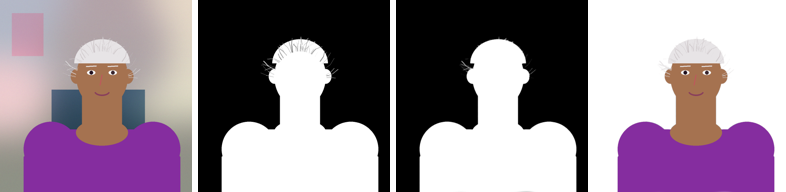

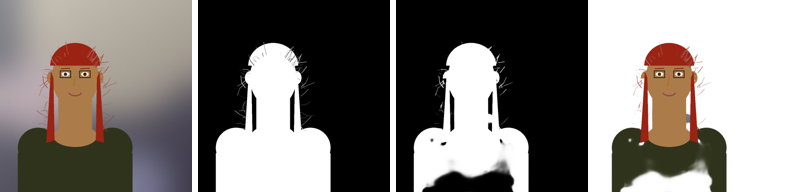

In [ ]:
import copy
import hashlib
import time

from PIL import Image

# MOD-M2: pipe.adapt trains pipe.model in place. The pinned weights are snapshotted once, before any training, and
# restored here and at the start of Section 6, so the frozen baseline and epoch 0 are always the frozen model.
def state_digest(state):
    digest = hashlib.sha256()
    for name in sorted(state):
        digest.update(name.encode('utf-8'))
        digest.update(state[name].detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()

def restore_frozen_weights():
    global _FROZEN_STATE, _FROZEN_DIGEST
    if '_FROZEN_STATE' not in globals():
        if pipe.adapter is not None:
            raise RuntimeError('pipe was adapted before the frozen snapshot was taken; restart the session and choose Run all.')
        _FROZEN_STATE = copy.deepcopy(pipe.model.state_dict())
        _FROZEN_DIGEST = state_digest(_FROZEN_STATE)
    pipe.model.load_state_dict(_FROZEN_STATE, strict=True)
    pipe.model.eval()
    pipe.adapter = None
    if state_digest(pipe.model.state_dict()) != _FROZEN_DIGEST:
        raise RuntimeError('restoring the frozen weights did not reproduce their digest')
    return _FROZEN_DIGEST

def matte_strip(record, mattes, tile=192):
    """One row to look at: the image, each matte in greyscale, then a cut-out on white with the last matte."""
    image = record['image'].astype(np.float32)
    tiles = [Image.fromarray(record['image'])]
    tiles += [Image.fromarray(np.clip(alpha * 255.0 + 0.5, 0, 255).astype(np.uint8)).convert('RGB') for alpha in mattes]
    cutout = mattes[-1][..., None] * image + (1.0 - mattes[-1][..., None]) * 255.0
    tiles.append(Image.fromarray(np.clip(cutout + 0.5, 0, 255).astype(np.uint8)))
    tiles = [t.convert('RGB').resize((tile, max(1, round(tile * t.height / t.width)))) for t in tiles]
    strip = Image.new('RGB', (len(tiles) * (tile + 6) - 6, max(t.height for t in tiles)), 'white')
    for i, t in enumerate(tiles):
        strip.paste(t, (i * (tile + 6), 0))
    return strip

def write_matte(record, alpha, tag):
    matte = Image.fromarray(np.clip(alpha * 255.0 + 0.5, 0, 255).astype(np.uint8))
    matte.save(f'outputs/modnet_matting_matte_' + tag + '_' + record['id'] + '.png')
    cutout = (alpha[..., None] * record['image'].astype(np.float32) + (1.0 - alpha[..., None]) * 255.0)
    Image.fromarray(np.clip(cutout + 0.5, 0, 255).astype(np.uint8)).save(f'outputs/modnet_matting_cutout_' + tag + '_' + record['id'] + '.png')

frozen_digest = restore_frozen_weights()
t0 = time.perf_counter()
frozen_test = pipe.evaluate(test_records)
frozen_val = pipe.evaluate(val_records)
print({'seconds': round(time.perf_counter() - t0, 1), 'metric': frozen_test['metric'], 'scored_model': 'frozen (pinned weights restored, sha256 ' + frozen_digest[:12] + '...)', 'adapted': frozen_test['adapted']})
print({'baselines_test': {k: {m: v[m] for m in ('mad', 'mse', 'sad', 'mad_unknown')} for k, v in frozen_test['baselines'].items()}})
print({'frozen_test': frozen_test['model']})
print({'frozen_validation': frozen_val['model']})
for row in frozen_test['per_image'][:5]:
    print({'portrait': row['id'], 'mad': row['mad'], 'mad_unknown': row['mad_unknown']})
shown_records = test_records[:2]
frozen_shown = pipe.predict(shown_records)
for record, pred in zip(shown_records, frozen_shown['predictions']):
    write_matte(record, pred['alpha'], 'frozen')
    write_matte(record, record['alpha'], 'reference')
    print({'portrait': record['id'], 'model_size': pred['model_size'], 'foreground_fraction_frozen': pred['foreground_fraction'], 'foreground_fraction_reference': round(float(record['alpha'].mean()), 4)})
print({'output': frozen_shown['output'], 'alpha_shape': frozen_shown['predictions'][0]['alpha'].shape, 'seconds': frozen_shown['seconds']})
print('columns: portrait | exact alpha | frozen matte | frozen cut-out on white')
for record, pred in zip(shown_records, frozen_shown['predictions']):
    display(matte_strip(record, [record['alpha'], pred['alpha']]))

<details><summary>Check your reasoning</summary>In the build record the frozen test MAD was 0.079, against 0.341 for all-background and 0.659 for all-foreground: far better than either constant, so the photographic model does find the drawn figures. It is not near zero because it drops parts of the drawn clothing and misses thin strands — look at the written frozen mattes beside the reference alphas. The unknown-band MAD (0.085 in the build record) is higher than the overall MAD because it is measured only where the matte is hard.</details>

## 6. Bounded fine-tuning of the matting branches

`pipe.adapt` trains the low-resolution branch's SE block and convolutions, the high-resolution branch and the fusion branch (4.26 M parameters — 66 % of the model) and nothing else: the MobileNetV2 backbone is frozen (no gradient is stored for it), and every BatchNorm layer keeps its running statistics, as the upstream adaptation code does. Each step takes four portraits with a seeded horizontal flip, derives the trimap from the reference alpha, and minimises the upstream supervised objective — the semantic loss (MSE against the blurred 1/16 matte, ×10), the detail loss (L1 in the unknown band, ×10) and the matte loss (L1 plus a compositional L1 with the unknown band weighted 4×) — with Adam at a small fixed learning rate and gradient-norm clipping. Epoch 0 records the frozen model's validation loss and metrics; the epoch with the lowest validation loss is kept.

Watch the validation loss: in the build record it fell from 0.80 to about 0.06 by epoch 4 and drifted afterwards, and the validation MAD from 0.064 to about 0.004. Six epochs (72 steps) take about 15 s on a T4 and about 3 minutes on a laptop CPU. `TRAINABLE = 'full'` also unfreezes the backbone (6.49 M parameters). The cell snapshots the pinned weights once, before any training, and restores them at the start of every run, so changing a field and running it again is a fresh adaptation of the frozen model, never a continuation of the previous one.

**Predict before running:** will the validation loss keep falling for all six epochs? Which epoch do you expect to be kept?

In [ ]:
EPOCHS = 6  # @param {type:"integer"}
LEARNING_RATE = 1e-4  # @param {type:"number"}
BATCH_SIZE = 4  # @param {type:"integer"}
TRAINABLE = 'branches'  # @param ["branches", "full"]

def report(entry):
    row = {'epoch': entry['epoch'], 'train_loss': None if entry['train_loss'] is None else round(entry['train_loss'], 4), 'val_loss': round(entry['val_loss'], 4)}
    if 'train_loss_parts' in entry:
        row['parts'] = entry['train_loss_parts']
    if 'val' in entry:
        row['val_mad'] = entry['val']['mad']
        row['val_mad_unknown'] = entry['val']['mad_unknown']
    if 'note' in entry:
        row['note'] = entry['note']
    print(row)

# SWP-F / MOD-M2: every run of this cell restarts from the pinned frozen weights (restore_frozen_weights, Section 5),
# so a re-run with other hyperparameters never stacks on the previous adaptation and epoch 0 really is the frozen model.
print({'restarted_from_frozen_weights': True, 'frozen_state_sha256': restore_frozen_weights()[:16] + '...', 'adapted': pipe.adapter is not None})

t0 = time.perf_counter()
adapt_result = pipe.adapt(train_records, val_records, epochs=EPOCHS, lr=LEARNING_RATE, batch_size=BATCH_SIZE, trainable=TRAINABLE, progress=report)
adapt_seconds = round(time.perf_counter() - t0, 1)
print({'trainable_parameters': adapt_result['n_trainable'], 'total_parameters': adapt_result['n_total'], 'steps': adapt_result['n_steps'], 'best_epoch': adapt_result['best_epoch'], 'losses': adapt_result['losses'], 'batchnorm': adapt_result['batchnorm'], 'seconds': adapt_seconds})

{'restarted_from_frozen_weights': True, 'frozen_state_sha256': '39d608640edcd93f...', 'adapted': False}


{'epoch': 0, 'train_loss': None, 'val_loss': 0.8013, 'val_mad': 0.064013, 'val_mad_unknown': 0.0913, 'note': 'frozen model'}


{'epoch': 1, 'train_loss': 0.1601, 'val_loss': 0.1723, 'parts': {'semantic': 0.0503, 'detail': 0.0615, 'matte': 0.0482}, 'val_mad': 0.012968, 'val_mad_unknown': 0.031512}


{'epoch': 2, 'train_loss': 0.0934, 'val_loss': 0.0967, 'parts': {'semantic': 0.023, 'detail': 0.0409, 'matte': 0.0294}, 'val_mad': 0.006422, 'val_mad_unknown': 0.020327}


{'epoch': 3, 'train_loss': 0.0636, 'val_loss': 0.0845, 'parts': {'semantic': 0.013, 'detail': 0.0302, 'matte': 0.0205}, 'val_mad': 0.005983, 'val_mad_unknown': 0.01999}


{'epoch': 4, 'train_loss': 0.0561, 'val_loss': 0.0594, 'parts': {'semantic': 0.0105, 'detail': 0.027, 'matte': 0.0186}, 'val_mad': 0.004037, 'val_mad_unknown': 0.016731}


{'epoch': 5, 'train_loss': 0.0558, 'val_loss': 0.0583, 'parts': {'semantic': 0.0133, 'detail': 0.0249, 'matte': 0.0176}, 'val_mad': 0.004021, 'val_mad_unknown': 0.01597}


{'epoch': 6, 'train_loss': 0.0477, 'val_loss': 0.0892, 'parts': {'semantic': 0.0087, 'detail': 0.0232, 'matte': 0.0157}, 'val_mad': 0.00653, 'val_mad_unknown': 0.017984}
{'trainable_parameters': 4263203, 'total_parameters': 6487075, 'steps': 72, 'best_epoch': 5, 'losses': 'upstream supervised losses: semantic (×10), detail (×10), matte L1 + compositional (×1); trimap grown 8 px from the fractional alpha', 'batchnorm': 'running statistics frozen (eval mode) during adaptation', 'seconds': 31.1}


<details><summary>Check your reasoning</summary>In the build record the validation loss fell from 0.80 (epoch 0, the frozen model) to about 0.06 by epoch 4 and then drifted slightly, so the kept epoch was not the last one: selection is by validation loss, and epoch 0 is a candidate, so the procedure can never keep a model that is worse on validation than the frozen one. 48 portraits at batch size 4 is 12 steps per epoch, 72 for six epochs. The cell first restores the frozen weights, so running it again with another `EPOCHS` or `TRAINABLE` starts from the same pinned model.</details>

## 7. Held-out evaluation: the paired comparison

The test portraits were never used for training or epoch selection (they come from their own seed range). The adapted model is scored exactly as the frozen model was in Section 5, and the table puts the baselines, the frozen and the adapted numbers side by side. The cell asserts what the procedure guarantees — the kept epoch's validation loss is no higher than the frozen model's, and re-scoring the validation portraits reproduces the kept epoch's MAD within 0.001 — and it **reports** (rather than asserts) whether the adapted test MAD is below the frozen one, as the verdict `improved`, `no gain` or `worse`, so a run on your own data that does not improve still writes its report and exports: on drawn portraits the domain shift is large enough that the build record moved the test MAD from 0.079 to 0.004 (unknown-band MAD 0.085 → 0.025) on every hyperparameter probe, so anything but `improved` on the default path is a finding, not noise. The size of the gain, and its reading — the model learned the drawing style, on 48 portraits, with one seed and no dispersion estimate — is not a quality claim about photographs; with your own portraits the gap between frozen and adapted is the number to watch.

**Predict before running:** which will improve more after fine-tuning — the overall test MAD or the unknown-band MAD?

In [ ]:
adapted_test = pipe.evaluate(test_records)
adapted_val = pipe.evaluate(val_records)
comparison = {}
for key in ('mad', 'mse', 'sad', 'mad_unknown'):
    comparison[key] = {'all_background': frozen_test['baselines']['all_background'][key], 'all_foreground': frozen_test['baselines']['all_foreground'][key], 'frozen': frozen_test['model'][key], 'adapted': adapted_test['model'][key]}
for key, row in comparison.items():
    print({key: row})
best = adapt_result['history'][adapt_result['best_epoch']]
print({'validation_mad': {'frozen': frozen_val['model']['mad'], 'adapted': adapted_val['model']['mad']}, 'validation_loss': {'frozen': adapt_result['history'][0]['val_loss'], 'kept_epoch': best['val_loss']}})
evaluation_report = {
    'model': {'id': MODEL_ID, 'revision': MODEL_REVISION, 'key': MODEL_KEY},
    'data_source': data_source,
    'dataset': dataset_report,
    'frozen': {'test': frozen_test, 'validation': frozen_val},
    'adapted': {'test': adapted_test, 'validation': adapted_val},
    'comparison': comparison,
    'adaptation': {k: v for k, v in adapt_result.items() if k not in ('history', 'trainable_names')},
    'history': adapt_result['history'],
    'adaptation_seconds': adapt_seconds,
}
delta_mad = adapted_test['model']['mad'] - frozen_test['model']['mad']
adaptation_verdict = 'improved' if delta_mad < 0 else ('no gain' if delta_mad == 0 else 'worse')
evaluation_report['verdicts'] = {'adapted_vs_frozen_test_mad': adaptation_verdict, 'delta_mad': round(delta_mad, 6)}
with open('outputs/modnet_matting_evaluation_report.json', 'w', encoding='utf-8') as f:
    json.dump(evaluation_report, f, indent=2)
assert best['val_loss'] <= adapt_result['history'][0]['val_loss']
assert abs(adapted_val['model']['mad'] - best['val']['mad']) < 1e-3
print({'verdict': adaptation_verdict, 'delta_test_mad': round(delta_mad, 6), 'report': 'outputs/modnet_matting_evaluation_report.json'})
if adaptation_verdict != 'improved':
    print('The adapted model did not beat the frozen one on the held-out test split; the report, export and reload still run. Read the baselines and the history before trusting either model.')

{'mad': {'all_background': 0.341011, 'all_foreground': 0.658989, 'frozen': 0.079384, 'adapted': 0.003505}}
{'mse': {'all_background': 0.337618, 'all_foreground': 0.655596, 'frozen': 0.074834, 'adapted': 0.00104}}
{'sad': {'all_background': 89.3939, 'all_foreground': 172.7501, 'frozen': 20.81, 'adapted': 0.9188}}
{'mad_unknown': {'all_background': 0.515016, 'all_foreground': 0.484984, 'frozen': 0.085393, 'adapted': 0.023451}}
{'validation_mad': {'frozen': 0.064013, 'adapted': 0.004021}, 'validation_loss': {'frozen': 0.8013108372688293, 'kept_epoch': 0.058306233336528145}}
{'verdict': 'improved', 'delta_test_mad': -0.075879, 'report': 'outputs/modnet_matting_evaluation_report.json'}


<details><summary>Check your reasoning</summary>In the build record the test MAD moved from 0.079 to 0.004 and the unknown-band MAD from 0.085 to 0.025. The overall gain is large because the domain gap — drawn figures — is large and easy to learn from 48 examples; the unknown-band number is the honest one for matting, and it improved less. One seed and 20 test portraits give no dispersion estimate. The verdict line reports `improved`, `no gain` or `worse` instead of stopping the notebook, so a BYOD run that does not improve still exports and records its result.</details>

## 8. Adapted mattes, an optional photograph of your own, artifact export and fresh reload

The adapted model mattes the same two held-out portraits as Section 5; their adapted mattes and cut-outs are written next to the frozen ones and the exact alphas, the per-portrait MAD before and after is printed, and each portrait is shown as one row: the portrait, its exact alpha, the frozen matte, the adapted matte and the adapted cut-out. Set `USE_BYOD_PHOTO = True` and `BYOD_PHOTO_PATH` (an image already in the runtime; on Colab an empty path opens an upload dialog) to matte one photograph of your own (JPEG or PNG; it is downscaled once to 1536 pixels on the long side and never leaves this runtime): the frozen and the adapted model both matte it, the two mattes and cut-outs are written (a missing, cancelled, misnamed or unreadable photograph stops with one `Refused: <file>: <reason>` line and removes the earlier photograph results first), and the mean absolute difference between them is printed — an unlabelled sanity check on whether learning the drawing style moved the model on a real portrait, not an evaluation. The default path uploads nothing.

`pipe.save_artifact` writes the trained tensors (about 17 MB) as `adapter.safetensors`, with a `manifest.json` recording the artifact format, the base model id and revision, the digest of the converted base file, the adaptation scope, the tensor names, the file size and SHA-256, the training configuration and the epoch history (OUT8). `ModNetMattingPipeline.from_artifact` re-verifies the base file, checks the artifact manifest, scope and digest **before** deserialising, rebuilds the model and overlays the tensors — a fresh object from files, not the in-memory model (VER2). The cell asserts the same held-out MAD within 0.0001 and mattes within 0.001 (VER4).

{'portrait': 'portrait-02000', 'mad_frozen': 0.0027, 'mad_adapted': 0.0026}
{'portrait': 'portrait-02001', 'mad_frozen': 0.0472, 'mad_adapted': 0.0019}
columns: portrait | exact alpha | frozen matte | adapted matte | adapted cut-out on white


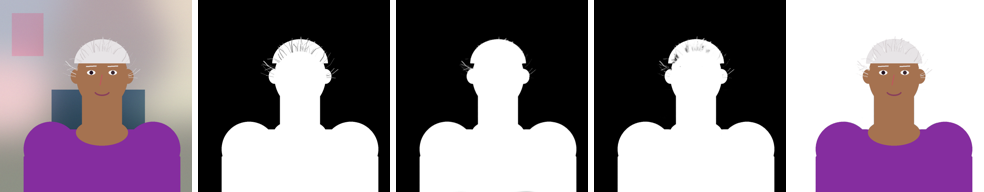

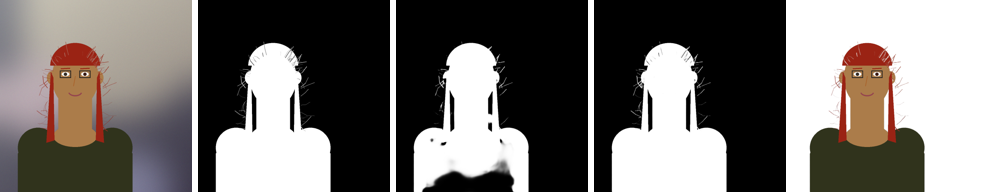

{'artifact': 'outputs/modnet_matting_adapter', 'format': 'org.valcorza.modnet-matting.adapter.v1', 'trainable': 'branches', 'tensors': 76, 'bytes': 17060652, 'sha256': 'edd17a76c51320d6...'}


{'reload_parity': {'mad_diff': 0.0, 'metrics_identical': True, 'max_abs_matte_diff': 0.0}, 'reloaded_best_epoch': 5}
outputs/:
  - outputs/modnet_matting_adapter/adapter.safetensors (16660.8 KB)
  - outputs/modnet_matting_adapter/manifest.json (7.1 KB)
  - outputs/modnet_matting_cutout_adapted_portrait-02000.png (21.5 KB)
  - outputs/modnet_matting_cutout_adapted_portrait-02001.png (26.4 KB)
  - outputs/modnet_matting_cutout_frozen_portrait-02000.png (21.4 KB)
  - outputs/modnet_matting_cutout_frozen_portrait-02001.png (39.7 KB)
  - outputs/modnet_matting_cutout_reference_portrait-02000.png (17.3 KB)
  - outputs/modnet_matting_cutout_reference_portrait-02001.png (22.7 KB)
  - outputs/modnet_matting_evaluation_report.json (19.0 KB)
  - outputs/modnet_matting_matte_adapted_portrait-02000.png (10.1 KB)
  - outputs/modnet_matting_matte_adapted_portrait-02001.png (11.5 KB)
  - outputs/modnet_matting_matte_frozen_portrait-02000.png (8.1 KB)
  - outputs/modnet_matting_matte_frozen_portrait-02

In [ ]:
import platform
import shutil

USE_BYOD_PHOTO = False  # @param {type:"boolean"}
BYOD_PHOTO_PATH = ''  # @param {type:"string"}

adapted_shown = pipe.predict(shown_records)
for record, before, after in zip(shown_records, frozen_shown['predictions'], adapted_shown['predictions']):
    write_matte(record, after['alpha'], 'adapted')
    print({'portrait': record['id'], 'mad_frozen': round(float(np.abs(before['alpha'] - record['alpha']).mean()), 4), 'mad_adapted': round(float(np.abs(after['alpha'] - record['alpha']).mean()), 4)})
print('columns: portrait | exact alpha | frozen matte | adapted matte | adapted cut-out on white')
for record, before, after in zip(shown_records, frozen_shown['predictions'], adapted_shown['predictions']):
    display(matte_strip(record, [record['alpha'], before['alpha'], after['alpha']]))
photo_report = None
if USE_BYOD_PHOTO:
    # DAT20: a missing, cancelled, misnamed or unreadable photograph stops here as one Refused: line.
    photo_name = (Path(BYOD_PHOTO_PATH.strip()).name or BYOD_PHOTO_PATH.strip()) if BYOD_PHOTO_PATH.strip() else '(no file)'
    try:
        photo_path = byod_file(BYOD_PHOTO_PATH, 'photograph (JPEG or PNG)', ('.jpg', '.jpeg', '.png'))
        photo_name = photo_path.name
        photo = load_photo(photo_path, record_id='own-photograph')
    except BYODRefusal as exc:
        refuse_byod(exc.file_name, exc.reason, PHOTO_RESULT_NAMES, PHOTO_OUTPUTS)
    except (ValueError, OSError) as exc:
        refuse_byod(photo_name, f'{type(exc).__name__}: {exc}', PHOTO_RESULT_NAMES, PHOTO_OUTPUTS)
    frozen_photo = ModNetMattingPipeline.from_pretrained(weights_dir=WEIGHTS_DIR, device=pipe.device).predict([photo])['predictions'][0]
    adapted_photo = pipe.predict([photo])['predictions'][0]
    write_matte(photo, frozen_photo['alpha'], 'frozen')
    write_matte(photo, adapted_photo['alpha'], 'adapted')
    photo_report = {'source': photo['source'], 'original_size': photo['original_size'], 'loaded_size': photo['loaded_size'], 'model_size': adapted_photo['model_size'], 'foreground_fraction_frozen': frozen_photo['foreground_fraction'], 'foreground_fraction_adapted': adapted_photo['foreground_fraction'], 'mean_abs_matte_difference': round(float(np.abs(adapted_photo['alpha'] - frozen_photo['alpha']).mean()), 4), 'note': 'no label; sanity check'}
    print({'own_photograph': photo_report})
    print('columns: photograph | frozen matte | adapted matte | adapted cut-out on white')
    display(matte_strip(photo, [frozen_photo['alpha'], adapted_photo['alpha']]))
with open('outputs/modnet_matting_predictions.json', 'w', encoding='utf-8') as f:
    json.dump({'model': adapted_shown['model'], 'output': adapted_shown['output'], 'shown_portraits': [{'id': r['id'], 'frozen': {k: v for k, v in b.items() if k != 'alpha'}, 'adapted': {k: v for k, v in a.items() if k != 'alpha'}} for r, b, a in zip(shown_records, frozen_shown['predictions'], adapted_shown['predictions'])], 'own_photograph': photo_report}, f, indent=2)

artifact_dir = Path('outputs/modnet_matting_adapter')
shutil.rmtree(artifact_dir, ignore_errors=True)
pipe.save_artifact(artifact_dir, metadata={'tutorial': 'modnet_matting', 'data_source': data_source})
artifact_manifest = json.loads((artifact_dir / 'manifest.json').read_text(encoding='utf-8'))
print({'artifact': str(artifact_dir), 'format': artifact_manifest['format'], 'trainable': artifact_manifest['adapter']['trainable'], 'tensors': len(artifact_manifest['tensors']), 'bytes': artifact_manifest['files'][0]['bytes'], 'sha256': artifact_manifest['files'][0]['sha256'][:16] + '...'})

reloaded = ModNetMattingPipeline.from_artifact(artifact_dir, weights_dir=WEIGHTS_DIR, device=pipe.device)
reloaded_test = reloaded.evaluate(test_records)
before = pipe.predict(test_records[:2])['predictions']
after = reloaded.predict(test_records[:2])['predictions']
parity = {'mad_diff': round(abs(reloaded_test['model']['mad'] - adapted_test['model']['mad']), 6), 'metrics_identical': reloaded_test['model'] == adapted_test['model'], 'max_abs_matte_diff': max(float(np.abs(a['alpha'] - b['alpha']).max()) for a, b in zip(before, after))}
print({'reload_parity': parity, 'reloaded_best_epoch': reloaded.adapter['best_epoch']})
assert parity['mad_diff'] < 1e-4 and parity['max_abs_matte_diff'] < 1e-3

result_payload = {
    'notebook_source': NOTEBOOK_SOURCE,
    'repository_revision': NOTEBOOK_SOURCE['repository_revision'],
    'model': {**evaluation_report['model'], 'model_license': MODEL_LICENSE, 'device': pipe.device, 'source': pipe.source},
    'provenance': {
        'source_asset': [e for e in MANIFEST['files'] if e['path'] == SOURCE_CKPT_NAME],
        'source_drive_file_id': SOURCE_DRIVE_FILE_ID,
        'upstream_code_commit': UPSTREAM_CODE_COMMIT,
        'pickle_audit_sha256': PICKLE_AUDIT_SHA256,
        'converted': verify_converted(WEIGHTS_DIR)['files'],
        'pickle_unpickled_once_for_conversion': True,
        'served_from_pickle': False,
        'remote_code_executed': False,
        'labelled_data': SAMPLE_LABEL_SOURCE,
        'photographs_downloaded': 0,
    },
    'runtime': {'python': platform.python_version(), 'torch': torch.__version__, 'pillow': PIL.__version__, 'numpy': np.__version__},
    'data_source': data_source,
    'comparison': comparison,
    'own_photograph': photo_report,
    'artifact': {'dir': str(artifact_dir), 'sha256': artifact_manifest['files'][0]['sha256'], 'bytes': artifact_manifest['files'][0]['bytes']},
    'reload_parity': parity,
}
with open('outputs/modnet_matting_result.json', 'w', encoding='utf-8') as f:
    json.dump(result_payload, f, indent=2)

print('outputs/:')
for path in sorted(Path('outputs').rglob('*')):
    if path.is_file():
        print(f'  - {path.as_posix()} ({path.stat().st_size / 1024:.1f} KB)')

## Interpretation and limits

On 20 held-out drawn portraits the photographic MODNet checkpoint reaches a MAD near 0.08 against constant baselines of 0.34 and 0.66, and a bounded fine-tuning of its matting branches on 48 drawn portraits, selected by validation loss with the frozen model as a candidate, brings it near 0.004. That is the claim: the adaptation contract runs end to end on labelled portrait/alpha pairs, the pickle is audited and converted rather than served, and the artifact that carries the change is about 17 MB and reloads with the same outputs. It is not a claim about matting quality on photographs — the portraits are drawings, chosen because no photographic matting dataset with alpha mattes is both permissively licensed and free of personal-data concerns and because public-domain photographs cannot be fetched reliably from shared cloud runtimes — and the default path never sees a photograph; the photograph gate is a sanity check without a label, not an evaluation.

The numbers are sample-sanity evidence: one seeded run, 20 test portraits from one renderer, no dispersion estimate, and a domain gap (drawn figures) that makes the gain large by construction. Nothing here measures the model on the PPM-100 benchmark, on video, on group portraits, on hands and objects held in front of the body, or on the hair detail that matting is judged on in practice.

Three things to carry to real data. **The alpha is the contract, and it must belong to the image:** an alpha drawn for another crop, or a binary mask passed off as a matte, is trained on without complaint. **Watch a real photograph after adaptation:** fine-tuning on a narrow domain moves the model everywhere; in the build record the adapted model took in dark background beside the subject of a real portrait it had matted cleanly before, and the photograph gate exists to show that on your own image. **Read the baselines first:** on a close-up where the subject fills 84 % of the frame the all-foreground matte already scores a MAD of 0.16; only the unknown-band MAD says whether the model resolved the boundary.

Successful execution proves that the recorded repository revision's pipeline modules, carried in this standalone notebook, can acquire and digest-verify a pickled upstream checkpoint, audit and convert it into safetensors without executing anything outside the audited allow-list, build the vendored architecture and load it strictly, render and validate labelled portraits, execute bounded fine-tuning, evaluate against constant baselines and the frozen model on held-out portraits, and emit the shown machine-readable artifacts — without the repository being reachable and without downloading any image. It does **not** establish benchmark superiority, production fitness, or matting skill on photographs beyond the checks shown.

**Optional experiments (they do not affect the default path):** set `TRAINABLE = 'full'` and compare; raise `EPOCHS` and watch the validation loss drift; try `LEARNING_RATE = 5e-5`; matte a photograph of your own through `USE_BYOD_PHOTO`; or bring your own labelled portraits through BYOD and read the baselines before the adapted number. Re-running Section 6 restarts from the frozen weights (and re-running Section 5 scores the frozen model, never an adapted one), then run Sections 7 and 8 again; each run replaces the default report and adapter.

## Troubleshooting

- **Section 1 stops with "This notebook needs a Linux x86_64 runtime"** — use Google Colab, Kaggle or a Linux x86_64 Jupyter server.
- **The uv wheel fails its size/SHA-256 check, or a download in Section 1 times out** — run Section 1 again; a complete environment is reused and an incomplete one is finished. If it repeats, `files.pythonhosted.org` or `pypi.org` is blocked or altered.
- **You re-ran Section 1 on its own** — nothing is lost: it keeps the running worker and every variable. After a session restart, run from the top.
- **"The isolated environment's Python process exited"** — usually out of memory; restart the session and choose **Run all**.
- **Section 3 refuses the checkpoint (size, SHA-256 or audit mismatch) or cannot reach the Hub** — the message names the file. Delete the folder Section 3 prints as `weights_dir` and run Section 3 again; never bypass the audit.
- **Section 7 prints a verdict other than `improved`** — on the default path that is a finding worth recording; on your own data, check the baselines, the history and whether the alphas belong to the images.
- **CUDA out of memory in Section 6** — set `BATCH_SIZE = 2` and run Sections 6–8 again (numbers will differ from the build record).
- **BYOD: "BYOD path … does not exist"** — the path is relative to the working directory printed in the message.
- **BYOD: "the upload dialog exists only in Google Colab"** — on Kaggle or Jupyter, copy the file into the runtime and set `BYOD_PATH` / `BYOD_PHOTO_PATH`.
- **BYOD: "Upload exactly one …"** — the dialog was cancelled or several files were chosen; run the cell again.
- **BYOD: "… labelled pairs give a training split of …; supply at least 6 pairs"** — the split needs four training portraits; add pairs (more than the minimum: with fewer than five test portraits the held-out numbers are anecdotes).
- **BYOD: a refusal from `load_byod_dataset` or `validate_dataset`** — it names the `pairs.csv` row, the member or the rule (size, alpha range, all-background); fix that pair.

## Glossary

- **Alpha matte** — per-pixel opacity of the subject in [0, 1]; fractional along hair and soft edges, unlike a binary mask.
- **Trimap / unknown band** — a map of sure background, sure foreground and the uncertain band between them; here the band is every fractional-alpha pixel grown by 8 pixels.
- **Trimap-free matting** — predicting the matte from the image alone, as MODNet does.
- **MAD / MSE / SAD** — mean absolute difference, mean squared error and summed absolute difference (÷ 1000) between predicted and reference alpha.
- **Constant baselines** — the all-background and all-foreground mattes; all-background MAD equals the foreground fraction.
- **Semantic / detail / matte loss** — the upstream training objective's three parts: coarse subject, boundary detail, final matte (with a compositional term).
- **Matting branches / backbone** — the trainable low-resolution, high-resolution and fusion branches, and the frozen MobileNetV2 feature extractor.
- **BatchNorm statistics frozen** — the running means and variances are not updated by small training batches.
- **Epoch / validation selection** — one pass over the training portraits; keeping the epoch with the lowest validation loss (epoch 0, the frozen model, included).
- **Held-out test split** — portraits never used for training or selection; the numbers to report.
- **Pickle / safetensors** — an executable Python serialisation (audited and converted once here) and a tensor-only format (what the model loads).
- **Adapter / reload parity** — the trained tensors only, overlaid on the pinned base; reloading them from disk gives the same mattes.
- **BYOD** — bring your own data: your labelled portraits or a photograph through the same cells.

## Conclusion (your notes)

Optional — fill in from **your** run:

- The frozen test MAD was ___ against baselines of ___ (all-background) and ___ (all-foreground).
- Fine-tuning kept epoch ___; the test MAD moved to ___ and the unknown-band MAD from ___ to ___; the verdict was ___.
- On my own photograph (if any) the adapted matte differed from the frozen one by ___ because ___.
- One reason not to trust this gain on real portraits yet: ___.

## References

- Repository README: https://github.com/kurtvalcorza/modnet-matting-pipeline/blob/main/README.md
- Repository model card: https://github.com/kurtvalcorza/modnet-matting-pipeline/blob/main/MODEL_CARD.md
- Weights, provenance and conversion notes: https://github.com/kurtvalcorza/modnet-matting-pipeline/blob/main/docs/WEIGHTS.md
- Hugging Face mirror of the checkpoint: https://huggingface.co/XM5354/Modnet_models (revision `71aca6d04ed0267b4b12bde776868f2b9fb1d06f`; byte-identical to the authors' Google Drive release)
- Upstream repository (code, models and demos, Apache-2.0): https://github.com/ZHKKKe/MODNet
- Ke, Z., Sun, J., Li, K., Yan, Q., Lau, R. W. H. (2022). MODNet: Real-Time Trimap-Free Portrait Matting via Objective Decomposition. AAAI 2022. arXiv:2011.11961: https://arxiv.org/abs/2011.11961
- DIMER Notebook Specification 2.2 and Model Card Specification 1.1 (fleet specs in the ml-worker repository)